# Soil grain size — CNN on physically calibrated tiles (LOSO)

Pipeline: photo → px/mm of *this* photo → resample to a common px/mm → hard grid of fixed-mm tiles (cached once)
→ CNN per tile → average tiles per photo → average photos per sample → EMD.

Settings: **GPU T4, Internet ON** (pretrained weights + `pip install lightning`).

In [1]:
# Lightning isn't preinstalled on the Kaggle image: the first run needs Internet ON
import importlib.util, subprocess, sys
if importlib.util.find_spec("lightning") is None:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "lightning"], check=True)

In [2]:
import json
import logging
import re
import time
import warnings
from concurrent.futures import ProcessPoolExecutor
from datetime import datetime
from pathlib import Path
from types import SimpleNamespace
import gc
import itertools
import math
import os

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from torch.optim import AdamW, SGD
from torch.optim.lr_scheduler import LambdaLR
from PIL import Image, ImageOps, ExifTags
import albumentations as A
from albumentations.pytorch import ToTensorV2
import timm
import lightning as L
from lightning.pytorch.callbacks import LearningRateMonitor
from lightning.pytorch.loggers import CSVLogger
from tqdm.auto import tqdm

# Lightning prints device info / tips for every fold's Trainer: keep only real problems
logging.getLogger("lightning.pytorch").setLevel(logging.ERROR)
logging.getLogger("lightning.fabric").setLevel(logging.ERROR)
warnings.filterwarnings("ignore", message=r".*LeafSpec")
# AMP skips the very first optimizer step (inf check) -> harmless scheduler-order warning
warnings.filterwarnings("ignore", message=r"Detected call of `lr_scheduler\.step\(\)`")
Image.MAX_IMAGE_PIXELS = None   # 48 MP+ photos


class CFG:
    DIR = Path("/kaggle/input/competitions/soil-grain-size-from-photos")
    TRAIN_IMG = DIR / "Training-All_Photos_updated" / "Training-All_Photos_updated"
    TEST_IMG = DIR / "Test_All_Photos" / "Test_All_Photos"
    OUTPUT_DIR = Path("/kaggle/working")
    TILE_DIR = OUTPUT_DIR / "tiles"          # tiles are cut once and reused by every run
    FEAT_DIR = OUTPUT_DIR / "features"       # frozen-backbone features, one file per backbone x tile size
    EXP_DIR = OUTPUT_DIR / "experiments"     # one folder per run + registry.csv

    SEED = 42
    DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
    NUM_WORKERS = 4

    # physical tiling: every photo -> PX_PER_MM, hard grid of TILE_SIZES px; tile_mm = tile_px / PX_PER_MM
    PX_PER_MM = 4            # train Motorola photos are ~4.6 px/mm: 4 never upsamples them
    TILE_SIZES = (224, 384)  # 56 mm and 96 mm
    TILE_WORKERS = 4

    FEAT_EPOCHS = 60         # frozen backbone: head trained on cached features (seconds per fold)
    EPOCHS = 10              # fine-tuning on tile images
    WARMUP_EPOCHS = 1
    FEAT_BATCH_SIZE = 256
    BATCH_SIZE = 64
    LR = 1e-3                # head
    BACKBONE_LR = 1e-5       # only when the backbone is trained
    WEIGHT_DECAY = 1e-4      # not applied to biases / norm parameters
    PRINT_EVERY = 20

    MEAN = (0.485, 0.456, 0.406)
    STD = (0.229, 0.224, 0.225)
    GRAIN_COLS = ["0.002", "0.0063", "0.02", "0.063", "0.2", "0.63", "2", "6.3", "20", "63", "200"]

CFG.QUICK = False       # True = смоук-тест: максимум 2 епохи на прогін
CFG.BUDGET_H = 10.0     # новий експеримент не стартує, якщо не вкладається в цей час
CFG.SUB_N = 8           # скільки фолдів у абляціях (підмножина з 24)
CFG.CLEAN_TEMP = True   # в кінці видалити тимчасові тайли

for d in (CFG.TILE_DIR, CFG.FEAT_DIR, CFG.EXP_DIR):
    d.mkdir(parents=True, exist_ok=True)
L.seed_everything(CFG.SEED, verbose=False)
print(CFG.DEVICE, torch.cuda.get_device_name(0) if CFG.DEVICE == "cuda" else "")

cuda Tesla T4


In [3]:
# ===== helpers: time budget, fault-tolerant runner, context managers =====
from contextlib import contextmanager, ExitStack, nullcontext
import traceback

T0 = time.time()
AUX_PREFIX = ("sub_", "de_", "ctrl_", "ppm")     # runs that are NOT part of the main 24-fold leaderboard / ensembles


def elapsed_h():
    return (time.time() - T0) / 3600


def have_time(need_h=0.0):
    return elapsed_h() + need_h < CFG.BUDGET_H


def safe(label, fn, need_h=0.0):
    """Run one experiment. A failure (or an exhausted time budget) never stops the notebook."""
    if not have_time(need_h):
        print(f"[SKIPPED: time budget] {label} (elapsed {elapsed_h():.1f} h, needs ~{need_h:.1f} h)")
        return None
    print(f"[start] {label} | elapsed {elapsed_h():.2f} h")
    try:
        return fn()
    except Exception:
        print(f"[FAILED] {label}")
        traceback.print_exc()
        gc.collect()
        if torch.cuda.is_available():
            torch.cuda.empty_cache()
        return None


@contextmanager
def tmp_set(d, key, value):
    """Temporarily set d[key] = value (and restore / delete afterwards)."""
    had, old = key in d, d.get(key)
    d[key] = value
    try:
        yield
    finally:
        if had:
            d[key] = old
        else:
            d.pop(key, None)


def pooled(backbone, pool):
    return tmp_set(POOL, backbone, pool)


@contextmanager
def variant_tiles(new_index, subdir):
    """Temporarily replace the 224-px tile index (and the feature-cache folder) by a variant (colour-normalised,
    perturbed or different px/mm tiles)."""
    old_idx, old_feat = TILE_INDEX[224], CFG.FEAT_DIR
    TILE_INDEX[224] = new_index
    CFG.FEAT_DIR = old_feat / subdir
    CFG.FEAT_DIR.mkdir(parents=True, exist_ok=True)
    try:
        yield
    finally:
        TILE_INDEX[224], CFG.FEAT_DIR = old_idx, old_feat

# Part 0 — data, devices and physical scale

`ppm_updated.csv` gives px/mm per **device at native resolution**. Training photos are stored downscaled and
without EXIF, so the scale of each photo is

`ppm_eff = ppm_native × stored long side / native long side`

The device comes from EXIF `Model` (test photos) or the file-name prefix (train photos).
The sample id is the token before the photo number: `Motorola_Edge_60_fusion_H374_01` → `H374`
(taking a fixed token position produced the bogus sample `60`).

In [4]:
IMG_EXTS = {".jpg", ".jpeg", ".png", ".tif", ".tiff", ".bmp"}
_UMLAUTS = {"ü": "ue", "Ü": "Ue", "ä": "ae", "Ä": "Ae", "ö": "oe", "Ö": "Oe"}
_EXIF = {v: k for k, v in ExifTags.TAGS.items()}


def norm_name(s):
    return re.sub(r"[^a-z0-9]", "", str(s).lower())


def parse_train_name(stem):
    """'Motorola_Edge_60_fusion_H374_01' -> ('Motorola_Edge_60_fusion', 'H374')"""
    tokens = stem.split("_")
    if len(tokens) < 3 or not tokens[-1].isdigit():
        return None
    return "_".join(tokens[:-2]), tokens[-2]


def parse_test_name(stem):
    """'<prefix>_HPC_Münster,BS6,9_0-10m (1)' -> ('<prefix>', 'HPC_Muenster_BS6_9_0-10m')"""
    idx = stem.find("HPC_")
    if idx == -1:
        return None
    sid = re.sub(r"\s*\(\d+\)$", "", stem[idx:])
    for a, b in _UMLAUTS.items():
        sid = sid.replace(a, b)
    return stem[:idx].strip("_ -"), sid.replace(",", "_")


def read_photo_meta(path):
    """Stored size (before EXIF rotation) + EXIF make/model/orientation, without decoding pixels."""
    with Image.open(path) as im:
        exif = im.getexif()
        return {"w": im.width, "h": im.height, "exif_make": exif.get(_EXIF["Make"]),
                "exif_model": exif.get(_EXIF["Model"]), "orientation": exif.get(_EXIF["Orientation"])}


def match_device(ppm_df, exif_model, name_device):
    by_camera = {norm_name(c): i for i, c in zip(ppm_df.index, ppm_df["camera"])}
    by_phone = {norm_name(p): i for i, p in zip(ppm_df.index, ppm_df["phone"])}
    for key, table in ((exif_model, by_camera), (name_device, by_phone),
                       (exif_model, by_phone), (name_device, by_camera)):
        if key and norm_name(key) in table:
            return table[norm_name(key)]
    return None


def build_photo_table():
    ppm_df = pd.read_csv(CFG.DIR / "ppm_updated.csv")
    rows = []
    for split, img_dir, parse in (("train", CFG.TRAIN_IMG, parse_train_name), ("test", CFG.TEST_IMG, parse_test_name)):
        for p in sorted(x for x in img_dir.rglob("*") if x.suffix.lower() in IMG_EXTS and x.is_file()):
            parsed = parse(p.stem)
            if parsed is None:
                warnings.warn(f"cannot parse sample id from {p.name}, skipped")
                continue
            name_device, sid = parsed
            meta = read_photo_meta(p)
            row = {"split": split, "sample_id": sid, "file": p.name, "path": str(p), "name_device": name_device, **meta}
            dev = match_device(ppm_df, meta["exif_model"], name_device)
            if dev is not None:
                d = ppm_df.loc[dev]
                row.update(device=d["phone"], native_w=int(d["width"]), native_h=int(d["height"]), ppm_native=float(d["ppm"]))
            rows.append(row)
    df = pd.DataFrame(rows)
    for col in ("device", "native_w", "native_h", "ppm_native"):
        if col not in df:
            df[col] = np.nan
    long_side, short_side = df[["w", "h"]].max(axis=1), df[["w", "h"]].min(axis=1)
    native_long, native_short = df[["native_w", "native_h"]].max(axis=1), df[["native_w", "native_h"]].min(axis=1)
    df["ppm_eff"] = df["ppm_native"] * long_side / native_long
    # a different aspect ratio means the stored photo was cropped, not only resized -> scale is uncertain
    df["aspect_ok"] = ((long_side / short_side) / (native_long / native_short) - 1).abs() < 0.02
    df["fov_long_mm"] = long_side / df["ppm_eff"]
    df["fov_short_mm"] = short_side / df["ppm_eff"]
    if df["device"].isna().any():
        warnings.warn(f"photos with unknown device (not tiled): {df.loc[df['device'].isna(), 'file'].tolist()[:5]}")
    if (df["device"].notna() & ~df["aspect_ok"]).any():
        warnings.warn("some photos have a non-native aspect ratio (cropped?): ppm_eff assumes a long-side resize")
    return df


LABELS = (pd.read_csv(CFG.DIR / "Training_labels_updated.csv", dtype={"sample_id": str})
          .set_index("sample_id")[CFG.GRAIN_COLS].astype(float))
sub_df = pd.read_csv(CFG.DIR / "sample_submission.csv", dtype={"sample_id": str})

photos = build_photo_table()
photos.to_csv(CFG.OUTPUT_DIR / "photos.csv", index=False)

train_sids = set(photos.loc[photos["split"] == "train", "sample_id"])
print(f"labelled samples with photos: {len(train_sids & set(LABELS.index))}/{len(LABELS)}"
      f" | labels without photos: {sorted(set(LABELS.index) - train_sids) or 'none'}"
      f" | photos without labels: {sorted(train_sids - set(LABELS.index)) or 'none'}")
missing_test = set(sub_df["sample_id"]) - set(photos.loc[photos["split"] == "test", "sample_id"])
print(f"test samples without photos: {missing_test or 'none'}")
display(photos.groupby(["split", "device", "w", "h"], dropna=False)
        .agg(photos=("file", "size"), samples=("sample_id", "nunique"), ppm_eff=("ppm_eff", "mean"),
             fov_long_mm=("fov_long_mm", "mean"), fov_short_mm=("fov_short_mm", "mean"),
             aspect_ok=("aspect_ok", "all")).round(2))

labelled samples with photos: 24/24 | labels without photos: none | photos without labels: none
test samples without photos: none


photos  samples  ppm_eff  \
split device                  w    h                                
test  iPhone 14               4032 3024      14        3    13.94   
      iPhone 16               5712 4284      21        7    19.52   
train Motorola Edge           720  1600      25       18     4.60   
                              1600 720       44       20     4.60   
      Motorola Edge 60 Fusion 4096 2304       3        1    12.46   
      Samsung A52             1599 1200      55       22     4.55   

                                         fov_long_mm  fov_short_mm  aspect_ok  
split device                  w    h                                           
test  iPhone 14               4032 3024       289.20        216.90       True  
      iPhone 16               5712 4284       292.55        219.41       True  
train Motorola Edge           720  1600       348.07        156.63       True  
                              1600 720        348.07        156.63       True  
      Motorola Edge 60 Fusion 4096 2304       328.60        184.84       True  
      Samsung A52             1599 1200       351.23        263.59       True

## Metric

EMD on the log-diameter grid = L1 between cumulative curves weighted by the log-widths of the sieve bins.
All bins are ≈ 0.5 decades wide, so EMD ≈ 0.5 × Σ|Δ| over sieves 2…11 (the 0.002 mm sieve never enters the
metric). A pure scale error shifts the curve along log d: a factor-*k* error costs 100·|log10 k|
(×2 → 30.1). Complementary metric: |log10 D_p(pred) − log10 D_p(true)| for D10/D30/D50/D60
(0.301 = factor-2 error in that characteristic grain size).

In [5]:
DIAMETERS = np.array([float(c) for c in CFG.GRAIN_COLS])
LOG_D = np.log10(DIAMETERS)
LOG_WIDTHS = np.diff(LOG_D)
UNIFORM_CURVE = np.array([9.09, 18.18, 27.27, 36.36, 45.45, 54.55, 63.64, 72.73, 81.82, 90.91, 100.0])


def _2d(a):
    a = np.asarray(a, dtype=np.float64)
    return a[np.newaxis] if a.ndim == 1 else a


def emd_per_sample(y_true, y_pred):
    y_true, y_pred = _2d(y_true), _2d(y_pred)
    return (np.abs(y_true[:, 1:] - y_pred[:, 1:]) * LOG_WIDTHS).sum(axis=1)


def emd_score(y_true, y_pred):
    return float(emd_per_sample(y_true, y_pred).mean())


def enforce_monotone(arr):
    arr = np.maximum.accumulate(np.clip(_2d(arr).copy(), 0, 100), axis=1)
    arr[:, -1] = 100.0
    return arr


def d_value(curve, p):
    """Diameter (mm) where p % passes; log-linear interpolation, censored at 0.002 / 200 mm."""
    curve = np.asarray(curve, dtype=np.float64)
    above = np.nonzero(curve >= p)[0]
    if len(above) == 0:
        return float(DIAMETERS[-1])
    i = above[0]
    if i == 0:
        return float(DIAMETERS[0])
    c0, c1 = curve[i - 1], curve[i]
    t = 0.0 if c1 == c0 else (p - c0) / (c1 - c0)
    return float(10 ** (LOG_D[i - 1] + t * (LOG_D[i] - LOG_D[i - 1])))


def d_value_errors(y_true, y_pred, ps=(10, 30, 50, 60)):
    y_true, y_pred = _2d(y_true), _2d(y_pred)
    return {f"D{p}_log_err": float(np.mean([abs(np.log10(d_value(b, p)) - np.log10(d_value(a, p)))
                                            for a, b in zip(y_true, y_pred)])) for p in ps}


def soil_class(curve):
    """fine if >= 50 % passes 0.063 mm, else sand vs gravel by which fraction is larger."""
    curve = np.asarray(curve, dtype=np.float64)
    fines, p2 = curve[CFG.GRAIN_COLS.index("0.063")], curve[CFG.GRAIN_COLS.index("2")]
    if fines >= 50:
        return "fine"
    return "sand" if p2 - fines >= 100 - p2 else "gravel"


SOIL = pd.Series({s: soil_class(c) for s, c in LABELS.iterrows()}, name="soil_class")
print("log-bin widths:", LOG_WIDTHS.round(3))
print({f"scale x{k}": round(100 * abs(np.log10(k)), 1) for k in (1.25, 1.5, 2, 3)})
print(SOIL.value_counts().to_dict())

log-bin widths: [0.498 0.502 0.498 0.502 0.498 0.502 0.498 0.502 0.498 0.502]
{'scale x1.25': np.float64(9.7), 'scale x1.5': np.float64(17.6), 'scale x2': np.float64(30.1), 'scale x3': np.float64(47.7)}
{'gravel': 12, 'fine': 7, 'sand': 5}


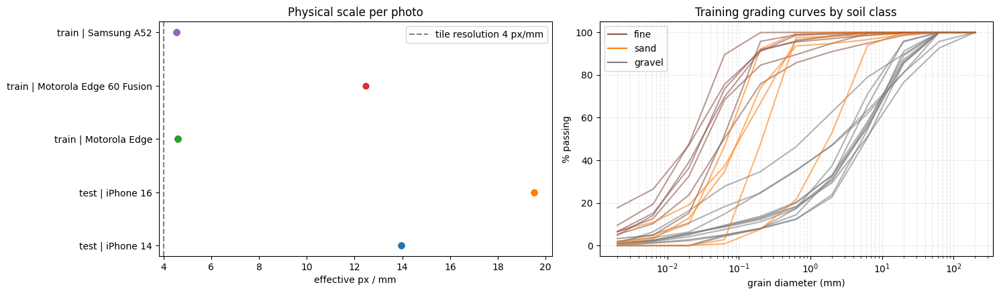

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
ax = axes[0]
for (split, dev), g in photos.groupby(["split", "device"]):
    ax.scatter(g["ppm_eff"], [f"{split} | {dev}"] * len(g), alpha=0.6)
ax.axvline(CFG.PX_PER_MM, ls="--", c="grey", label=f"tile resolution {CFG.PX_PER_MM} px/mm")
ax.set_xlabel("effective px / mm")
ax.set_title("Physical scale per photo")
ax.legend()

ax = axes[1]
colors = {"fine": "tab:brown", "sand": "tab:orange", "gravel": "tab:grey"}
for sid, row in LABELS.iterrows():
    ax.plot(DIAMETERS, row.values, c=colors[SOIL[sid]], alpha=0.6)
for k, c in colors.items():
    ax.plot([], [], c=c, label=k)
ax.set_xscale("log")
ax.set_xlabel("grain diameter (mm)")
ax.set_ylabel("% passing")
ax.set_title("Training grading curves by soil class")
ax.grid(True, which="both", ls="--", alpha=0.3)
ax.legend()
plt.tight_layout()
plt.savefig(CFG.OUTPUT_DIR / "eda_scale_curves.png", dpi=120)
plt.show()

## Tiles of a fixed physical size (cached once)

Every photo is resampled to `PX_PER_MM` and cut into a **hard, centred grid** (no overlap: overlapping tiles are
near-duplicates). 224 px = 56 mm, 384 px = 96 mm. 4 px/mm is the finest resolution reachable without upsampling
the training photos; fines (< 0.063 mm) are sub-pixel at every available resolution, so the fine end of the
curve can only be inferred indirectly. The cache is reused if it exists (delete `tiles/` to rebuild).

In [7]:
def load_at_ppm(path, ppm_eff, px_per_mm):
    """EXIF rotation + resample so that 1 mm = px_per_mm pixels. Returns (image, factor)."""
    f = px_per_mm / ppm_eff
    with Image.open(path) as im:
        w, h = im.size
        tw, th = max(1, round(w * f)), max(1, round(h * f))
        if f < 1:
            im.draft("RGB", (tw, th))   # fast JPEG DCT downscale, never below the target size
        img = ImageOps.exif_transpose(im).convert("RGB")
    if img.size not in {(tw, th), (th, tw)}:
        size = (tw, th) if (img.width >= img.height) == (tw >= th) else (th, tw)
        img = img.resize(size, Image.Resampling.LANCZOS)
    return img, f


def tile_positions(length, tile):
    """Hard grid along one axis, remainder split evenly between both borders."""
    if length < tile:
        return []
    n = length // tile
    offset = (length - n * tile) // 2
    return [offset + i * tile for i in range(n)]


def tile_dir(tile_px):
    return CFG.TILE_DIR / f"ppm{CFG.PX_PER_MM:g}_t{tile_px}"


def _tile_photo(job):
    photo, sizes = job
    img, factor = load_at_ppm(photo["path"], photo["ppm_eff"], CFG.PX_PER_MM)
    stem = Path(photo["file"]).stem
    rows = []
    for t in sizes:
        out = tile_dir(t) / photo["split"] / photo["sample_id"]
        out.mkdir(parents=True, exist_ok=True)
        ys, xs = tile_positions(img.height, t), tile_positions(img.width, t)
        coverage = len(ys) * len(xs) * t * t / (img.width * img.height)
        i = 0
        for y in ys:
            for x in xs:
                tile = img.crop((x, y, x + t, y + t))
                rel = f"{photo['split']}/{photo['sample_id']}/{stem}_{i:03d}.png"
                tile.save(tile_dir(t) / rel)
                rows.append({"tile_px": t, "split": photo["split"], "sample_id": photo["sample_id"],
                             "file": photo["file"], "device": photo["device"], "tile": rel, "x": x, "y": y,
                             "std": float(np.asarray(tile, dtype=np.float32).std()),
                             "factor": factor, "coverage": coverage})
                i += 1
    return rows


def make_tiles(photos, sizes):
    meta = {"px_per_mm": CFG.PX_PER_MM, "format": "png", "grid": "hard-centred"}
    todo = [t for t in sizes
            if not ((tile_dir(t) / "index.csv").exists() and (tile_dir(t) / "meta.json").exists()
                    and json.loads((tile_dir(t) / "meta.json").read_text()) == {**meta, "tile_px": t})]
    if todo:
        usable = photos[photos["ppm_eff"].notna()]
        jobs = [(r, todo) for r in usable.to_dict("records")]
        rows = []
        with ProcessPoolExecutor(max_workers=CFG.TILE_WORKERS) as pool:
            for r in tqdm(pool.map(_tile_photo, jobs), total=len(jobs), desc=f"tiling {todo}"):
                rows.extend(r)
        rows = pd.DataFrame(rows)
        for t in todo:
            rows[rows["tile_px"] == t].reset_index(drop=True).to_csv(tile_dir(t) / "index.csv", index=False)
            (tile_dir(t) / "meta.json").write_text(json.dumps({**meta, "tile_px": t}))
    index = {}
    for t in sizes:
        idx = pd.read_csv(tile_dir(t) / "index.csv", dtype={"sample_id": str})
        idx["path"] = [str(tile_dir(t) / r) for r in idx["tile"]]
        index[t] = idx
        per_photo = idx.groupby(["split", "device", "file"]).agg(tiles=("tile", "size"), coverage=("coverage", "first"),
                                                                upsampled=("factor", lambda f: f.iloc[0] > 1.02))
        print(f"\n[tiles] {t} px = {t / CFG.PX_PER_MM:.0f} mm: {len(idx)} tiles")
        display(per_photo.groupby(["split", "device"]).agg(photos=("tiles", "size"), tiles=("tiles", "sum"),
                                                           tiles_per_photo=("tiles", "mean"), coverage=("coverage", "mean"),
                                                           upsampled=("upsampled", "sum")).round(2))
    return index


t0 = time.time()
TILE_INDEX = make_tiles(photos, CFG.TILE_SIZES)
print(f"tiling: {time.time() - t0:.0f}s")

tiling [224, 384]:   0%|          | 0/162 [00:00<?, ?it/s]


[tiles] 224 px = 56 mm: 2718 tiles


photos  tiles  tiles_per_photo  coverage  \
split device                                                              
test  iPhone 14                    14    210             15.0      0.75   
      iPhone 16                    21    315             15.0      0.73   
train Motorola Edge                69    828             12.0      0.69   
      Motorola Edge 60 Fusion       3     45             15.0      0.78   
      Samsung A52                  55   1320             24.0      0.81   

                               upsampled  
split device                              
test  iPhone 14                        0  
      iPhone 16                        0  
train Motorola Edge                    0  
      Motorola Edge 60 Fusion          0  
      Samsung A52                      0


[tiles] 384 px = 96 mm: 756 tiles


photos  tiles  tiles_per_photo  coverage  \
split device                                                              
test  iPhone 14                    14     84              6.0      0.88   
      iPhone 16                    21    126              6.0      0.86   
train Motorola Edge                69    207              3.0      0.51   
      Motorola Edge 60 Fusion       3      9              3.0      0.46   
      Samsung A52                  55    330              6.0      0.60   

                               upsampled  
split device                              
test  iPhone 14                        0  
      iPhone 16                        0  
train Motorola Edge                    0  
      Motorola Edge 60 Fusion          0  
      Samsung A52                      0

tiling: 33s


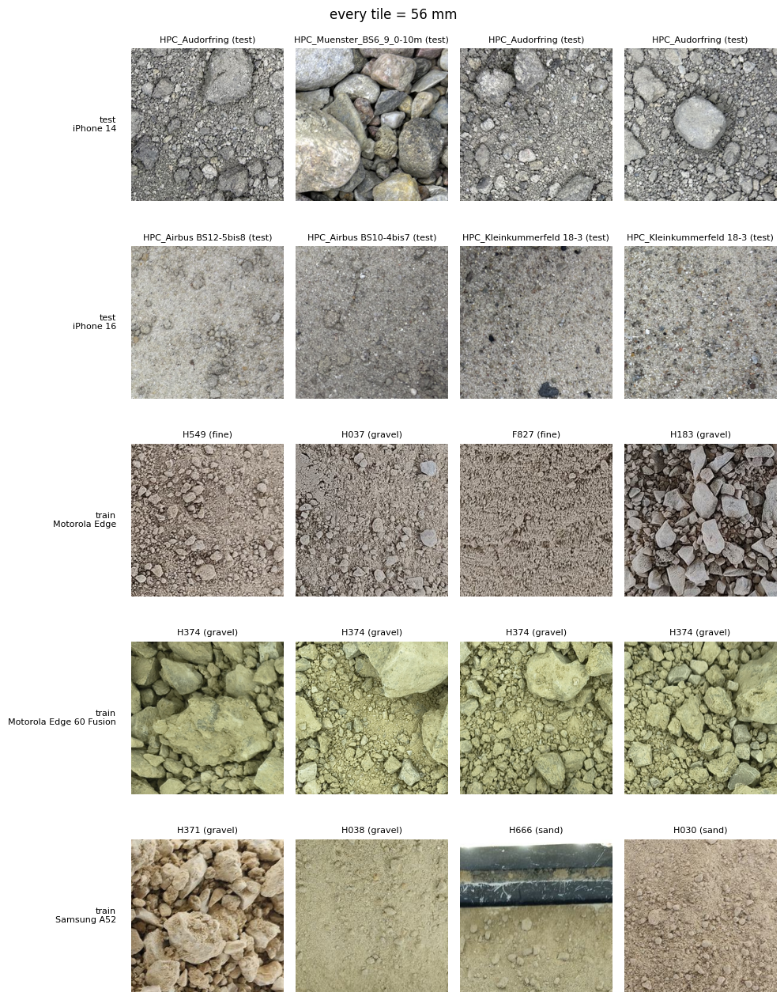

In [8]:
# the same physical tile size from every device: grains must look equally large
idx = TILE_INDEX[CFG.TILE_SIZES[0]]
groups = [(k, g.sample(min(4, len(g)), random_state=0)) for k, g in idx.groupby(["split", "device"])]
fig, axes = plt.subplots(len(groups), 4, figsize=(10, 2.6 * len(groups)), squeeze=False)
for row, ((split, dev), g) in zip(axes, groups):
    for ax in row:
        ax.axis("off")
    for ax, (_, t) in zip(row, g.iterrows()):
        ax.imshow(plt.imread(t["path"]))
        ax.set_title(f"{t['sample_id']} ({SOIL.get(t['sample_id'], 'test')})", fontsize=8)
    row[0].text(-0.1, 0.5, f"{split}\n{dev}", transform=row[0].transAxes, ha="right", va="center", fontsize=8)
fig.suptitle(f"every tile = {CFG.TILE_SIZES[0] / CFG.PX_PER_MM:.0f} mm")
plt.tight_layout()
plt.show()

## Folds and baselines

Leave-one-sample-out over physical samples: all tiles of all photos of one sample are held out together;
tile predictions are averaged per photo, then per sample, before scoring. `folds.csv` is written once and used
by every experiment.

In [9]:
SIDS = sorted(train_sids & set(LABELS.index))
folds = pd.DataFrame({"sample_id": SIDS, "fold": np.arange(len(SIDS)), "soil_class": SOIL.loc[SIDS].values})
folds.to_csv(CFG.OUTPUT_DIR / "folds.csv", index=False)

y = LABELS.loc[SIDS].to_numpy()
UNIFORM_EMD = emd_score(y, np.tile(UNIFORM_CURVE, (len(y), 1)))
MEAN_CURVE_EMD = emd_score(y, enforce_monotone((y.sum(0, keepdims=True) - y) / (len(y) - 1)))
print(f"{len(SIDS)} folds | uniform curve EMD {UNIFORM_EMD:.2f} | mean-curve LOSO EMD {MEAN_CURVE_EMD:.2f} <- to beat")

N_FOLDS = len(SIDS)


def stratified_subset(n):
    """n семплів, пропорційно класам, рівномірно по D50 всередині класу (одні й ті ж фолди для всіх абляцій)."""
    d50 = pd.Series({s: d_value(LABELS.loc[s].to_numpy(), 50) for s in SIDS})
    out = []
    for cls, g in SOIL.loc[SIDS].groupby(SOIL.loc[SIDS]):
        k = max(1, int(round(n * len(g) / len(SIDS))))
        order_ = d50.loc[g.index].sort_values().index.tolist()
        out += [order_[int(i)] for i in np.unique(np.linspace(0, len(order_) - 1, min(k, len(order_))).round().astype(int))]
    return sorted(out)


SUB_SIDS = stratified_subset(min(CFG.SUB_N, N_FOLDS))
print(f"ablation folds ({len(SUB_SIDS)}):", {s: SOIL[s] for s in SUB_SIDS})

24 folds | uniform curve EMD 98.61 | mean-curve LOSO EMD 88.32 <- to beat
ablation folds (8): {'F827': 'fine', 'G190': 'fine', 'H037': 'gravel', 'H183': 'gravel', 'H366': 'gravel', 'H368': 'gravel', 'H516': 'sand', 'H666': 'sand'}


# Experiment logging

`/kaggle/working/experiments/<name>_<time>/`: `config.json`, per-fold Lightning CSV logs (`folds/*/metrics.csv`),
weights, `oof.csv`, `test_preds.csv`, `per_sample.csv`, figures, `submission.csv`, `summary.json`
(CV mean ± std, D-errors, per-class EMD, GPU, GPU-hours, peak memory). `registry.csv` has one row per run.

In [10]:
class ExperimentTracker:
    def __init__(self, name, config, root=CFG.EXP_DIR):
        self.name, self.root = name, Path(root)
        run_id = f"{name}_{datetime.now():%Y%m%d-%H%M%S}"
        self.run_id, n = run_id, 1
        while (self.root / self.run_id).exists():
            n += 1
            self.run_id = f"{run_id}_{n}"
        self.dir = self.root / self.run_id
        self.weights_dir = self.dir / "weights"
        self.weights_dir.mkdir(parents=True)
        self.config = {**{k: v for k, v in vars(CFG).items() if k.isupper()}, **config}
        (self.dir / "config.json").write_text(json.dumps(self.config, indent=2, default=str))
        self._t0 = time.time()
        if CFG.DEVICE == "cuda":
            torch.cuda.reset_peak_memory_stats()
        print(f"[tracker] {self.run_id}")

    def lightning_logger(self, version):
        return CSVLogger(save_dir=str(self.dir), name="folds", version=version)

    def save_table(self, df, fname, **kwargs):
        df.to_csv(self.dir / fname, **kwargs)

    def save_figure(self, fig, fname):
        fig.savefig(self.dir / fname, dpi=120, bbox_inches="tight")

    def finish(self, metrics):
        hours = (time.time() - self._t0) / 3600
        summary = {"run_id": self.run_id, "name": self.name, "run_dir": str(self.dir),
                   "finished_at": datetime.now().isoformat(timespec="seconds"),
                   "gpu": torch.cuda.get_device_name(0) if CFG.DEVICE == "cuda" else "cpu",
                   "gpu_hours": round(hours, 3),
                   "peak_mem_gb": round(torch.cuda.max_memory_allocated() / 1e9, 2) if CFG.DEVICE == "cuda" else 0.0,
                   **metrics}
        (self.dir / "summary.json").write_text(json.dumps(summary, indent=2, default=str))
        row = pd.DataFrame([{**summary, **{f"cfg.{k}": v for k, v in self.config.items()}}])
        registry = self.root / "registry.csv"
        if registry.exists():
            row = pd.concat([pd.read_csv(registry), row], ignore_index=True)
        row.to_csv(registry, index=False)
        return summary


def read_sample_table(path):
    return pd.read_csv(path, dtype={"sample_id": str}).set_index("sample_id")

# Part 1 — CNN on tiles

* **Frozen backbone** → features of every tile are extracted once (4 dihedral views: id, h-flip, v-flip, rot90)
  and cached; the head trains on them in seconds per fold. Training samples a random view (augmentation),
  evaluation averages the curve over the 4 views (TTA).
* **Fine-tuning** → tiles as images with scale-safe augmentation (flips, rot90, mild colour; **no resize,
  no random-resized-crop**: they change mm/px and therefore the label). BatchNorm statistics can be frozen.
* Head: LayerNorm → MLP → 11 logits → softmax → cumsum × 100 (always a valid curve), bias initialised to the
  mean training curve. Loss = differentiable EMD. Weight decay is not applied to biases / norm parameters.

In [11]:
def tile_transform(train):
    aug = [A.HorizontalFlip(p=0.5), A.VerticalFlip(p=0.5), A.RandomRotate90(p=0.5),
           A.RandomBrightnessContrast(brightness_limit=0.15, contrast_limit=0.15, p=0.5),
           A.HueSaturationValue(hue_shift_limit=5, sat_shift_limit=10, val_shift_limit=10, p=0.3)] if train else []
    return A.Compose(aug + [A.Normalize(mean=CFG.MEAN, std=CFG.STD), ToTensorV2()])


class TileDataset(Dataset):
    def __init__(self, paths, labels=None, transform=None):
        self.paths, self.labels, self.transform = list(paths), labels, transform

    def __len__(self):
        return len(self.paths)

    def __getitem__(self, i):
        img = self.transform(image=np.array(Image.open(self.paths[i]).convert("RGB")))["image"]
        if self.labels is None:
            return img
        return img, torch.tensor(self.labels[i], dtype=torch.float32)


class FeatureDataset(Dataset):
    """Cached features (N, views, D). Train: one random view per item. Eval: all views (TTA in the module)."""
    def __init__(self, feats, labels=None, train=False):
        self.feats, self.labels, self.train = feats, labels, train

    def __len__(self):
        return len(self.feats)

    def __getitem__(self, i):
        x = self.feats[i]
        if self.train:
            x = x[np.random.randint(len(x))]
        x = torch.from_numpy(np.asarray(x, dtype=np.float32))
        if self.labels is None:
            return x
        return x, torch.tensor(self.labels[i], dtype=torch.float32)


def dihedral_views(x):
    return [x, x.flip(-1), x.flip(-2), x.rot90(1, (-2, -1))]


@torch.no_grad()
def extract_features(backbone, tile_px):
    path = CFG.FEAT_DIR / f"{re.sub(r'[^A-Za-z0-9._-]', '_', backbone)}_t{tile_px}_d4.npy"
    if path.exists():
        return np.load(path)
    idx = TILE_INDEX[tile_px]
    model = timm.create_model(backbone, pretrained=True, num_classes=0).to(CFG.DEVICE).eval()
    loader = DataLoader(TileDataset(idx["path"], None, tile_transform(False)), batch_size=64,
                        num_workers=CFG.NUM_WORKERS, pin_memory=CFG.DEVICE == "cuda")
    out = []
    for x in tqdm(loader, desc=f"features {backbone} @ {tile_px}px"):
        x = x.to(CFG.DEVICE, non_blocking=True)
        with torch.autocast("cuda", enabled=CFG.DEVICE == "cuda"):
            out.append(torch.stack([model(v).float() for v in dihedral_views(x)], dim=1).half().cpu())
    feats = torch.cat(out).numpy()
    np.save(path, feats)
    del model
    if CFG.DEVICE == "cuda":
        torch.cuda.empty_cache()
    return feats

In [12]:
class CurveHead(nn.Module):
    def __init__(self, in_dim, hidden=256, dropout=0.3):
        super().__init__()
        self.mlp = nn.Sequential(nn.LayerNorm(in_dim), nn.Linear(in_dim, hidden), nn.GELU(),
                                 nn.Dropout(dropout), nn.Linear(hidden, len(CFG.GRAIN_COLS)))

    @torch.no_grad()
    def init_bias(self, mean_curve):
        """softmax(0) is the uniform curve; start from the mean training curve instead."""
        inc = np.diff(np.concatenate([[0.0], np.asarray(mean_curve, dtype=np.float64)])) / 100.0
        last = self.mlp[-1]
        last.bias.copy_(torch.tensor(np.log(np.clip(inc, 1e-4, None)), dtype=last.bias.dtype))
        last.weight.mul_(0.1)

    def forward(self, feats):
        return torch.cumsum(F.softmax(self.mlp(feats), dim=-1), dim=-1) * 100.0


class FeatureNet(nn.Module):
    def __init__(self, in_dim):
        super().__init__()
        self.head = CurveHead(in_dim)

    def forward(self, x):
        return self.head(x)

    def lr_groups(self, lr, backbone_lr):
        return [(self.head, lr)]


class ImageNet(nn.Module):
    def __init__(self, backbone, freeze_bn=True):
        super().__init__()
        self.freeze_bn = freeze_bn
        self.backbone = timm.create_model(backbone, pretrained=True, num_classes=0)
        self.head = CurveHead(self.backbone.num_features)

    def train(self, mode=True):
        super().train(mode)
        if mode and self.freeze_bn:   # keep ImageNet BN statistics: a batch holds tiles of only a few samples
            for m in self.backbone.modules():
                if isinstance(m, nn.modules.batchnorm._BatchNorm):
                    m.eval()
        return self

    def forward(self, x):
        return self.head(self.backbone(x))

    def lr_groups(self, lr, backbone_lr):
        return [(self.head, lr), (self.backbone, backbone_lr)]


def param_groups(module_lrs, weight_decay):
    groups = []
    for module, lr in module_lrs:
        decay = [p for p in module.parameters() if p.requires_grad and p.ndim > 1]
        no_decay = [p for p in module.parameters() if p.requires_grad and p.ndim <= 1]
        groups += [{"params": decay, "lr": lr, "weight_decay": weight_decay},
                   {"params": no_decay, "lr": lr, "weight_decay": 0.0}]
    return [g for g in groups if g["params"]]


class EMDLoss(nn.Module):
    def __init__(self):
        super().__init__()
        self.register_buffer("w", torch.tensor(LOG_WIDTHS, dtype=torch.float32))

    def forward(self, pred, target):
        return ((pred[:, 1:].float() - target[:, 1:]).abs() * self.w).sum(dim=1).mean()


def aggregate_tiles(preds, photo_ids, sample_ids, mono=True):
    """tiles -> mean per photo -> mean per sample (first-seen order), valid curves."""
    df = pd.DataFrame(np.asarray(preds))
    df["photo"], df["sid"] = np.asarray(photo_ids), np.asarray(sample_ids)
    per_photo = df.groupby(["sid", "photo"], sort=False).mean()
    per_sample = per_photo.groupby(level="sid", sort=False).mean()
    return per_sample.index.to_numpy(), (enforce_monotone(per_sample.to_numpy()) if mono else per_sample.to_numpy())


def warmup_cosine(total_steps, warmup_steps):
    def factor(step):
        if step < warmup_steps:
            return (step + 1) / warmup_steps
        progress = min(1.0, (step - warmup_steps) / max(1, total_steps - warmup_steps))
        return 0.5 * (1 + np.cos(np.pi * progress))
    return factor


class GrainLit(L.LightningModule):
    def __init__(self, net, lr, backbone_lr, weight_decay, warmup_epochs, optimizer="adamw", tta=True):
        super().__init__()
        self.save_hyperparameters(ignore=["net"])
        self.net = net
        self.loss_fn = EMDLoss()
        self.val_groups, self.val_target = None, None   # set per fold: (photo ids, sample ids), LABELS
        self._val_preds = []

    def forward(self, x):
        return self.net(x)

    def predict_curves(self, x):
        if x.dim() == 3:                                   # cached features (B, views, D)
            b, v, d = x.shape
            return self.net(x.reshape(b * v, d)).float().reshape(b, v, -1).mean(1)
        if not self.hparams.tta:
            return self.net(x).float()
        return torch.stack([self.net(v).float() for v in dihedral_views(x)]).mean(0)

    def training_step(self, batch, batch_idx):
        x, y = batch
        loss = self.loss_fn(self.net(x), y)
        self.log("train_loss", loss, on_step=False, on_epoch=True, batch_size=len(x))
        return loss

    def validation_step(self, batch, batch_idx):
        self._val_preds.append(self.predict_curves(batch[0]).cpu())

    def on_validation_epoch_end(self):
        preds = torch.cat(self._val_preds).numpy()
        self._val_preds.clear()
        sids, curves = aggregate_tiles(preds, *self.val_groups)
        self.log("val_emd", emd_score(self.val_target.loc[sids].to_numpy(), curves))

    def predict_step(self, batch, batch_idx):
        return self.predict_curves(batch[0] if isinstance(batch, (list, tuple)) else batch)

    def configure_optimizers(self):
        hp = self.hparams
        groups = param_groups(self.net.lr_groups(hp.lr, hp.backbone_lr), hp.weight_decay)
        opt = SGD(groups, momentum=0.9, nesterov=True) if hp.optimizer == "sgd" else AdamW(groups)
        total = self.trainer.estimated_stepping_batches
        warmup = max(1, int(total * hp.warmup_epochs / max(1, self.trainer.max_epochs)))
        return {"optimizer": opt,
                "lr_scheduler": {"scheduler": LambdaLR(opt, warmup_cosine(total, warmup)), "interval": "step"}}


class HistoryCallback(L.Callback):
    def __init__(self, print_every=CFG.PRINT_EVERY):
        self.print_every, self.rows = print_every, []

    def on_train_epoch_end(self, trainer, pl_module):
        m = trainer.callback_metrics
        row = {"epoch": trainer.current_epoch + 1, "train_loss": m["train_loss"].item(),
               "val_emd": m["val_emd"].item() if "val_emd" in m else np.nan}
        self.rows.append(row)
        e = row["epoch"]
        if e % self.print_every == 0 or e == trainer.max_epochs:
            print(f"    epoch {e:02d}/{trainer.max_epochs} | train {row['train_loss']:.2f} | val {row['val_emd']:.2f}")


def lightning_predict(trainer, module, loader):
    return torch.cat(trainer.predict(module, loader)).numpy()

## LOSO runner

`run_loso(name, backbone, tile_px, ...)` = one experiment = one row of the results table.

In [13]:
def run_loso(name, backbone, tile_px=224, freeze_backbone=True, epochs=None, lr=None, backbone_lr=None,
             optimizer="adamw", freeze_bn=True, tta=True, batch_size=None,
             strategy="ft", aug=True, warmup_epochs=None, weight_decay=None, subset=False,
             keep_weights=True, group_batches=0, lora_rank=8, lp_epochs=40):
    """strategy: 'ft' повний fine-tuning | 'lora' адаптери LoRA (backbone заморожений) | 'lpft' спершу linear probe, потім FT.
    subset=True -> лише абляційні фолди SUB_SIDS. keep_weights: True / False / список sample_id, чиї ваги зберігати.
    group_batches=k: у кожному батчі тайли лише k фізичних семплів (стрес-тест BatchNorm)."""
    assert strategy in ("ft", "lora", "lpft")
    n_ep = epochs or (CFG.FEAT_EPOCHS if freeze_backbone else CFG.EPOCHS)
    if CFG.QUICK:
        n_ep = min(n_ep, 2)
    wd = CFG.WEIGHT_DECAY if weight_decay is None else weight_decay
    params = dict(backbone=backbone, tile_px=tile_px, tile_mm=tile_px / CFG.PX_PER_MM, freeze_backbone=freeze_backbone,
                  strategy="frozen" if freeze_backbone else strategy, epochs=n_ep,
                  lr=lr or CFG.LR, backbone_lr=backbone_lr or CFG.BACKBONE_LR, optimizer=optimizer,
                  freeze_bn=freeze_bn, tta=tta, aug=aug, weight_decay=wd, subset=subset,
                  warmup_epochs=CFG.WARMUP_EPOCHS if warmup_epochs is None else warmup_epochs,
                  group_batches=group_batches, lora_rank=lora_rank,
                  batch_size=batch_size or (CFG.FEAT_BATCH_SIZE if freeze_backbone else CFG.BATCH_SIZE))
    tracker = ExperimentTracker(name, params)
    idx = TILE_INDEX[tile_px]
    train_tiles = idx[(idx["split"] == "train") & idx["sample_id"].isin(SIDS)]
    test_tiles = idx[idx["split"] == "test"]

    feats = extract_features(backbone, tile_px) if (freeze_backbone or strategy == "lpft") else None
    if freeze_backbone:
        make_ds = lambda rows, y, train: FeatureDataset(feats[rows.index.to_numpy()], y, train)
        make_net = lambda: FeatureNet(feats.shape[-1])
        workers = 0
    else:
        make_ds = lambda rows, y, train: TileDataset(rows["path"], y, tile_transform(train and aug))
        make_net = lambda: ImageNet(backbone, freeze_bn=freeze_bn)
        workers = CFG.NUM_WORKERS

    def loader(ds, shuffle, sids=None, seed=0):
        bs = max(1, min(params["batch_size"], len(ds)))
        kw = dict(num_workers=workers, pin_memory=CFG.DEVICE == "cuda", persistent_workers=workers > 0)
        if shuffle and group_batches:
            return DataLoader(ds, batch_sampler=GroupedBatchSampler(sids, bs, group_batches, seed), **kw)
        return DataLoader(ds, batch_size=bs, shuffle=shuffle, drop_last=shuffle, **kw)

    def labels_of(rows):
        return LABELS.loc[rows["sample_id"], CFG.GRAIN_COLS].to_numpy(np.float32)

    folds_run = folds[folds["sample_id"].isin(SUB_SIDS)] if subset else folds
    test_loader = loader(make_ds(test_tiles, None, False), False)
    oof, histories, test_preds, n_params = {}, [], [], None
    for _, f in folds_run.iterrows():
        held = f["sample_id"]
        tr = train_tiles[train_tiles["sample_id"] != held]
        va = train_tiles[train_tiles["sample_id"] == held]
        print(f"Fold {int(f['fold']) + 1:02d}/{len(folds)} | {held} ({f['soil_class']}) | {len(va)} val / {len(tr)} train tiles")
        L.seed_everything(CFG.SEED + int(f["fold"]), workers=True, verbose=False)

        net = make_net()
        net.head.init_bias(LABELS.loc[[s for s in SIDS if s != held]].mean().to_numpy())
        if not freeze_backbone and strategy == "lpft":
            lp_stage(net.head, feats[tr.index.to_numpy()], labels_of(tr), epochs=3 if CFG.QUICK else lp_epochs)
        if not freeze_backbone and strategy == "lora":
            apply_lora(net.backbone, lora_rank)
            net.lora = True
        if n_params is None:
            n_params = (sum(p.numel() for p in net.parameters()) / 1e6,
                        sum(p.numel() for p in net.parameters() if p.requires_grad) / 1e6)
        module = GrainLit(net, params["lr"], params["backbone_lr"], wd, params["warmup_epochs"], optimizer, tta)
        module.val_groups = (va["file"].to_numpy(), va["sample_id"].to_numpy())
        module.val_target = LABELS
        val_loader = loader(make_ds(va, labels_of(va), False), False)
        history = HistoryCallback()
        trainer = L.Trainer(
            max_epochs=params["epochs"], accelerator="auto", devices=1,
            precision="16-mixed" if CFG.DEVICE == "cuda" else "32-true",
            gradient_clip_val=1.0, callbacks=[history, LearningRateMonitor(logging_interval="epoch")],
            logger=tracker.lightning_logger(f"fold{int(f['fold']):02d}_{held}"), log_every_n_steps=1,
            enable_checkpointing=False, enable_progress_bar=False, enable_model_summary=False, num_sanity_val_steps=0,
        )
        trainer.fit(module, loader(make_ds(tr, labels_of(tr), True), True, tr["sample_id"].to_numpy(), int(f["fold"])), val_loader)

        for row in history.rows:
            row.update(fold=int(f["fold"]), sample_id=held)
        histories.extend(history.rows)
        if keep_weights is True or (isinstance(keep_weights, (list, tuple, set)) and held in keep_weights):
            state = net.head.state_dict() if freeze_backbone else {k: v.half() for k, v in net.state_dict().items()}
            torch.save(state, tracker.weights_dir / f"fold{int(f['fold']):02d}_{held}.pt")

        _, curve = aggregate_tiles(lightning_predict(trainer, module, val_loader), va["file"], va["sample_id"])
        oof[held] = curve[0]
        if len(test_tiles):
            sids, curves = aggregate_tiles(lightning_predict(trainer, module, test_loader),
                                           test_tiles["file"], test_tiles["sample_id"])
            test_preds.append(pd.DataFrame(curves, index=sids, columns=CFG.GRAIN_COLS))
        del trainer, module, net
        if CFG.DEVICE == "cuda":
            torch.cuda.empty_cache()

    oof_df = pd.DataFrame.from_dict(oof, orient="index", columns=CFG.GRAIN_COLS)
    history_df = pd.DataFrame(histories)
    test_pred = sum(test_preds) / len(test_preds) if test_preds else pd.DataFrame(columns=CFG.GRAIN_COLS)
    tracker.save_table(oof_df, "oof.csv", index_label="sample_id")
    tracker.save_table(history_df, "history.csv", index=False)
    tracker.save_table(test_pred, "test_preds.csv", index_label="sample_id")
    tracker.extra = dict(params_M=round(n_params[0], 2), trainable_M=round(n_params[1], 3))
    return SimpleNamespace(tracker=tracker, oof=oof_df, history=history_df, test_pred=test_pred)
    

def report_loso(run, show=True):
    oof_df, tracker = run.oof, run.tracker
    y_true = LABELS.loc[oof_df.index].to_numpy()
    per = pd.DataFrame({"emd": emd_per_sample(y_true, oof_df.to_numpy()), "soil_class": SOIL.loc[oof_df.index]},
                       index=oof_df.index).sort_values("emd")
    by_class = per.groupby("soil_class")["emd"].mean().round(2)
    metrics = {"loso_emd": round(per["emd"].mean(), 3), "loso_emd_std": round(per["emd"].std(), 3),
               "loso_emd_median": round(per["emd"].median(), 3), "worst_sample": per["emd"].idxmax(),
               **{k: round(v, 3) for k, v in d_value_errors(y_true, oof_df.to_numpy()).items()},
               **{f"emd_{k}": v for k, v in by_class.items()},
               "mean_curve_emd": round(MEAN_CURVE_EMD, 3), "n_folds": len(oof_df), **getattr(tracker, "extra", {})}
    print(f"[{tracker.name}] LOSO EMD {metrics['loso_emd']:.2f} ± {metrics['loso_emd_std']:.2f} "
          f"(median {metrics['loso_emd_median']:.2f}, mean-curve {MEAN_CURVE_EMD:.2f}) | by class {by_class.to_dict()}")

    fig, axes = plt.subplots(1, 2, figsize=(15, 5))
    curve = run.history.groupby("epoch")[["train_loss", "val_emd"]].mean()
    axes[0].plot(curve.index, curve["train_loss"], label="train EMD-loss (tiles)")
    axes[0].plot(curve.index, curve["val_emd"], label="held-out sample EMD")
    axes[0].axhline(MEAN_CURVE_EMD, c="grey", ls=":", label="mean-curve baseline")
    axes[0].set_xlabel("epoch")
    axes[0].set_title(f"{tracker.name}: mean over folds")
    axes[0].legend()
    axes[0].grid(True, ls="--", alpha=0.4)
    colors = {"fine": "tab:brown", "sand": "tab:orange", "gravel": "tab:grey"}
    axes[1].barh(per.index, per["emd"], color=[colors[c] for c in per["soil_class"]])
    axes[1].axvline(per["emd"].mean(), c="crimson", ls="--")
    axes[1].set_title("held-out EMD per sample (colour = soil class)")
    plt.tight_layout()
    tracker.save_figure(fig, "loso_results.png")
    plt.show() if show else plt.close(fig)

    tracker.save_table(per, "per_sample.csv", index_label="sample_id")
    return tracker.finish(metrics)


def make_submission(test_pred, fname="submission.csv", tracker=None):
    pred = pd.DataFrame(enforce_monotone(test_pred.to_numpy()), index=test_pred.index, columns=CFG.GRAIN_COLS)
    submission = sub_df.copy()
    for c, fallback in zip(CFG.GRAIN_COLS, UNIFORM_CURVE):
        submission[c] = submission["sample_id"].map(pred[c]).fillna(fallback)
    submission.to_csv(CFG.OUTPUT_DIR / fname, index=False)
    if tracker is not None:
        tracker.save_table(submission, "submission.csv", index=False)
    return submission

## Experiments: frozen backbones (cached features)

Pretrained weights (timm): `resnet18.a1_in1k`, `tf_efficientnet_b0.ns_jft_in1k`, `convnext_tiny.fb_in22k_ft_in1k`,
`convnextv2_base.fcmae_ft_in22k_in1k`. Feature extraction runs once per backbone × tile size; afterwards a
24-fold LOSO run takes about a minute. Each run writes `submission_<name>.csv`.

[start] effb0_frozen_t224 | elapsed 0.01 h
[tracker] effb0_frozen_t224_20261031-122529


model.safetensors: reconstructing file:   0%|          |  0.00B / 21.4MB            

model.safetensors: downloading bytes:           |  0.00B            

features tf_efficientnet_b0.ns_jft_in1k @ 224px:   0%|          | 0/43 [00:00<?, ?it/s]

Fold 01/24 | F827 (fine) | 96 val / 2097 train tiles


/usr/local/lib/python3.13/dist-packages/lightning/pytorch/trainer/connectors/data_connector.py:434: The 'train_dataloader' does not have many workers which may be a bottleneck. Consider increasing the value of the `num_workers` argument` to `num_workers=3` in the `DataLoader` to improve performance.
/usr/local/lib/python3.13/dist-packages/lightning/pytorch/trainer/connectors/data_connector.py:434: The 'val_dataloader' does not have many workers which may be a bottleneck. Consider increasing the value of the `num_workers` argument` to `num_workers=3` in the `DataLoader` to improve performance.


... (44 outputs left out)

    epoch 20/60 | train 20.42 | val 65.84
    epoch 40/60 | train 17.02 | val 74.69
    epoch 60/60 | train 15.81 | val 70.95
Fold 24/24 | H668 (fine) | 132 val / 2061 train tiles


/usr/local/lib/python3.13/dist-packages/lightning/pytorch/trainer/connectors/data_connector.py:434: The 'predict_dataloader' does not have many workers which may be a bottleneck. Consider increasing the value of the `num_workers` argument` to `num_workers=3` in the `DataLoader` to improve performance.
/usr/local/lib/python3.13/dist-packages/lightning/pytorch/trainer/connectors/data_connector.py:434: The 'predict_dataloader' does not have many workers which may be a bottleneck. Consider increasing the value of the `num_workers` argument` to `num_workers=3` in the `DataLoader` to improve performance.
/usr/local/lib/python3.13/dist-packages/lightning/pytorch/trainer/connectors/data_connector.py:434: The 'train_dataloader' does not have many workers which may be a bottleneck. Consider increasing the value of the `num_workers` argument` to `num_workers=3` in the `DataLoader` to improve performance.
/usr/local/lib/python3.13/dist-packages/lightning/pytorch/trainer/connectors/data_connector.p

    epoch 20/60 | train 20.66 | val 43.25
    epoch 40/60 | train 16.59 | val 42.54
    epoch 60/60 | train 15.96 | val 44.83
[effb0_frozen_t224] LOSO EMD 39.26 ± 30.01 (median 28.31, mean-curve 88.32) | by class {'fine': 51.56, 'gravel': 28.62, 'sand': 47.57}


/usr/local/lib/python3.13/dist-packages/lightning/pytorch/trainer/connectors/data_connector.py:434: The 'predict_dataloader' does not have many workers which may be a bottleneck. Consider increasing the value of the `num_workers` argument` to `num_workers=3` in the `DataLoader` to improve performance.
/usr/local/lib/python3.13/dist-packages/lightning/pytorch/trainer/connectors/data_connector.py:434: The 'predict_dataloader' does not have many workers which may be a bottleneck. Consider increasing the value of the `num_workers` argument` to `num_workers=3` in the `DataLoader` to improve performance.


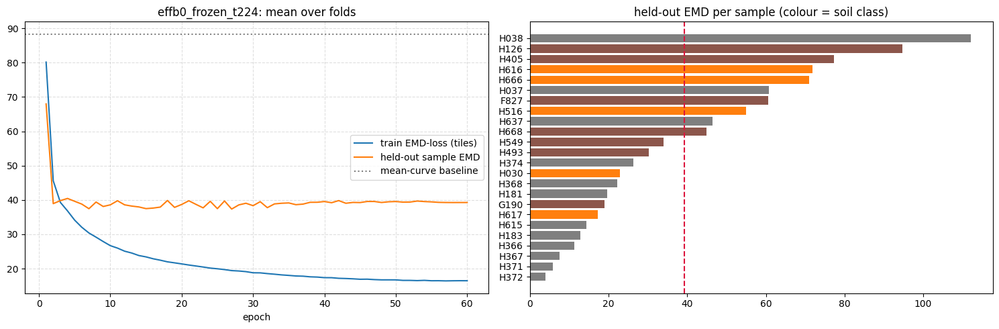

[start] convnext_t_frozen_t224 | elapsed 0.06 h
[tracker] convnext_t_frozen_t224_20261031-122824


model.safetensors: reconstructing file:   0%|          |  0.00B /  114MB            

model.safetensors: downloading bytes:           |  0.00B            

features convnext_tiny.fb_in22k_ft_in1k @ 224px:   0%|          | 0/43 [00:00<?, ?it/s]

Fold 01/24 | F827 (fine) | 96 val / 2097 train tiles


/usr/local/lib/python3.13/dist-packages/lightning/pytorch/trainer/connectors/data_connector.py:434: The 'train_dataloader' does not have many workers which may be a bottleneck. Consider increasing the value of the `num_workers` argument` to `num_workers=3` in the `DataLoader` to improve performance.
/usr/local/lib/python3.13/dist-packages/lightning/pytorch/trainer/connectors/data_connector.py:434: The 'val_dataloader' does not have many workers which may be a bottleneck. Consider increasing the value of the `num_workers` argument` to `num_workers=3` in the `DataLoader` to improve performance.


... (44 outputs left out)

    epoch 20/60 | train 20.02 | val 57.05
    epoch 40/60 | train 16.06 | val 65.35
    epoch 60/60 | train 15.01 | val 67.49
Fold 24/24 | H668 (fine) | 132 val / 2061 train tiles


/usr/local/lib/python3.13/dist-packages/lightning/pytorch/trainer/connectors/data_connector.py:434: The 'predict_dataloader' does not have many workers which may be a bottleneck. Consider increasing the value of the `num_workers` argument` to `num_workers=3` in the `DataLoader` to improve performance.
/usr/local/lib/python3.13/dist-packages/lightning/pytorch/trainer/connectors/data_connector.py:434: The 'predict_dataloader' does not have many workers which may be a bottleneck. Consider increasing the value of the `num_workers` argument` to `num_workers=3` in the `DataLoader` to improve performance.
/usr/local/lib/python3.13/dist-packages/lightning/pytorch/trainer/connectors/data_connector.py:434: The 'train_dataloader' does not have many workers which may be a bottleneck. Consider increasing the value of the `num_workers` argument` to `num_workers=3` in the `DataLoader` to improve performance.
/usr/local/lib/python3.13/dist-packages/lightning/pytorch/trainer/connectors/data_connector.p

    epoch 20/60 | train 21.28 | val 32.41
    epoch 40/60 | train 17.01 | val 39.64
    epoch 60/60 | train 16.18 | val 41.24
[convnext_t_frozen_t224] LOSO EMD 41.29 ± 33.78 (median 30.49, mean-curve 88.32) | by class {'fine': 55.34, 'gravel': 30.02, 'sand': 48.69}


/usr/local/lib/python3.13/dist-packages/lightning/pytorch/trainer/connectors/data_connector.py:434: The 'predict_dataloader' does not have many workers which may be a bottleneck. Consider increasing the value of the `num_workers` argument` to `num_workers=3` in the `DataLoader` to improve performance.
/usr/local/lib/python3.13/dist-packages/lightning/pytorch/trainer/connectors/data_connector.py:434: The 'predict_dataloader' does not have many workers which may be a bottleneck. Consider increasing the value of the `num_workers` argument` to `num_workers=3` in the `DataLoader` to improve performance.


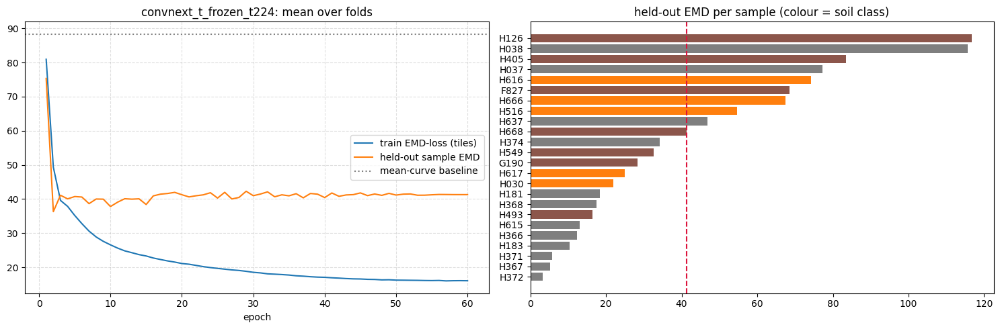

[start] convnextv2b_frozen_t224 | elapsed 0.11 h
[tracker] convnextv2b_frozen_t224_20261031-123119


model.safetensors: reconstructing file:   0%|          |  0.00B /  355MB            

model.safetensors: downloading bytes:           |  0.00B            

features convnextv2_base.fcmae_ft_in22k_in1k @ 224px:   0%|          | 0/43 [00:00<?, ?it/s]

Fold 01/24 | F827 (fine) | 96 val / 2097 train tiles


/usr/local/lib/python3.13/dist-packages/lightning/pytorch/trainer/connectors/data_connector.py:434: The 'train_dataloader' does not have many workers which may be a bottleneck. Consider increasing the value of the `num_workers` argument` to `num_workers=3` in the `DataLoader` to improve performance.
/usr/local/lib/python3.13/dist-packages/lightning/pytorch/trainer/connectors/data_connector.py:434: The 'val_dataloader' does not have many workers which may be a bottleneck. Consider increasing the value of the `num_workers` argument` to `num_workers=3` in the `DataLoader` to improve performance.


... (44 outputs left out)

    epoch 20/60 | train 20.01 | val 50.03
    epoch 40/60 | train 16.12 | val 54.37
    epoch 60/60 | train 15.68 | val 56.31
Fold 24/24 | H668 (fine) | 132 val / 2061 train tiles


/usr/local/lib/python3.13/dist-packages/lightning/pytorch/trainer/connectors/data_connector.py:434: The 'predict_dataloader' does not have many workers which may be a bottleneck. Consider increasing the value of the `num_workers` argument` to `num_workers=3` in the `DataLoader` to improve performance.
/usr/local/lib/python3.13/dist-packages/lightning/pytorch/trainer/connectors/data_connector.py:434: The 'predict_dataloader' does not have many workers which may be a bottleneck. Consider increasing the value of the `num_workers` argument` to `num_workers=3` in the `DataLoader` to improve performance.
/usr/local/lib/python3.13/dist-packages/lightning/pytorch/trainer/connectors/data_connector.py:434: The 'train_dataloader' does not have many workers which may be a bottleneck. Consider increasing the value of the `num_workers` argument` to `num_workers=3` in the `DataLoader` to improve performance.
/usr/local/lib/python3.13/dist-packages/lightning/pytorch/trainer/connectors/data_connector.p

    epoch 20/60 | train 21.19 | val 45.39
    epoch 40/60 | train 17.10 | val 46.99
    epoch 60/60 | train 15.96 | val 47.94
[convnextv2b_frozen_t224] LOSO EMD 41.12 ± 31.61 (median 35.20, mean-curve 88.32) | by class {'fine': 56.93, 'gravel': 30.33, 'sand': 44.9}


/usr/local/lib/python3.13/dist-packages/lightning/pytorch/trainer/connectors/data_connector.py:434: The 'predict_dataloader' does not have many workers which may be a bottleneck. Consider increasing the value of the `num_workers` argument` to `num_workers=3` in the `DataLoader` to improve performance.
/usr/local/lib/python3.13/dist-packages/lightning/pytorch/trainer/connectors/data_connector.py:434: The 'predict_dataloader' does not have many workers which may be a bottleneck. Consider increasing the value of the `num_workers` argument` to `num_workers=3` in the `DataLoader` to improve performance.


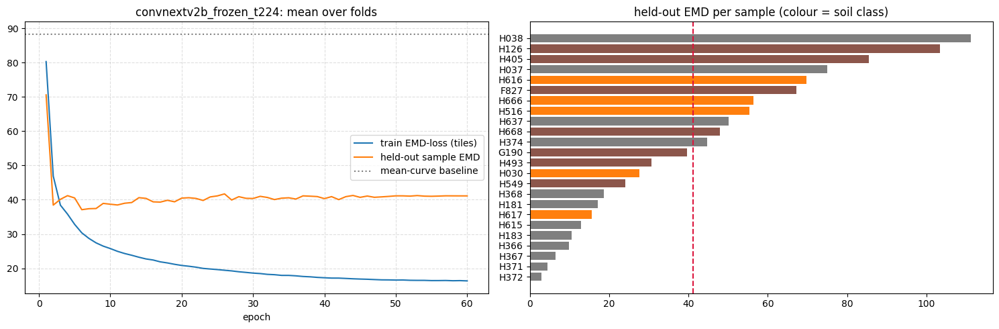

[start] convnext_t_frozen_t384 | elapsed 0.17 h
[tracker] convnext_t_frozen_t384_20261031-123504


features convnext_tiny.fb_in22k_ft_in1k @ 384px:   0%|          | 0/12 [00:00<?, ?it/s]

Fold 01/24 | F827 (fine) | 24 val / 522 train tiles


/usr/local/lib/python3.13/dist-packages/lightning/pytorch/trainer/connectors/data_connector.py:434: The 'train_dataloader' does not have many workers which may be a bottleneck. Consider increasing the value of the `num_workers` argument` to `num_workers=3` in the `DataLoader` to improve performance.
/usr/local/lib/python3.13/dist-packages/lightning/pytorch/trainer/connectors/data_connector.py:434: The 'val_dataloader' does not have many workers which may be a bottleneck. Consider increasing the value of the `num_workers` argument` to `num_workers=3` in the `DataLoader` to improve performance.


    epoch 20/60 | train 32.53 | val 55.60
    epoch 40/60 | train 25.04 | val 70.84
    epoch 60/60 | train 23.74 | val 70.74
Fold 02/24 | G190 (fine) | 24 val / 522 train tiles


/usr/local/lib/python3.13/dist-packages/lightning/pytorch/trainer/connectors/data_connector.py:434: The 'predict_dataloader' does not have many workers which may be a bottleneck. Consider increasing the value of the `num_workers` argument` to `num_workers=3` in the `DataLoader` to improve performance.
/usr/local/lib/python3.13/dist-packages/lightning/pytorch/trainer/connectors/data_connector.py:434: The 'predict_dataloader' does not have many workers which may be a bottleneck. Consider increasing the value of the `num_workers` argument` to `num_workers=3` in the `DataLoader` to improve performance.
/usr/local/lib/python3.13/dist-packages/lightning/pytorch/trainer/connectors/data_connector.py:434: The 'train_dataloader' does not have many workers which may be a bottleneck. Consider increasing the value of the `num_workers` argument` to `num_workers=3` in the `DataLoader` to improve performance.
/usr/local/lib/python3.13/dist-packages/lightning/pytorch/trainer/connectors/data_connector.p

... (42 outputs left out)

    epoch 20/60 | train 31.57 | val 22.26
    epoch 40/60 | train 25.11 | val 47.89
    epoch 60/60 | train 22.66 | val 51.01
Fold 24/24 | H668 (fine) | 33 val / 513 train tiles


/usr/local/lib/python3.13/dist-packages/lightning/pytorch/trainer/connectors/data_connector.py:434: The 'predict_dataloader' does not have many workers which may be a bottleneck. Consider increasing the value of the `num_workers` argument` to `num_workers=3` in the `DataLoader` to improve performance.
/usr/local/lib/python3.13/dist-packages/lightning/pytorch/trainer/connectors/data_connector.py:434: The 'predict_dataloader' does not have many workers which may be a bottleneck. Consider increasing the value of the `num_workers` argument` to `num_workers=3` in the `DataLoader` to improve performance.
/usr/local/lib/python3.13/dist-packages/lightning/pytorch/trainer/connectors/data_connector.py:434: The 'train_dataloader' does not have many workers which may be a bottleneck. Consider increasing the value of the `num_workers` argument` to `num_workers=3` in the `DataLoader` to improve performance.
/usr/local/lib/python3.13/dist-packages/lightning/pytorch/trainer/connectors/data_connector.p

    epoch 20/60 | train 32.98 | val 42.28
    epoch 40/60 | train 27.27 | val 40.01
    epoch 60/60 | train 26.07 | val 41.00
[convnext_t_frozen_t384] LOSO EMD 41.14 ± 33.34 (median 31.18, mean-curve 88.32) | by class {'fine': 51.55, 'gravel': 29.97, 'sand': 53.37}


/usr/local/lib/python3.13/dist-packages/lightning/pytorch/trainer/connectors/data_connector.py:434: The 'predict_dataloader' does not have many workers which may be a bottleneck. Consider increasing the value of the `num_workers` argument` to `num_workers=3` in the `DataLoader` to improve performance.
/usr/local/lib/python3.13/dist-packages/lightning/pytorch/trainer/connectors/data_connector.py:434: The 'predict_dataloader' does not have many workers which may be a bottleneck. Consider increasing the value of the `num_workers` argument` to `num_workers=3` in the `DataLoader` to improve performance.


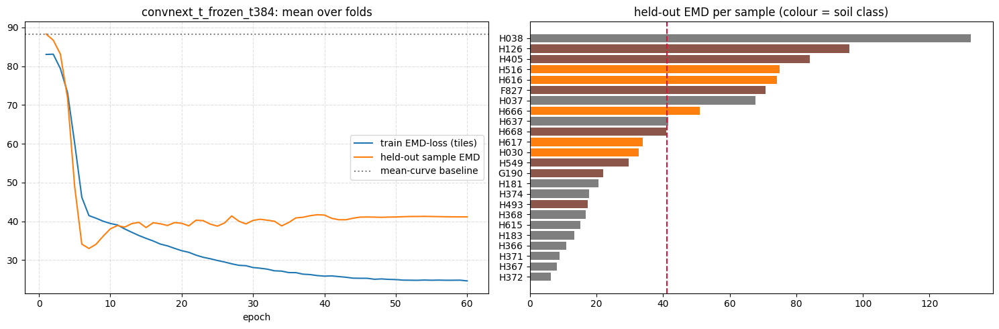

[start] convnext_t_frozen_t224_sgd | elapsed 0.20 h
[tracker] convnext_t_frozen_t224_sgd_20261031-123632
Fold 01/24 | F827 (fine) | 96 val / 2097 train tiles


/usr/local/lib/python3.13/dist-packages/lightning/pytorch/trainer/connectors/data_connector.py:434: The 'train_dataloader' does not have many workers which may be a bottleneck. Consider increasing the value of the `num_workers` argument` to `num_workers=3` in the `DataLoader` to improve performance.
/usr/local/lib/python3.13/dist-packages/lightning/pytorch/trainer/connectors/data_connector.py:434: The 'val_dataloader' does not have many workers which may be a bottleneck. Consider increasing the value of the `num_workers` argument` to `num_workers=3` in the `DataLoader` to improve performance.


    epoch 20/60 | train 25.56 | val 61.31
    epoch 40/60 | train 22.72 | val 65.99
    epoch 60/60 | train 22.16 | val 67.09
Fold 02/24 | G190 (fine) | 96 val / 2097 train tiles


/usr/local/lib/python3.13/dist-packages/lightning/pytorch/trainer/connectors/data_connector.py:434: The 'predict_dataloader' does not have many workers which may be a bottleneck. Consider increasing the value of the `num_workers` argument` to `num_workers=3` in the `DataLoader` to improve performance.
/usr/local/lib/python3.13/dist-packages/lightning/pytorch/trainer/connectors/data_connector.py:434: The 'predict_dataloader' does not have many workers which may be a bottleneck. Consider increasing the value of the `num_workers` argument` to `num_workers=3` in the `DataLoader` to improve performance.
/usr/local/lib/python3.13/dist-packages/lightning/pytorch/trainer/connectors/data_connector.py:434: The 'train_dataloader' does not have many workers which may be a bottleneck. Consider increasing the value of the `num_workers` argument` to `num_workers=3` in the `DataLoader` to improve performance.
/usr/local/lib/python3.13/dist-packages/lightning/pytorch/trainer/connectors/data_connector.p

    epoch 20/60 | train 26.70 | val 15.86
    epoch 40/60 | train 23.95 | val 16.95
    epoch 60/60 | train 22.82 | val 17.30
Fold 03/24 | H030 (sand) | 120 val / 2073 train tiles


/usr/local/lib/python3.13/dist-packages/lightning/pytorch/trainer/connectors/data_connector.py:434: The 'predict_dataloader' does not have many workers which may be a bottleneck. Consider increasing the value of the `num_workers` argument` to `num_workers=3` in the `DataLoader` to improve performance.
/usr/local/lib/python3.13/dist-packages/lightning/pytorch/trainer/connectors/data_connector.py:434: The 'predict_dataloader' does not have many workers which may be a bottleneck. Consider increasing the value of the `num_workers` argument` to `num_workers=3` in the `DataLoader` to improve performance.
/usr/local/lib/python3.13/dist-packages/lightning/pytorch/trainer/connectors/data_connector.py:434: The 'train_dataloader' does not have many workers which may be a bottleneck. Consider increasing the value of the `num_workers` argument` to `num_workers=3` in the `DataLoader` to improve performance.
/usr/local/lib/python3.13/dist-packages/lightning/pytorch/trainer/connectors/data_connector.p

... (40 outputs left out)

    epoch 20/60 | train 25.14 | val 48.97
    epoch 40/60 | train 22.31 | val 53.78
    epoch 60/60 | train 21.83 | val 55.34
Fold 24/24 | H668 (fine) | 132 val / 2061 train tiles


/usr/local/lib/python3.13/dist-packages/lightning/pytorch/trainer/connectors/data_connector.py:434: The 'predict_dataloader' does not have many workers which may be a bottleneck. Consider increasing the value of the `num_workers` argument` to `num_workers=3` in the `DataLoader` to improve performance.
/usr/local/lib/python3.13/dist-packages/lightning/pytorch/trainer/connectors/data_connector.py:434: The 'predict_dataloader' does not have many workers which may be a bottleneck. Consider increasing the value of the `num_workers` argument` to `num_workers=3` in the `DataLoader` to improve performance.
/usr/local/lib/python3.13/dist-packages/lightning/pytorch/trainer/connectors/data_connector.py:434: The 'train_dataloader' does not have many workers which may be a bottleneck. Consider increasing the value of the `num_workers` argument` to `num_workers=3` in the `DataLoader` to improve performance.
/usr/local/lib/python3.13/dist-packages/lightning/pytorch/trainer/connectors/data_connector.p

    epoch 20/60 | train 26.25 | val 41.46
    epoch 40/60 | train 24.05 | val 41.33
    epoch 60/60 | train 23.09 | val 40.37
[convnext_t_frozen_t224_sgd] LOSO EMD 39.43 ± 32.14 (median 29.17, mean-curve 88.32) | by class {'fine': 50.9, 'gravel': 29.03, 'sand': 48.33}


/usr/local/lib/python3.13/dist-packages/lightning/pytorch/trainer/connectors/data_connector.py:434: The 'predict_dataloader' does not have many workers which may be a bottleneck. Consider increasing the value of the `num_workers` argument` to `num_workers=3` in the `DataLoader` to improve performance.
/usr/local/lib/python3.13/dist-packages/lightning/pytorch/trainer/connectors/data_connector.py:434: The 'predict_dataloader' does not have many workers which may be a bottleneck. Consider increasing the value of the `num_workers` argument` to `num_workers=3` in the `DataLoader` to improve performance.


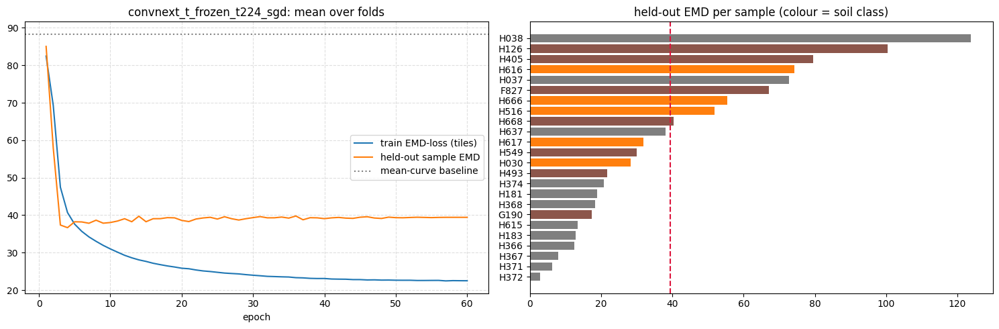

[start] r18_frozen_t224 | elapsed 0.23 h
[tracker] r18_frozen_t224_20261031-123840


model.safetensors: reconstructing file:   0%|          |  0.00B / 46.8MB            

model.safetensors: downloading bytes:           |  0.00B            

features resnet18.a1_in1k @ 224px:   0%|          | 0/43 [00:00<?, ?it/s]

Fold 01/24 | F827 (fine) | 96 val / 2097 train tiles


/usr/local/lib/python3.13/dist-packages/lightning/pytorch/trainer/connectors/data_connector.py:434: The 'train_dataloader' does not have many workers which may be a bottleneck. Consider increasing the value of the `num_workers` argument` to `num_workers=3` in the `DataLoader` to improve performance.
/usr/local/lib/python3.13/dist-packages/lightning/pytorch/trainer/connectors/data_connector.py:434: The 'val_dataloader' does not have many workers which may be a bottleneck. Consider increasing the value of the `num_workers` argument` to `num_workers=3` in the `DataLoader` to improve performance.


... (44 outputs left out)

    epoch 20/60 | train 24.72 | val 58.14
    epoch 40/60 | train 21.57 | val 58.30
    epoch 60/60 | train 20.57 | val 58.73
Fold 24/24 | H668 (fine) | 132 val / 2061 train tiles


/usr/local/lib/python3.13/dist-packages/lightning/pytorch/trainer/connectors/data_connector.py:434: The 'predict_dataloader' does not have many workers which may be a bottleneck. Consider increasing the value of the `num_workers` argument` to `num_workers=3` in the `DataLoader` to improve performance.
/usr/local/lib/python3.13/dist-packages/lightning/pytorch/trainer/connectors/data_connector.py:434: The 'predict_dataloader' does not have many workers which may be a bottleneck. Consider increasing the value of the `num_workers` argument` to `num_workers=3` in the `DataLoader` to improve performance.
/usr/local/lib/python3.13/dist-packages/lightning/pytorch/trainer/connectors/data_connector.py:434: The 'train_dataloader' does not have many workers which may be a bottleneck. Consider increasing the value of the `num_workers` argument` to `num_workers=3` in the `DataLoader` to improve performance.
/usr/local/lib/python3.13/dist-packages/lightning/pytorch/trainer/connectors/data_connector.p

    epoch 20/60 | train 25.51 | val 37.93
    epoch 40/60 | train 21.62 | val 34.24
    epoch 60/60 | train 21.19 | val 33.88
[r18_frozen_t224] LOSO EMD 36.57 ± 27.83 (median 29.70, mean-curve 88.32) | by class {'fine': 42.12, 'gravel': 29.16, 'sand': 46.58}


/usr/local/lib/python3.13/dist-packages/lightning/pytorch/trainer/connectors/data_connector.py:434: The 'predict_dataloader' does not have many workers which may be a bottleneck. Consider increasing the value of the `num_workers` argument` to `num_workers=3` in the `DataLoader` to improve performance.
/usr/local/lib/python3.13/dist-packages/lightning/pytorch/trainer/connectors/data_connector.py:434: The 'predict_dataloader' does not have many workers which may be a bottleneck. Consider increasing the value of the `num_workers` argument` to `num_workers=3` in the `DataLoader` to improve performance.


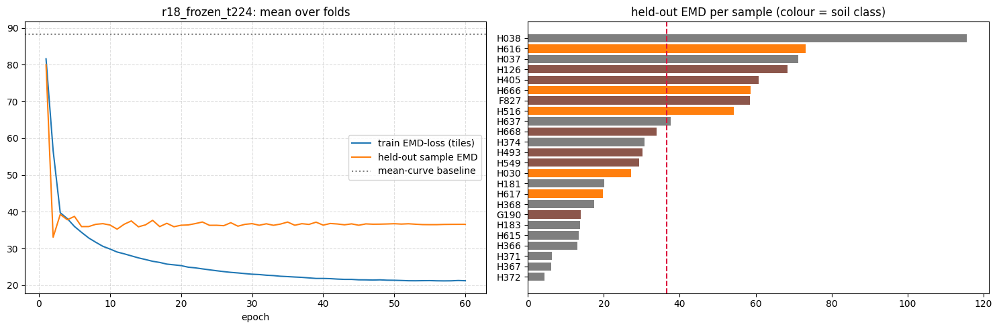

In [14]:
EXPERIMENTS = [
    dict(name="effb0_frozen_t224", backbone="tf_efficientnet_b0.ns_jft_in1k", tile_px=224),
    dict(name="convnext_t_frozen_t224", backbone="convnext_tiny.fb_in22k_ft_in1k", tile_px=224),
    dict(name="convnextv2b_frozen_t224", backbone="convnextv2_base.fcmae_ft_in22k_in1k", tile_px=224),
    dict(name="convnext_t_frozen_t384", backbone="convnext_tiny.fb_in22k_ft_in1k", tile_px=384),
    dict(name="convnext_t_frozen_t224_sgd", backbone="convnext_tiny.fb_in22k_ft_in1k", tile_px=224,
         optimizer="sgd", lr=1e-2),
    dict(name="r18_frozen_t224", backbone="resnet18.a1_in1k", tile_px=224),     # "простий pretrained CNN" з завдання
]
RUNS = globals().get("RUNS", {})


def _frozen_exp(exp):
    run = run_loso(**exp)
    report_loso(run)
    make_submission(run.test_pred, f"submission_{exp['name']}.csv", run.tracker)
    RUNS[exp["name"]] = run


for exp in EXPERIMENTS:
    safe(exp["name"], lambda exp=exp: _frozen_exp(exp), 0.1)

In [15]:
# samples used for interpretation / scale tests / CKA: the 3 hardest and the 2 easiest samples of the first
# frozen CNN run (chosen from its OOF errors, nothing hard-coded). Their fold weights are kept for every fine-tuned model.
def pick_vis_sids(ref="effb0_frozen_t224", n_hard=3, n_easy=2):
    per = read_sample_table(RUNS[ref].tracker.dir / "per_sample.csv")["emd"].sort_values()
    return list(per.index[-n_hard:][::-1]) + list(per.index[:n_easy])


try:
    VIS_SIDS = pick_vis_sids()
except Exception:
    traceback.print_exc()
    VIS_SIDS = SIDS[:5]
print("visualisation samples:", {s: SOIL[s] for s in VIS_SIDS})

visualisation samples: {'H038': 'gravel', 'H126': 'fine', 'H405': 'fine', 'H372': 'gravel', 'H371': 'gravel'}


## Experiment: fine-tuning on tiles (slower)

Whole network trained on tile images with scale-safe augmentation, frozen BN statistics, discriminative LR
(head `LR`, backbone `BACKBONE_LR`). Roughly 10–20 min per LOSO run for ConvNeXt-T on a T4.
Compare `freeze_bn=True` vs `False` on a BatchNorm backbone (ResNet / EfficientNet) for the BN question.

[tracker] convnext_t_ft_t224_20261031-124118
Fold 01/24 | F827 (fine) | 96 val / 2097 train tiles
    epoch 08/8 | train 20.25 | val 61.13
Fold 02/24 | G190 (fine) | 96 val / 2097 train tiles
    epoch 08/8 | train 20.21 | val 17.39
Fold 03/24 | H030 (sand) | 120 val / 2073 train tiles
    epoch 08/8 | train 20.20 | val 25.37
Fold 04/24 | H037 (gravel) | 108 val / 2085 train tiles
    epoch 08/8 | train 20.35 | val 72.75
Fold 05/24 | H038 (gravel) | 156 val / 2037 train tiles
    epoch 08/8 | train 17.19 | val 122.25
Fold 06/24 | H126 (fine) | 60 val / 2133 train tiles
    epoch 08/8 | train 17.52 | val 112.33
Fold 07/24 | H181 (gravel) | 96 val / 2097 train tiles
    epoch 08/8 | train 20.81 | val 20.42
Fold 08/24 | H183 (gravel) | 120 val / 2073 train tiles
    epoch 08/8 | train 21.22 | val 13.82
Fold 09/24 | H366 (gravel) | 48 val / 2145 train tiles
    epoch 08/8 | train 20.66 | val 11.12
Fold 10/24 | H367 (gravel) | 60 val / 2133 train tiles
    epoch 08/8 | train 20.26 | val 7.9

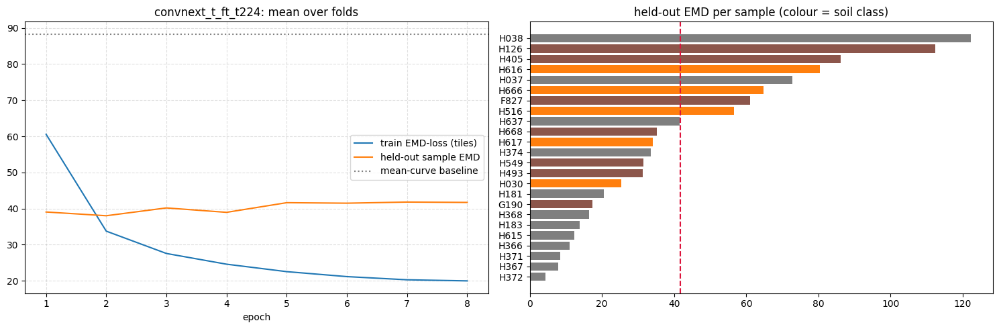

In [16]:
FT_EXPERIMENTS = [
    dict(name="convnext_t_ft_t224", backbone="convnext_tiny.fb_in22k_ft_in1k", tile_px=224,
         freeze_backbone=False, epochs=8, backbone_lr=2e-5, keep_weights=VIS_SIDS),
]
for exp in FT_EXPERIMENTS:
    run = run_loso(**exp)
    report_loso(run)
    make_submission(run.test_pred, f"submission_{exp['name']}.csv", run.tracker)
    RUNS[exp["name"]] = run

# Part 2–3 — ViT & SSL

In [17]:
# ===== C1: overrides for ViT / SSL (run AFTER all old cells) =====
from types import SimpleNamespace

MODEL_KWARGS = {}     # backbone -> kwargs for timm.create_model (img_size=224, drop_path_rate=...)
SCRATCH = set()       # backbones trained from random init (no pretrained weights)
LLRD = {}             # backbone -> layer-wise lr decay factor (ViT only)
POOL = {}             # backbone -> "avgcat": concat(CLS, mean of patch tokens); default = timm pooling
CUSTOM_BUILDERS = {}  # name -> callable() -> nn.Module with .num_features (own ViT, C9)
NORM = {}             # backbone -> (mean, std) override
NO_DECAY_KEYS = ("pos_embed", "cls_token", "reg_token", "relative_position_bias", "rel_pos")


def set_norm(backbone):
    """Normalisation of the checkpoint (AugReg ViT: 0.5/0.5, DINOv2: ImageNet). tile_transform reads CFG.MEAN/STD."""
    mean, std = NORM.get(backbone, (None, None))
    if mean is None:
        try:
            pc = timm.models.get_pretrained_cfg(backbone)
            mean, std = pc.mean, pc.std
        except Exception:
            mean, std = (0.485, 0.456, 0.406), (0.229, 0.224, 0.225)
    CFG.MEAN, CFG.STD = tuple(mean), tuple(std)
    print(f"[norm] {backbone}: mean={CFG.MEAN} std={CFG.STD}")


def build_backbone(name):
    if name in CUSTOM_BUILDERS:
        return CUSTOM_BUILDERS[name]()
    return timm.create_model(name, pretrained=name not in SCRATCH, num_classes=0, **MODEL_KWARGS.get(name, {}))


def embed(model, x, mode="default"):
    if mode == "avgcat":                      # ViT only: CLS + mean of patch tokens
        t = model.forward_features(x)
        n = model.num_prefix_tokens
        return torch.cat([t[:, 0], t[:, n:].mean(1)], dim=-1)
    return model(x)


def embed_dim(model, mode="default"):
    return model.num_features * (2 if mode == "avgcat" else 1)


@torch.no_grad()
def extract_features(backbone, tile_px):
    set_norm(backbone)
    pool = POOL.get(backbone, "default")
    tag = re.sub(r"[^A-Za-z0-9._-]", "_", backbone)
    suffix = ("" if pool == "default" else f"_{pool}") + ("_scratch" if backbone in SCRATCH else "")
    path = CFG.FEAT_DIR / f"{tag}_t{tile_px}_d4{suffix}.npy"
    if path.exists():
        return np.load(path)
    idx = TILE_INDEX[tile_px]
    model = build_backbone(backbone).to(CFG.DEVICE).eval()
    loader = DataLoader(TileDataset(idx["path"], None, tile_transform(False)), batch_size=64,
                        num_workers=CFG.NUM_WORKERS, pin_memory=CFG.DEVICE == "cuda")
    out = []
    for x in tqdm(loader, desc=f"features {backbone} @ {tile_px}px"):
        x = x.to(CFG.DEVICE, non_blocking=True)
        with torch.autocast("cuda", enabled=CFG.DEVICE == "cuda"):
            out.append(torch.stack([embed(model, v, pool).float() for v in dihedral_views(x)], dim=1).half().cpu())
    feats = torch.cat(out).numpy()
    np.save(path, feats)
    del model
    if CFG.DEVICE == "cuda":
        torch.cuda.empty_cache()
    return feats


def llrd_groups(model, base_lr, gamma):
    """Layer-wise lr decay: top layer gets base_lr, each deeper layer is multiplied by gamma."""
    n_blocks = len(model.blocks)
    buckets = {}
    for n, p in model.named_parameters():
        if n.startswith("blocks."):
            lid = int(n.split(".")[1]) + 1
        elif n.startswith(("patch_embed", "cls_token", "pos_embed", "reg_token")):
            lid = 0
        else:
            lid = n_blocks + 1                # final norm etc.
        buckets.setdefault(lid, []).append((n, p))
    return [(items, base_lr * gamma ** (n_blocks + 1 - lid)) for lid, items in sorted(buckets.items())]


def _named(obj):
    return list(obj.named_parameters()) if hasattr(obj, "named_parameters") else list(obj)


def param_groups(module_lrs, weight_decay):
    """No weight decay on biases, norms (ndim<=1) and pos_embed / cls_token / reg_token."""
    groups = []
    for obj, lr in module_lrs:
        decay, no_decay = [], []
        for n, p in _named(obj):
            if not p.requires_grad:
                continue
            (no_decay if p.ndim <= 1 or any(k in n for k in NO_DECAY_KEYS) else decay).append(p)
        groups += [{"params": decay, "lr": lr, "weight_decay": weight_decay},
                   {"params": no_decay, "lr": lr, "weight_decay": 0.0}]
    return [g for g in groups if g["params"]]


class ImageNet(nn.Module):
    def __init__(self, backbone, freeze_bn=True):
        super().__init__()
        self.freeze_bn, self.name, self.lora = freeze_bn, backbone, False
        self.pool = POOL.get(backbone, "default")
        self.backbone = build_backbone(backbone)
        self.head = CurveHead(embed_dim(self.backbone, self.pool))

    def train(self, mode=True):
        super().train(mode)
        if mode and self.freeze_bn:           # keep ImageNet BN statistics (no-op for ViT)
            for m in self.backbone.modules():
                if isinstance(m, nn.modules.batchnorm._BatchNorm):
                    m.eval()
        return self

    def forward(self, x):
        return self.head(embed(self.backbone, x, self.pool))

    def lr_groups(self, lr, backbone_lr):
        if getattr(self, "lora", False):          # LoRA: only the adapters train, one lr for all of them
            return [(self.head, lr), (self.backbone, backbone_lr)]
        gamma = LLRD.get(self.name)
        if gamma is None:
            return [(self.head, lr), (self.backbone, backbone_lr)]
        return [(self.head, lr)] + llrd_groups(self.backbone, backbone_lr, gamma)


# wrappers (guarded, so re-running this cell does not stack them)
if "_run_loso_orig" not in globals():
    _run_loso_orig, _report_loso_orig = run_loso, report_loso


def run_loso(name, backbone, **kw):
    set_norm(backbone)
    return _run_loso_orig(name, backbone, **kw)


def report_loso(run, show=True):
    if run.history is None or len(run.history) == 0:      # sklearn heads have no training history
        run = SimpleNamespace(**{**vars(run), "history": pd.DataFrame(
            {"epoch": [1], "train_loss": [np.nan], "val_emd": [np.nan]})})
    return _report_loso_orig(run, show)


print("C1 ok: overrides installed")

C1 ok: overrides installed


In [18]:
# ===== building blocks: own ViT, LoRA, LP stage, grouped batches, GroupNorm swap, ablation tables =====
# ---- own ViT-S/16 (Lecture-1 style; parameter names match timm so timm weights load into it) ----
class DropPath(nn.Module):
    def __init__(self, p=0.0):
        super().__init__()
        self.p = p

    def forward(self, x):
        if self.p == 0.0 or not self.training:
            return x
        keep = 1.0 - self.p
        mask = x.new_empty(x.shape[0], *([1] * (x.ndim - 1))).bernoulli_(keep)
        return x * mask / keep


class OwnAttention(nn.Module):
    def __init__(self, dim, heads):
        super().__init__()
        self.heads = heads
        self.qkv = nn.Linear(dim, dim * 3)
        self.proj = nn.Linear(dim, dim)

    def forward(self, x):
        b, n, c = x.shape
        q, k, v = self.qkv(x).reshape(b, n, 3, self.heads, c // self.heads).permute(2, 0, 3, 1, 4)
        x = F.scaled_dot_product_attention(q, k, v)
        return self.proj(x.transpose(1, 2).reshape(b, n, c))


class OwnMlp(nn.Module):
    def __init__(self, dim, hidden):
        super().__init__()
        self.fc1, self.act, self.fc2 = nn.Linear(dim, hidden), nn.GELU(), nn.Linear(hidden, dim)

    def forward(self, x):
        return self.fc2(self.act(self.fc1(x)))


class OwnBlock(nn.Module):
    def __init__(self, dim, heads, mlp_ratio, drop_path):
        super().__init__()
        self.norm1, self.attn = nn.LayerNorm(dim, eps=1e-6), OwnAttention(dim, heads)
        self.norm2, self.mlp = nn.LayerNorm(dim, eps=1e-6), OwnMlp(dim, int(dim * mlp_ratio))
        self.drop_path = DropPath(drop_path)

    def forward(self, x):
        x = x + self.drop_path(self.attn(self.norm1(x)))
        return x + self.drop_path(self.mlp(self.norm2(x)))


class OwnPatchEmbed(nn.Module):
    def __init__(self, patch, dim):
        super().__init__()
        self.proj = nn.Conv2d(3, dim, patch, patch)

    def forward(self, x):
        return self.proj(x).flatten(2).transpose(1, 2)


class OwnViT(nn.Module):
    """ViT-S/16: patch embedding -> [CLS] + learned absolute position embedding -> pre-norm blocks -> LayerNorm."""
    def __init__(self, img_size=224, patch=16, dim=384, depth=12, heads=6, mlp_ratio=4.0, drop_path=0.1):
        super().__init__()
        self.num_features, self.num_prefix_tokens = dim, 1
        self.patch_embed = OwnPatchEmbed(patch, dim)
        self.cls_token = nn.Parameter(torch.zeros(1, 1, dim))
        self.pos_embed = nn.Parameter(torch.zeros(1, (img_size // patch) ** 2 + 1, dim))
        dpr = np.linspace(0, drop_path, depth).tolist()
        self.blocks = nn.ModuleList([OwnBlock(dim, heads, mlp_ratio, dpr[i]) for i in range(depth)])
        self.norm = nn.LayerNorm(dim, eps=1e-6)
        nn.init.trunc_normal_(self.pos_embed, std=0.02)
        nn.init.trunc_normal_(self.cls_token, std=0.02)
        self.apply(self._init)

    @staticmethod
    def _init(m):
        if isinstance(m, nn.Linear):
            nn.init.trunc_normal_(m.weight, std=0.02)
            nn.init.zeros_(m.bias)

    def forward_features(self, x):
        x = self.patch_embed(x)
        x = torch.cat([self.cls_token.expand(x.shape[0], -1, -1), x], dim=1) + self.pos_embed
        for blk in self.blocks:
            x = blk(x)
        return self.norm(x)

    def forward(self, x):
        return self.forward_features(x)[:, 0]


# ---- LoRA on the attention projections ----
class LoRALinear(nn.Module):
    """y = W x + (alpha / r) * B A x ; W is frozen, only A (r x in) and B (out x r) are trained.
    After training W' = W + (alpha / r) * B A can be merged, so inference has no extra cost."""
    def __init__(self, base, r=8, alpha=16):
        super().__init__()
        self.base, self.scale = base, alpha / r
        self.lora_A = nn.Parameter(torch.empty(r, base.in_features))
        self.lora_B = nn.Parameter(torch.zeros(base.out_features, r))
        nn.init.kaiming_uniform_(self.lora_A, a=math.sqrt(5))

    def forward(self, x):
        return self.base(x) + (x @ self.lora_A.t() @ self.lora_B.t()) * self.scale


def apply_lora(backbone, r=8, alpha=16, targets=("qkv", "proj")):
    """Freeze the whole backbone and wrap attn.qkv / attn.proj of every block. Returns the number of trainable params."""
    for p in backbone.parameters():
        p.requires_grad = False
    for blk in backbone.blocks:
        for t in targets:
            setattr(blk.attn, t, LoRALinear(getattr(blk.attn, t), r, alpha))
    return sum(p.numel() for p in backbone.parameters() if p.requires_grad)


# ---- batches that contain tiles of only a few physical samples ----
class GroupedBatchSampler(torch.utils.data.Sampler):
    def __init__(self, sample_ids, batch_size, n_groups, seed=0):
        self.sid = np.asarray(sample_ids)
        self.by = {s: np.where(self.sid == s)[0] for s in np.unique(self.sid)}
        self.bs, self.k = batch_size, n_groups
        self.n_batches = max(1, len(self.sid) // batch_size)
        self.rng = np.random.default_rng(seed)

    def __len__(self):
        return self.n_batches

    def __iter__(self):
        sids = list(self.by)
        for _ in range(self.n_batches):
            chosen = self.rng.choice(sids, size=min(self.k, len(sids)), replace=False)
            pool = np.concatenate([self.by[s] for s in chosen])
            yield self.rng.choice(pool, size=self.bs, replace=len(pool) < self.bs).tolist()


# ---- LP stage of LP-FT: train only the head on cached features ----
def lp_stage(head, feats_tr, y_tr, epochs=40, lr=1e-3, wd=1e-4, bs=256):
    dev = CFG.DEVICE
    head.to(dev).train()
    X = torch.from_numpy(feats_tr).to(dev)                      # (N, views, D) half
    Y = torch.from_numpy(y_tr).float().to(dev)
    n = len(X)
    bs = max(1, min(bs, n))
    steps = epochs * max(1, n // bs)
    opt = AdamW(head.parameters(), lr=lr, weight_decay=wd)
    sched = LambdaLR(opt, warmup_cosine(steps, max(1, steps // 20)))
    loss_fn = EMDLoss().to(dev)
    for _ in range(epochs):
        perm = torch.randperm(n, device=dev)
        for i in range(0, n - bs + 1, bs):
            b = perm[i:i + bs]
            v = torch.randint(0, X.shape[1], (len(b),), device=dev)
            loss = loss_fn(head(X[b, v].float()), Y[b])
            opt.zero_grad(set_to_none=True)
            loss.backward()
            opt.step()
            sched.step()
    head.eval()
    return head


# ---- BatchNorm -> GroupNorm (keeps the pretrained affine parameters, drops the running statistics) ----
def bn_to_gn(module, groups=32):
    for name, child in module.named_children():
        if isinstance(child, nn.modules.batchnorm._BatchNorm):
            c = child.num_features
            gn = nn.GroupNorm(groups if c % groups == 0 else math.gcd(c, groups), c, eps=child.eps, affine=True)
            with torch.no_grad():
                gn.weight.copy_(child.weight)
                gn.bias.copy_(child.bias)
            setattr(module, name, gn)
        else:
            bn_to_gn(child, groups)
    return module


# ---- backbones used by the new blocks ----
R18 = "resnet18.a1_in1k"
VITS = "vit_small_patch16_224.augreg_in21k_ft_in1k"
DINO_S = "vit_small_patch14_dinov2.lvd142m"
D3 = "vit_small_patch16_dinov3.lvd1689m"
MAEB = "vit_base_patch16_224.mae"
EFFB0 = "tf_efficientnet_b0.ns_jft_in1k"
CONVNEXT_T = "convnext_tiny.fb_in22k_ft_in1k"
DEIT_S = "deit_small_patch16_224.fb_in1k"
SWIN_T = "swin_tiny_patch4_window7_224.ms_in22k_ft_in1k"
MAXVIT_T = "maxvit_tiny_tf_224.in1k"
P32 = "vit_small_patch32_224.augreg_in21k_ft_in1k"

CUSTOM_BUILDERS["own_vit_s16"] = lambda: OwnViT(drop_path=0.1)
NORM["own_vit_s16"] = ((0.5, 0.5, 0.5), (0.5, 0.5, 0.5))
CUSTOM_BUILDERS["resnet18_gn"] = lambda: bn_to_gn(timm.create_model(R18, pretrained=True, num_classes=0))
NORM["resnet18_gn"] = ((0.485, 0.456, 0.406), (0.229, 0.224, 0.225))

# ViT recipe shared by all ViT-like encoders (CLS pooling for fine-tuning, drop-path 0.1, LLRD 0.75)
for _bb in (VITS, DINO_S, D3, MAEB, DEIT_S, P32):
    MODEL_KWARGS.setdefault(_bb, dict(img_size=224, drop_path_rate=0.1))
    LLRD.setdefault(_bb, 0.75)
    POOL.setdefault(_bb, "default")
MODEL_KWARGS.setdefault(SWIN_T, dict(drop_path_rate=0.1))


# ---- ablation tables: CV of several runs on the same subset of folds ----
def registry_table():
    reg = pd.read_csv(CFG.EXP_DIR / "registry.csv")
    return reg.sort_values("finished_at").drop_duplicates("name", keep="last").set_index("name")


def subset_table(names, base, fname=None):
    """Per-sample EMD of several runs restricted to SUB_SIDS, paired difference against `base` (negative = better)."""
    reg = registry_table()

    def per(n):
        return read_sample_table(Path(reg.loc[n, "run_dir"]) / "per_sample.csv")["emd"].reindex(SUB_SIDS).dropna()

    b, rows = per(base), []
    for n in [base] + [x for x in names if x != base]:
        if n not in reg.index:
            print(f"(missing run {n})")
            continue
        p = per(n)
        d = p.loc[p.index.intersection(b.index)] - b.loc[p.index.intersection(b.index)]
        rows.append(dict(run=n, folds=len(p), cv=p.mean(), std=p.std(), diff_vs_base=d.mean(), wins=int((d < 0).sum()),
                         gpu_h=reg.loc[n, "gpu_hours"], peak_gb=reg.loc[n, "peak_mem_gb"],
                         params_M=reg.loc[n].get("params_M", np.nan), trainable_M=reg.loc[n].get("trainable_M", np.nan)))
    tab = pd.DataFrame(rows).round(3)
    display(tab)
    if fname:
        tab.to_csv(CFG.OUTPUT_DIR / fname, index=False)
    return tab


def run_sub(name, backbone, tile_px=224, **kw):
    """Fine-tuning run on the ablation folds (SUB_SIDS), same defaults as the main ViT recipe."""
    base = dict(freeze_backbone=False, epochs=8, subset=True, keep_weights=False)
    base.update(kw)
    run = run_loso(name=name, backbone=backbone, tile_px=tile_px, **base)
    report_loso(run, show=False)
    RUNS[name] = run
    return run


print("building blocks ok | ablation folds:", SUB_SIDS)

building blocks ok | ablation folds: ['F827', 'G190', 'H037', 'H183', 'H366', 'H368', 'H516', 'H666']


In [19]:
t = timm.create_model("vit_small_patch16_224", pretrained=False, num_classes=0).eval()
o = OwnViT(drop_path=0.0).eval()
o.load_state_dict(t.state_dict())
x = torch.randn(2, 3, 224, 224)
with torch.no_grad():
    print("OwnViT == timm ViT-S/16:", torch.allclose(t(x), o(x), atol=1e-4))

OwnViT == timm ViT-S/16: True


### C2 — smoke test of candidate backbones

In [20]:
print("timm", timm.__version__)
for pat in ("*dinov2*", "*dinov3*", "*.mae"):
    print(pat, "->", timm.list_models(pat, pretrained=True)[:8])

CANDIDATES = {
    "vit_small_patch16_224.augreg_in21k_ft_in1k": dict(img_size=224),   # supervised ViT-S
    "vit_small_patch14_dinov2.lvd142m": dict(img_size=224),             # SSL: DINOv2-S
    "vit_base_patch14_dinov2.lvd142m": dict(img_size=224),              # SSL: DINOv2-B
    "vit_small_patch16_dinov3.lvd1689m": dict(img_size=224),            # SSL: DINOv3-S (needs recent timm)
    "vit_base_patch16_224.mae": dict(img_size=224),                     # SSL: MAE-B
}
for _k, _v in CANDIDATES.items():
    MODEL_KWARGS.setdefault(_k, _v)
    
rows, OK_BACKBONES = [], []
x = torch.randn(4, 3, 224, 224, device=CFG.DEVICE)
for name in CANDIDATES:
    m = None
    try:
        t0 = time.time()
        m = build_backbone(name).to(CFG.DEVICE).eval()
        set_norm(name)
        with torch.no_grad(), torch.autocast("cuda", enabled=CFG.DEVICE == "cuda"):
            d = embed(m, x).float()
            a = embed(m, x, "avgcat").float()
        rows.append(dict(backbone=name, ok=True, dim_default=d.shape[-1], dim_avgcat=a.shape[-1],
                         params_M=round(sum(p.numel() for p in m.parameters()) / 1e6, 1),
                         prefix_tokens=m.num_prefix_tokens, sec=round(time.time() - t0, 1), error=""))
        OK_BACKBONES.append(name)
    except Exception as e:
        rows.append(dict(backbone=name, ok=False, error=f"{type(e).__name__}: {str(e)[:150]}"))
    finally:
        del m
        if CFG.DEVICE == "cuda":
            torch.cuda.empty_cache()
display(pd.DataFrame(rows))
print("usable:", OK_BACKBONES)

timm 1.0.29
*dinov2* -> ['vit_base_patch14_dinov2.lvd142m', 'vit_base_patch14_reg4_dinov2.lvd142m', 'vit_giant_patch14_dinov2.lvd142m', 'vit_giant_patch14_reg4_dinov2.lvd142m', 'vit_large_patch14_dinov2.lvd142m', 'vit_large_patch14_reg4_dinov2.lvd142m', 'vit_small_patch14_dinov2.lvd142m', 'vit_small_patch14_reg4_dinov2.lvd142m']
*dinov3* -> ['convnext_base.dinov3_lvd1689m', 'convnext_large.dinov3_lvd1689m', 'convnext_small.dinov3_lvd1689m', 'convnext_tiny.dinov3_lvd1689m', 'vit_7b_patch16_dinov3.lvd1689m', 'vit_7b_patch16_dinov3.sat493m', 'vit_base_patch16_dinov3.lvd1689m', 'vit_base_patch16_dinov3_qkvb.eupe_lvd1689m']
*.mae -> ['hiera_base_224.mae', 'hiera_base_plus_224.mae', 'hiera_huge_224.mae', 'hiera_large_224.mae', 'hiera_small_224.mae', 'hiera_tiny_224.mae', 'vit_base_patch16_224.mae', 'vit_huge_patch14_224.mae']


model.safetensors: reconstructing file:   0%|          |  0.00B / 88.2MB            

model.safetensors: downloading bytes:           |  0.00B            

[norm] vit_small_patch16_224.augreg_in21k_ft_in1k: mean=(0.5, 0.5, 0.5) std=(0.5, 0.5, 0.5)


model.safetensors: reconstructing file:   0%|          |  0.00B / 88.2MB            

model.safetensors: downloading bytes:           |  0.00B            

... (8 outputs left out)

model.safetensors: downloading bytes:           |  0.00B            

[norm] vit_base_patch16_224.mae: mean=(0.485, 0.456, 0.406) std=(0.229, 0.224, 0.225)


,backbone,ok,dim_default,dim_avgcat,params_M,prefix_tokens,sec,error
0,vit_small_patch16_224.augreg_in21k_ft_in1k,True,384,768,21.7,1,5.4,
1,vit_small_patch14_dinov2.lvd142m,True,384,768,21.6,1,1.1,
2,vit_base_patch14_dinov2.lvd142m,True,768,1536,85.7,1,2.3,
3,vit_small_patch16_dinov3.lvd1689m,True,384,768,21.6,5,2.9,
4,vit_base_patch16_224.mae,True,768,1536,85.8,1,2.6,


usable: ['vit_small_patch16_224.augreg_in21k_ft_in1k', 'vit_small_patch14_dinov2.lvd142m', 'vit_base_patch14_dinov2.lvd142m', 'vit_small_patch16_dinov3.lvd1689m', 'vit_base_patch16_224.mae']


### C0 — hypotheses (written before ViT/SSL results; CNN runs above are post-hoc)

**H1 (frozen features).** DINOv2/DINOv3 frozen features beat the supervised ViT-S and the ImageNet CNNs (LOSO EMD < 39), because SSL keeps texture / low-level cues that supervised ImageNet pretraining discards. MAE frozen is the worst (known weak linear-probe features). CLS + mean-patch ("avgcat") ≥ CLS only. Differences are inside the noise (std ≈ 30 over 24 samples), so I expect rankings in median / per-class EMD rather than a clear separation.

**H2 (heads).** Ridge / weighted kNN on the same frozen features are within ±3 EMD of the MLP-EMD head; kNN is worse on fine and sand soils.

**H3 (fine-tuning).** Fine-tuning a ViT on 24 samples does not beat its frozen features (as with ConvNeXt: FT 41.1 vs frozen 39–41), because of overfitting.

**H4 (scratch).** A ViT trained from scratch on ~2.7k tiles is close to the mean-curve baseline (EMD ≈ 80–88) and worse than any pretrained model.

### C3 — frozen ViT / SSL backbones (cached features, MLP-EMD head)

[norm] vit_small_patch16_224.augreg_in21k_ft_in1k: mean=(0.5, 0.5, 0.5) std=(0.5, 0.5, 0.5)
[tracker] vits_sup_frozen_avgcat_20261031-131918
[norm] vit_small_patch16_224.augreg_in21k_ft_in1k: mean=(0.5, 0.5, 0.5) std=(0.5, 0.5, 0.5)


features vit_small_patch16_224.augreg_in21k_ft_in1k @ 224px:   0%|          | 0/43 [00:00<?, ?it/s]

Fold 01/24 | F827 (fine) | 96 val / 2097 train tiles


/usr/local/lib/python3.13/dist-packages/lightning/pytorch/trainer/connectors/data_connector.py:434: The 'train_dataloader' does not have many workers which may be a bottleneck. Consider increasing the value of the `num_workers` argument` to `num_workers=3` in the `DataLoader` to improve performance.
/usr/local/lib/python3.13/dist-packages/lightning/pytorch/trainer/connectors/data_connector.py:434: The 'val_dataloader' does not have many workers which may be a bottleneck. Consider increasing the value of the `num_workers` argument` to `num_workers=3` in the `DataLoader` to improve performance.


    epoch 20/60 | train 21.17 | val 53.59
    epoch 40/60 | train 17.50 | val 58.65
    epoch 60/60 | train 16.90 | val 58.49
Fold 02/24 | G190 (fine) | 96 val / 2097 train tiles


/usr/local/lib/python3.13/dist-packages/lightning/pytorch/trainer/connectors/data_connector.py:434: The 'predict_dataloader' does not have many workers which may be a bottleneck. Consider increasing the value of the `num_workers` argument` to `num_workers=3` in the `DataLoader` to improve performance.
/usr/local/lib/python3.13/dist-packages/lightning/pytorch/trainer/connectors/data_connector.py:434: The 'predict_dataloader' does not have many workers which may be a bottleneck. Consider increasing the value of the `num_workers` argument` to `num_workers=3` in the `DataLoader` to improve performance.
/usr/local/lib/python3.13/dist-packages/lightning/pytorch/trainer/connectors/data_connector.py:434: The 'train_dataloader' does not have many workers which may be a bottleneck. Consider increasing the value of the `num_workers` argument` to `num_workers=3` in the `DataLoader` to improve performance.
/usr/local/lib/python3.13/dist-packages/lightning/pytorch/trainer/connectors/data_connector.p

... (42 outputs left out)

    epoch 20/60 | train 20.15 | val 61.09
    epoch 40/60 | train 16.64 | val 68.61
    epoch 60/60 | train 15.78 | val 70.08
Fold 24/24 | H668 (fine) | 132 val / 2061 train tiles


/usr/local/lib/python3.13/dist-packages/lightning/pytorch/trainer/connectors/data_connector.py:434: The 'predict_dataloader' does not have many workers which may be a bottleneck. Consider increasing the value of the `num_workers` argument` to `num_workers=3` in the `DataLoader` to improve performance.
/usr/local/lib/python3.13/dist-packages/lightning/pytorch/trainer/connectors/data_connector.py:434: The 'predict_dataloader' does not have many workers which may be a bottleneck. Consider increasing the value of the `num_workers` argument` to `num_workers=3` in the `DataLoader` to improve performance.
/usr/local/lib/python3.13/dist-packages/lightning/pytorch/trainer/connectors/data_connector.py:434: The 'train_dataloader' does not have many workers which may be a bottleneck. Consider increasing the value of the `num_workers` argument` to `num_workers=3` in the `DataLoader` to improve performance.
/usr/local/lib/python3.13/dist-packages/lightning/pytorch/trainer/connectors/data_connector.p

    epoch 20/60 | train 21.24 | val 38.46
    epoch 40/60 | train 17.01 | val 44.19
    epoch 60/60 | train 16.36 | val 45.49
[vits_sup_frozen_avgcat] LOSO EMD 40.88 ± 31.91 (median 30.59, mean-curve 88.32) | by class {'fine': 53.26, 'gravel': 30.46, 'sand': 48.58}


/usr/local/lib/python3.13/dist-packages/lightning/pytorch/trainer/connectors/data_connector.py:434: The 'predict_dataloader' does not have many workers which may be a bottleneck. Consider increasing the value of the `num_workers` argument` to `num_workers=3` in the `DataLoader` to improve performance.
/usr/local/lib/python3.13/dist-packages/lightning/pytorch/trainer/connectors/data_connector.py:434: The 'predict_dataloader' does not have many workers which may be a bottleneck. Consider increasing the value of the `num_workers` argument` to `num_workers=3` in the `DataLoader` to improve performance.


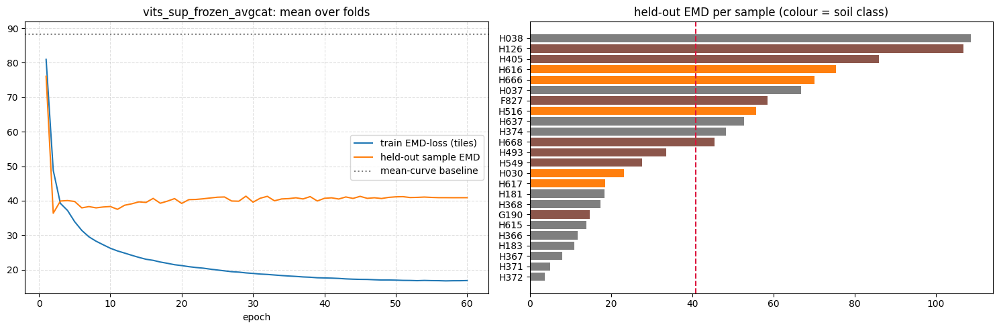

[norm] vit_small_patch14_dinov2.lvd142m: mean=(0.485, 0.456, 0.406) std=(0.229, 0.224, 0.225)
[tracker] dinov2s_frozen_avgcat_20261031-132205
[norm] vit_small_patch14_dinov2.lvd142m: mean=(0.485, 0.456, 0.406) std=(0.229, 0.224, 0.225)


features vit_small_patch14_dinov2.lvd142m @ 224px:   0%|          | 0/43 [00:00<?, ?it/s]

Fold 01/24 | F827 (fine) | 96 val / 2097 train tiles


/usr/local/lib/python3.13/dist-packages/lightning/pytorch/trainer/connectors/data_connector.py:434: The 'train_dataloader' does not have many workers which may be a bottleneck. Consider increasing the value of the `num_workers` argument` to `num_workers=3` in the `DataLoader` to improve performance.
/usr/local/lib/python3.13/dist-packages/lightning/pytorch/trainer/connectors/data_connector.py:434: The 'val_dataloader' does not have many workers which may be a bottleneck. Consider increasing the value of the `num_workers` argument` to `num_workers=3` in the `DataLoader` to improve performance.


    epoch 20/60 | train 23.62 | val 59.50
    epoch 40/60 | train 19.96 | val 73.88
    epoch 60/60 | train 19.21 | val 73.23
Fold 02/24 | G190 (fine) | 96 val / 2097 train tiles


/usr/local/lib/python3.13/dist-packages/lightning/pytorch/trainer/connectors/data_connector.py:434: The 'predict_dataloader' does not have many workers which may be a bottleneck. Consider increasing the value of the `num_workers` argument` to `num_workers=3` in the `DataLoader` to improve performance.
/usr/local/lib/python3.13/dist-packages/lightning/pytorch/trainer/connectors/data_connector.py:434: The 'predict_dataloader' does not have many workers which may be a bottleneck. Consider increasing the value of the `num_workers` argument` to `num_workers=3` in the `DataLoader` to improve performance.
/usr/local/lib/python3.13/dist-packages/lightning/pytorch/trainer/connectors/data_connector.py:434: The 'train_dataloader' does not have many workers which may be a bottleneck. Consider increasing the value of the `num_workers` argument` to `num_workers=3` in the `DataLoader` to improve performance.
/usr/local/lib/python3.13/dist-packages/lightning/pytorch/trainer/connectors/data_connector.p

... (42 outputs left out)

    epoch 20/60 | train 22.48 | val 60.36
    epoch 40/60 | train 19.09 | val 71.68
    epoch 60/60 | train 17.52 | val 73.19
Fold 24/24 | H668 (fine) | 132 val / 2061 train tiles


/usr/local/lib/python3.13/dist-packages/lightning/pytorch/trainer/connectors/data_connector.py:434: The 'predict_dataloader' does not have many workers which may be a bottleneck. Consider increasing the value of the `num_workers` argument` to `num_workers=3` in the `DataLoader` to improve performance.
/usr/local/lib/python3.13/dist-packages/lightning/pytorch/trainer/connectors/data_connector.py:434: The 'predict_dataloader' does not have many workers which may be a bottleneck. Consider increasing the value of the `num_workers` argument` to `num_workers=3` in the `DataLoader` to improve performance.
/usr/local/lib/python3.13/dist-packages/lightning/pytorch/trainer/connectors/data_connector.py:434: The 'train_dataloader' does not have many workers which may be a bottleneck. Consider increasing the value of the `num_workers` argument` to `num_workers=3` in the `DataLoader` to improve performance.
/usr/local/lib/python3.13/dist-packages/lightning/pytorch/trainer/connectors/data_connector.p

    epoch 20/60 | train 23.96 | val 43.79
    epoch 40/60 | train 19.34 | val 47.50
    epoch 60/60 | train 18.57 | val 48.93
[dinov2s_frozen_avgcat] LOSO EMD 42.66 ± 30.93 (median 35.30, mean-curve 88.32) | by class {'fine': 59.35, 'gravel': 28.8, 'sand': 52.54}


/usr/local/lib/python3.13/dist-packages/lightning/pytorch/trainer/connectors/data_connector.py:434: The 'predict_dataloader' does not have many workers which may be a bottleneck. Consider increasing the value of the `num_workers` argument` to `num_workers=3` in the `DataLoader` to improve performance.
/usr/local/lib/python3.13/dist-packages/lightning/pytorch/trainer/connectors/data_connector.py:434: The 'predict_dataloader' does not have many workers which may be a bottleneck. Consider increasing the value of the `num_workers` argument` to `num_workers=3` in the `DataLoader` to improve performance.


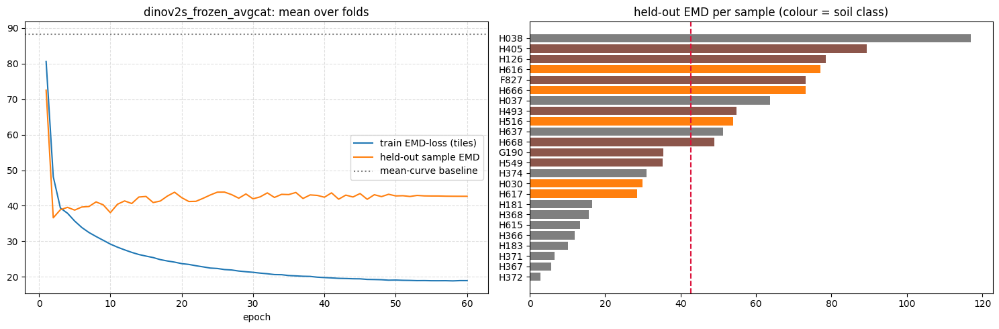

[norm] vit_base_patch14_dinov2.lvd142m: mean=(0.485, 0.456, 0.406) std=(0.229, 0.224, 0.225)
[tracker] dinov2b_frozen_avgcat_20261031-132456
[norm] vit_base_patch14_dinov2.lvd142m: mean=(0.485, 0.456, 0.406) std=(0.229, 0.224, 0.225)


features vit_base_patch14_dinov2.lvd142m @ 224px:   0%|          | 0/43 [00:00<?, ?it/s]

Fold 01/24 | F827 (fine) | 96 val / 2097 train tiles


/usr/local/lib/python3.13/dist-packages/lightning/pytorch/trainer/connectors/data_connector.py:434: The 'train_dataloader' does not have many workers which may be a bottleneck. Consider increasing the value of the `num_workers` argument` to `num_workers=3` in the `DataLoader` to improve performance.
/usr/local/lib/python3.13/dist-packages/lightning/pytorch/trainer/connectors/data_connector.py:434: The 'val_dataloader' does not have many workers which may be a bottleneck. Consider increasing the value of the `num_workers` argument` to `num_workers=3` in the `DataLoader` to improve performance.


    epoch 20/60 | train 22.09 | val 89.14
    epoch 40/60 | train 18.19 | val 83.03
    epoch 60/60 | train 17.07 | val 80.42
Fold 02/24 | G190 (fine) | 96 val / 2097 train tiles


/usr/local/lib/python3.13/dist-packages/lightning/pytorch/trainer/connectors/data_connector.py:434: The 'predict_dataloader' does not have many workers which may be a bottleneck. Consider increasing the value of the `num_workers` argument` to `num_workers=3` in the `DataLoader` to improve performance.
/usr/local/lib/python3.13/dist-packages/lightning/pytorch/trainer/connectors/data_connector.py:434: The 'predict_dataloader' does not have many workers which may be a bottleneck. Consider increasing the value of the `num_workers` argument` to `num_workers=3` in the `DataLoader` to improve performance.
/usr/local/lib/python3.13/dist-packages/lightning/pytorch/trainer/connectors/data_connector.py:434: The 'train_dataloader' does not have many workers which may be a bottleneck. Consider increasing the value of the `num_workers` argument` to `num_workers=3` in the `DataLoader` to improve performance.
/usr/local/lib/python3.13/dist-packages/lightning/pytorch/trainer/connectors/data_connector.p

... (42 outputs left out)

    epoch 20/60 | train 22.14 | val 72.51
    epoch 40/60 | train 17.52 | val 91.44
    epoch 60/60 | train 15.94 | val 96.89
Fold 24/24 | H668 (fine) | 132 val / 2061 train tiles


/usr/local/lib/python3.13/dist-packages/lightning/pytorch/trainer/connectors/data_connector.py:434: The 'predict_dataloader' does not have many workers which may be a bottleneck. Consider increasing the value of the `num_workers` argument` to `num_workers=3` in the `DataLoader` to improve performance.
/usr/local/lib/python3.13/dist-packages/lightning/pytorch/trainer/connectors/data_connector.py:434: The 'predict_dataloader' does not have many workers which may be a bottleneck. Consider increasing the value of the `num_workers` argument` to `num_workers=3` in the `DataLoader` to improve performance.
/usr/local/lib/python3.13/dist-packages/lightning/pytorch/trainer/connectors/data_connector.py:434: The 'train_dataloader' does not have many workers which may be a bottleneck. Consider increasing the value of the `num_workers` argument` to `num_workers=3` in the `DataLoader` to improve performance.
/usr/local/lib/python3.13/dist-packages/lightning/pytorch/trainer/connectors/data_connector.p

    epoch 20/60 | train 22.45 | val 37.61
    epoch 40/60 | train 17.37 | val 46.21
    epoch 60/60 | train 16.43 | val 47.59
[dinov2b_frozen_avgcat] LOSO EMD 45.54 ± 33.90 (median 37.91, mean-curve 88.32) | by class {'fine': 64.72, 'gravel': 30.05, 'sand': 55.87}


/usr/local/lib/python3.13/dist-packages/lightning/pytorch/trainer/connectors/data_connector.py:434: The 'predict_dataloader' does not have many workers which may be a bottleneck. Consider increasing the value of the `num_workers` argument` to `num_workers=3` in the `DataLoader` to improve performance.
/usr/local/lib/python3.13/dist-packages/lightning/pytorch/trainer/connectors/data_connector.py:434: The 'predict_dataloader' does not have many workers which may be a bottleneck. Consider increasing the value of the `num_workers` argument` to `num_workers=3` in the `DataLoader` to improve performance.


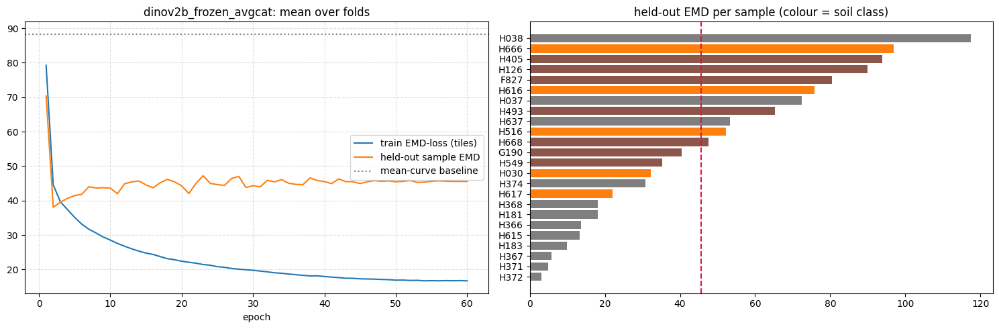

[norm] vit_small_patch16_dinov3.lvd1689m: mean=(0.485, 0.456, 0.406) std=(0.229, 0.224, 0.225)
[tracker] dinov3s_frozen_avgcat_20261031-132821
[norm] vit_small_patch16_dinov3.lvd1689m: mean=(0.485, 0.456, 0.406) std=(0.229, 0.224, 0.225)


features vit_small_patch16_dinov3.lvd1689m @ 224px:   0%|          | 0/43 [00:00<?, ?it/s]

Fold 01/24 | F827 (fine) | 96 val / 2097 train tiles


/usr/local/lib/python3.13/dist-packages/lightning/pytorch/trainer/connectors/data_connector.py:434: The 'train_dataloader' does not have many workers which may be a bottleneck. Consider increasing the value of the `num_workers` argument` to `num_workers=3` in the `DataLoader` to improve performance.
/usr/local/lib/python3.13/dist-packages/lightning/pytorch/trainer/connectors/data_connector.py:434: The 'val_dataloader' does not have many workers which may be a bottleneck. Consider increasing the value of the `num_workers` argument` to `num_workers=3` in the `DataLoader` to improve performance.


    epoch 20/60 | train 23.15 | val 70.36
    epoch 40/60 | train 19.18 | val 70.56
    epoch 60/60 | train 18.32 | val 74.41
Fold 02/24 | G190 (fine) | 96 val / 2097 train tiles


/usr/local/lib/python3.13/dist-packages/lightning/pytorch/trainer/connectors/data_connector.py:434: The 'predict_dataloader' does not have many workers which may be a bottleneck. Consider increasing the value of the `num_workers` argument` to `num_workers=3` in the `DataLoader` to improve performance.
/usr/local/lib/python3.13/dist-packages/lightning/pytorch/trainer/connectors/data_connector.py:434: The 'predict_dataloader' does not have many workers which may be a bottleneck. Consider increasing the value of the `num_workers` argument` to `num_workers=3` in the `DataLoader` to improve performance.
/usr/local/lib/python3.13/dist-packages/lightning/pytorch/trainer/connectors/data_connector.py:434: The 'train_dataloader' does not have many workers which may be a bottleneck. Consider increasing the value of the `num_workers` argument` to `num_workers=3` in the `DataLoader` to improve performance.
/usr/local/lib/python3.13/dist-packages/lightning/pytorch/trainer/connectors/data_connector.p

... (42 outputs left out)

    epoch 20/60 | train 22.07 | val 79.61
    epoch 40/60 | train 18.31 | val 82.17
    epoch 60/60 | train 17.34 | val 82.25
Fold 24/24 | H668 (fine) | 132 val / 2061 train tiles


/usr/local/lib/python3.13/dist-packages/lightning/pytorch/trainer/connectors/data_connector.py:434: The 'predict_dataloader' does not have many workers which may be a bottleneck. Consider increasing the value of the `num_workers` argument` to `num_workers=3` in the `DataLoader` to improve performance.
/usr/local/lib/python3.13/dist-packages/lightning/pytorch/trainer/connectors/data_connector.py:434: The 'predict_dataloader' does not have many workers which may be a bottleneck. Consider increasing the value of the `num_workers` argument` to `num_workers=3` in the `DataLoader` to improve performance.
/usr/local/lib/python3.13/dist-packages/lightning/pytorch/trainer/connectors/data_connector.py:434: The 'train_dataloader' does not have many workers which may be a bottleneck. Consider increasing the value of the `num_workers` argument` to `num_workers=3` in the `DataLoader` to improve performance.
/usr/local/lib/python3.13/dist-packages/lightning/pytorch/trainer/connectors/data_connector.p

    epoch 20/60 | train 23.14 | val 43.61
    epoch 40/60 | train 18.37 | val 43.76
    epoch 60/60 | train 18.00 | val 46.75
[dinov3s_frozen_avgcat] LOSO EMD 42.94 ± 32.00 (median 36.34, mean-curve 88.32) | by class {'fine': 58.14, 'gravel': 30.04, 'sand': 52.62}


/usr/local/lib/python3.13/dist-packages/lightning/pytorch/trainer/connectors/data_connector.py:434: The 'predict_dataloader' does not have many workers which may be a bottleneck. Consider increasing the value of the `num_workers` argument` to `num_workers=3` in the `DataLoader` to improve performance.
/usr/local/lib/python3.13/dist-packages/lightning/pytorch/trainer/connectors/data_connector.py:434: The 'predict_dataloader' does not have many workers which may be a bottleneck. Consider increasing the value of the `num_workers` argument` to `num_workers=3` in the `DataLoader` to improve performance.


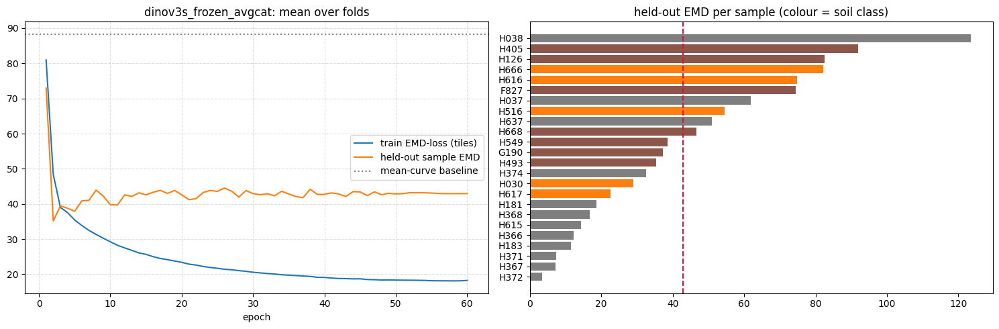

[norm] vit_base_patch16_224.mae: mean=(0.485, 0.456, 0.406) std=(0.229, 0.224, 0.225)
[tracker] maeb_frozen_avgcat_20261031-133114
[norm] vit_base_patch16_224.mae: mean=(0.485, 0.456, 0.406) std=(0.229, 0.224, 0.225)


features vit_base_patch16_224.mae @ 224px:   0%|          | 0/43 [00:00<?, ?it/s]

Fold 01/24 | F827 (fine) | 96 val / 2097 train tiles


/usr/local/lib/python3.13/dist-packages/lightning/pytorch/trainer/connectors/data_connector.py:434: The 'train_dataloader' does not have many workers which may be a bottleneck. Consider increasing the value of the `num_workers` argument` to `num_workers=3` in the `DataLoader` to improve performance.
/usr/local/lib/python3.13/dist-packages/lightning/pytorch/trainer/connectors/data_connector.py:434: The 'val_dataloader' does not have many workers which may be a bottleneck. Consider increasing the value of the `num_workers` argument` to `num_workers=3` in the `DataLoader` to improve performance.


    epoch 20/60 | train 24.69 | val 50.64
    epoch 40/60 | train 21.22 | val 48.90
    epoch 60/60 | train 20.51 | val 51.39
Fold 02/24 | G190 (fine) | 96 val / 2097 train tiles


/usr/local/lib/python3.13/dist-packages/lightning/pytorch/trainer/connectors/data_connector.py:434: The 'predict_dataloader' does not have many workers which may be a bottleneck. Consider increasing the value of the `num_workers` argument` to `num_workers=3` in the `DataLoader` to improve performance.
/usr/local/lib/python3.13/dist-packages/lightning/pytorch/trainer/connectors/data_connector.py:434: The 'predict_dataloader' does not have many workers which may be a bottleneck. Consider increasing the value of the `num_workers` argument` to `num_workers=3` in the `DataLoader` to improve performance.
/usr/local/lib/python3.13/dist-packages/lightning/pytorch/trainer/connectors/data_connector.py:434: The 'train_dataloader' does not have many workers which may be a bottleneck. Consider increasing the value of the `num_workers` argument` to `num_workers=3` in the `DataLoader` to improve performance.
/usr/local/lib/python3.13/dist-packages/lightning/pytorch/trainer/connectors/data_connector.p

... (42 outputs left out)

    epoch 20/60 | train 23.46 | val 58.29
    epoch 40/60 | train 19.93 | val 67.50
    epoch 60/60 | train 19.04 | val 64.22
Fold 24/24 | H668 (fine) | 132 val / 2061 train tiles


/usr/local/lib/python3.13/dist-packages/lightning/pytorch/trainer/connectors/data_connector.py:434: The 'predict_dataloader' does not have many workers which may be a bottleneck. Consider increasing the value of the `num_workers` argument` to `num_workers=3` in the `DataLoader` to improve performance.
/usr/local/lib/python3.13/dist-packages/lightning/pytorch/trainer/connectors/data_connector.py:434: The 'predict_dataloader' does not have many workers which may be a bottleneck. Consider increasing the value of the `num_workers` argument` to `num_workers=3` in the `DataLoader` to improve performance.
/usr/local/lib/python3.13/dist-packages/lightning/pytorch/trainer/connectors/data_connector.py:434: The 'train_dataloader' does not have many workers which may be a bottleneck. Consider increasing the value of the `num_workers` argument` to `num_workers=3` in the `DataLoader` to improve performance.
/usr/local/lib/python3.13/dist-packages/lightning/pytorch/trainer/connectors/data_connector.p

    epoch 20/60 | train 24.30 | val 31.20
    epoch 40/60 | train 20.60 | val 36.46
    epoch 60/60 | train 19.97 | val 39.06
[maeb_frozen_avgcat] LOSO EMD 39.45 ± 30.38 (median 31.40, mean-curve 88.32) | by class {'fine': 47.61, 'gravel': 30.42, 'sand': 49.69}


/usr/local/lib/python3.13/dist-packages/lightning/pytorch/trainer/connectors/data_connector.py:434: The 'predict_dataloader' does not have many workers which may be a bottleneck. Consider increasing the value of the `num_workers` argument` to `num_workers=3` in the `DataLoader` to improve performance.
/usr/local/lib/python3.13/dist-packages/lightning/pytorch/trainer/connectors/data_connector.py:434: The 'predict_dataloader' does not have many workers which may be a bottleneck. Consider increasing the value of the `num_workers` argument` to `num_workers=3` in the `DataLoader` to improve performance.


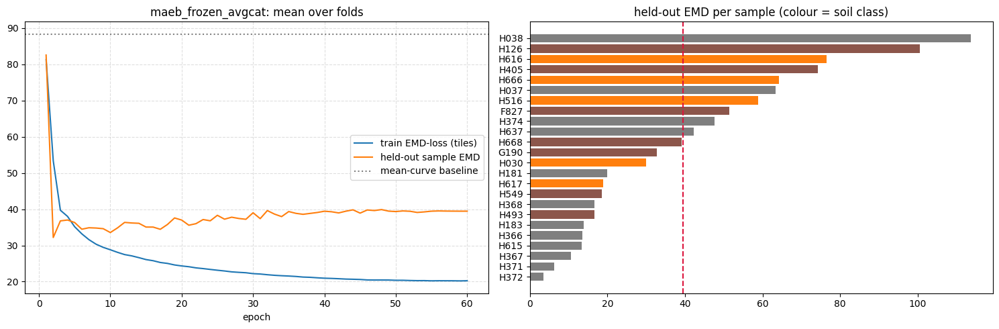

[norm] vit_small_patch16_224.augreg_in21k_ft_in1k: mean=(0.5, 0.5, 0.5) std=(0.5, 0.5, 0.5)
[tracker] vits_sup_frozen_cls_20261031-133428
[norm] vit_small_patch16_224.augreg_in21k_ft_in1k: mean=(0.5, 0.5, 0.5) std=(0.5, 0.5, 0.5)


features vit_small_patch16_224.augreg_in21k_ft_in1k @ 224px:   0%|          | 0/43 [00:00<?, ?it/s]

Fold 01/24 | F827 (fine) | 96 val / 2097 train tiles


/usr/local/lib/python3.13/dist-packages/lightning/pytorch/trainer/connectors/data_connector.py:434: The 'train_dataloader' does not have many workers which may be a bottleneck. Consider increasing the value of the `num_workers` argument` to `num_workers=3` in the `DataLoader` to improve performance.
/usr/local/lib/python3.13/dist-packages/lightning/pytorch/trainer/connectors/data_connector.py:434: The 'val_dataloader' does not have many workers which may be a bottleneck. Consider increasing the value of the `num_workers` argument` to `num_workers=3` in the `DataLoader` to improve performance.


    epoch 20/60 | train 21.93 | val 53.84
    epoch 40/60 | train 18.53 | val 57.08
    epoch 60/60 | train 17.91 | val 57.15
Fold 02/24 | G190 (fine) | 96 val / 2097 train tiles


/usr/local/lib/python3.13/dist-packages/lightning/pytorch/trainer/connectors/data_connector.py:434: The 'predict_dataloader' does not have many workers which may be a bottleneck. Consider increasing the value of the `num_workers` argument` to `num_workers=3` in the `DataLoader` to improve performance.
/usr/local/lib/python3.13/dist-packages/lightning/pytorch/trainer/connectors/data_connector.py:434: The 'predict_dataloader' does not have many workers which may be a bottleneck. Consider increasing the value of the `num_workers` argument` to `num_workers=3` in the `DataLoader` to improve performance.
/usr/local/lib/python3.13/dist-packages/lightning/pytorch/trainer/connectors/data_connector.py:434: The 'train_dataloader' does not have many workers which may be a bottleneck. Consider increasing the value of the `num_workers` argument` to `num_workers=3` in the `DataLoader` to improve performance.
/usr/local/lib/python3.13/dist-packages/lightning/pytorch/trainer/connectors/data_connector.p

... (42 outputs left out)

    epoch 20/60 | train 21.62 | val 56.24
    epoch 40/60 | train 18.71 | val 64.71
    epoch 60/60 | train 17.53 | val 64.59
Fold 24/24 | H668 (fine) | 132 val / 2061 train tiles


/usr/local/lib/python3.13/dist-packages/lightning/pytorch/trainer/connectors/data_connector.py:434: The 'predict_dataloader' does not have many workers which may be a bottleneck. Consider increasing the value of the `num_workers` argument` to `num_workers=3` in the `DataLoader` to improve performance.
/usr/local/lib/python3.13/dist-packages/lightning/pytorch/trainer/connectors/data_connector.py:434: The 'predict_dataloader' does not have many workers which may be a bottleneck. Consider increasing the value of the `num_workers` argument` to `num_workers=3` in the `DataLoader` to improve performance.
/usr/local/lib/python3.13/dist-packages/lightning/pytorch/trainer/connectors/data_connector.py:434: The 'train_dataloader' does not have many workers which may be a bottleneck. Consider increasing the value of the `num_workers` argument` to `num_workers=3` in the `DataLoader` to improve performance.
/usr/local/lib/python3.13/dist-packages/lightning/pytorch/trainer/connectors/data_connector.p

    epoch 20/60 | train 21.77 | val 31.39
    epoch 40/60 | train 18.26 | val 41.33
    epoch 60/60 | train 17.45 | val 41.78
[vits_sup_frozen_cls] LOSO EMD 40.52 ± 31.97 (median 29.54, mean-curve 88.32) | by class {'fine': 51.38, 'gravel': 31.35, 'sand': 47.32}


/usr/local/lib/python3.13/dist-packages/lightning/pytorch/trainer/connectors/data_connector.py:434: The 'predict_dataloader' does not have many workers which may be a bottleneck. Consider increasing the value of the `num_workers` argument` to `num_workers=3` in the `DataLoader` to improve performance.
/usr/local/lib/python3.13/dist-packages/lightning/pytorch/trainer/connectors/data_connector.py:434: The 'predict_dataloader' does not have many workers which may be a bottleneck. Consider increasing the value of the `num_workers` argument` to `num_workers=3` in the `DataLoader` to improve performance.


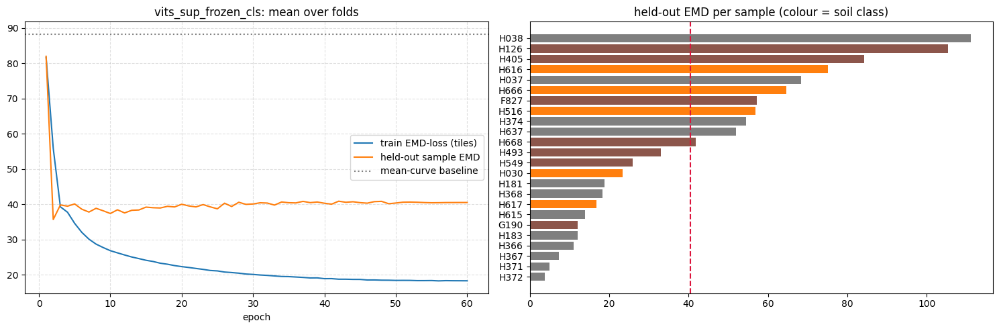

[norm] vit_small_patch14_dinov2.lvd142m: mean=(0.485, 0.456, 0.406) std=(0.229, 0.224, 0.225)
[tracker] dinov2s_frozen_cls_20261031-133709
[norm] vit_small_patch14_dinov2.lvd142m: mean=(0.485, 0.456, 0.406) std=(0.229, 0.224, 0.225)


features vit_small_patch14_dinov2.lvd142m @ 224px:   0%|          | 0/43 [00:00<?, ?it/s]

Fold 01/24 | F827 (fine) | 96 val / 2097 train tiles


/usr/local/lib/python3.13/dist-packages/lightning/pytorch/trainer/connectors/data_connector.py:434: The 'train_dataloader' does not have many workers which may be a bottleneck. Consider increasing the value of the `num_workers` argument` to `num_workers=3` in the `DataLoader` to improve performance.
/usr/local/lib/python3.13/dist-packages/lightning/pytorch/trainer/connectors/data_connector.py:434: The 'val_dataloader' does not have many workers which may be a bottleneck. Consider increasing the value of the `num_workers` argument` to `num_workers=3` in the `DataLoader` to improve performance.


    epoch 20/60 | train 24.76 | val 60.47
    epoch 40/60 | train 21.01 | val 75.14
    epoch 60/60 | train 20.17 | val 75.02
Fold 02/24 | G190 (fine) | 96 val / 2097 train tiles


/usr/local/lib/python3.13/dist-packages/lightning/pytorch/trainer/connectors/data_connector.py:434: The 'predict_dataloader' does not have many workers which may be a bottleneck. Consider increasing the value of the `num_workers` argument` to `num_workers=3` in the `DataLoader` to improve performance.
/usr/local/lib/python3.13/dist-packages/lightning/pytorch/trainer/connectors/data_connector.py:434: The 'predict_dataloader' does not have many workers which may be a bottleneck. Consider increasing the value of the `num_workers` argument` to `num_workers=3` in the `DataLoader` to improve performance.
/usr/local/lib/python3.13/dist-packages/lightning/pytorch/trainer/connectors/data_connector.py:434: The 'train_dataloader' does not have many workers which may be a bottleneck. Consider increasing the value of the `num_workers` argument` to `num_workers=3` in the `DataLoader` to improve performance.
/usr/local/lib/python3.13/dist-packages/lightning/pytorch/trainer/connectors/data_connector.p

... (42 outputs left out)

    epoch 20/60 | train 24.29 | val 46.63
    epoch 40/60 | train 20.24 | val 66.42
    epoch 60/60 | train 19.45 | val 69.27
Fold 24/24 | H668 (fine) | 132 val / 2061 train tiles


/usr/local/lib/python3.13/dist-packages/lightning/pytorch/trainer/connectors/data_connector.py:434: The 'predict_dataloader' does not have many workers which may be a bottleneck. Consider increasing the value of the `num_workers` argument` to `num_workers=3` in the `DataLoader` to improve performance.
/usr/local/lib/python3.13/dist-packages/lightning/pytorch/trainer/connectors/data_connector.py:434: The 'predict_dataloader' does not have many workers which may be a bottleneck. Consider increasing the value of the `num_workers` argument` to `num_workers=3` in the `DataLoader` to improve performance.
/usr/local/lib/python3.13/dist-packages/lightning/pytorch/trainer/connectors/data_connector.py:434: The 'train_dataloader' does not have many workers which may be a bottleneck. Consider increasing the value of the `num_workers` argument` to `num_workers=3` in the `DataLoader` to improve performance.
/usr/local/lib/python3.13/dist-packages/lightning/pytorch/trainer/connectors/data_connector.p

    epoch 20/60 | train 24.63 | val 40.71
    epoch 40/60 | train 20.71 | val 46.57
    epoch 60/60 | train 19.78 | val 46.52
[dinov2s_frozen_cls] LOSO EMD 42.54 ± 31.20 (median 33.56, mean-curve 88.32) | by class {'fine': 57.56, 'gravel': 29.87, 'sand': 51.94}


/usr/local/lib/python3.13/dist-packages/lightning/pytorch/trainer/connectors/data_connector.py:434: The 'predict_dataloader' does not have many workers which may be a bottleneck. Consider increasing the value of the `num_workers` argument` to `num_workers=3` in the `DataLoader` to improve performance.
/usr/local/lib/python3.13/dist-packages/lightning/pytorch/trainer/connectors/data_connector.py:434: The 'predict_dataloader' does not have many workers which may be a bottleneck. Consider increasing the value of the `num_workers` argument` to `num_workers=3` in the `DataLoader` to improve performance.


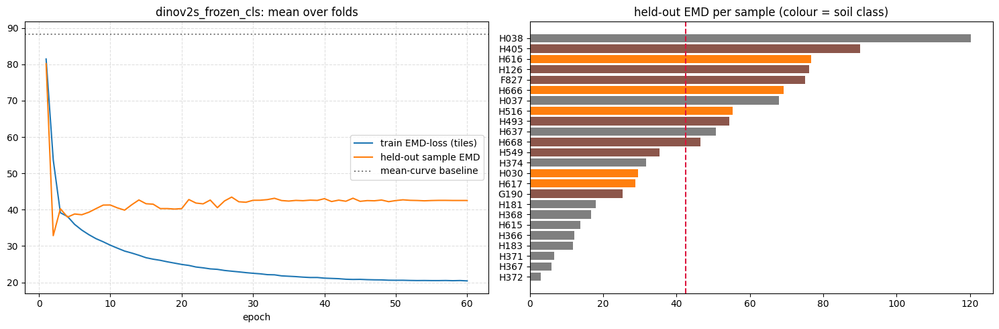

In [21]:
# ===== C3: frozen ViT / SSL backbones through the existing run_loso =====
RUNS = globals().get("RUNS", {})

VIT_FROZEN = [
    # primary: CLS + mean-patch features
    dict(name="vits_sup_frozen_avgcat",  backbone="vit_small_patch16_224.augreg_in21k_ft_in1k", pool="avgcat"),
    dict(name="dinov2s_frozen_avgcat",   backbone="vit_small_patch14_dinov2.lvd142m",           pool="avgcat"),
    dict(name="dinov2b_frozen_avgcat",   backbone="vit_base_patch14_dinov2.lvd142m",            pool="avgcat"),
    dict(name="dinov3s_frozen_avgcat",   backbone="vit_small_patch16_dinov3.lvd1689m",          pool="avgcat"),
    dict(name="maeb_frozen_avgcat",      backbone="vit_base_patch16_224.mae",                   pool="avgcat"),
    # ablation: CLS only (timm default pooling)
    dict(name="vits_sup_frozen_cls",     backbone="vit_small_patch16_224.augreg_in21k_ft_in1k", pool="default"),
    dict(name="dinov2s_frozen_cls",      backbone="vit_small_patch14_dinov2.lvd142m",           pool="default"),
]

for exp in VIT_FROZEN:
    exp = dict(exp)
    POOL[exp["backbone"]] = exp.pop("pool")
    run = run_loso(tile_px=224, **exp)
    report_loso(run)
    make_submission(run.test_pred, f"submission_{exp['name']}.csv", run.tracker)
    RUNS[exp["name"]] = run

**H1 result: not supported.** Frozen DINOv2/DINOv3 (EMD 42.5–45.5) are worse than supervised ViT-S (40.5–40.9); MAE-B is the best ViT (39.45) and ≈ EfficientNet-B0 (39.26), not the worst. CLS vs CLS+mean-patch makes no difference. All models fall within 39.3–45.5 with per-sample std 30–34 (n=24), so differences are within noise. Gravel is identical across models (29–31); the spread is almost entirely in fine and sand. Untested explanation: fines are sub-pixel and only visible via colour/texture; MAE (pixel reconstruction) keeps low-level colour/texture cues that DINO's colour-jitter invariance suppresses. To test: colour-only ridge shortcut control. DINOv2-B < DINOv2-S is probably overfitting of 1536-d features on 23 training samples.

### C4 — LOSO runner for ridge / weighted kNN heads 

In [22]:
# ===== C4: LOSO runner with ridge / weighted-kNN heads on cached features (curve or quantile target) =====
from sklearn.linear_model import Ridge
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import GroupKFold

# alternative target: the quantile function  p -> log10 D_p.  W1 distance between two distributions on the
# log-diameter axis == L1 between their quantile functions == the EMD of the competition, so regressing the
# quantile function (L1/L2) is a direct surrogate of the metric.
PS = np.arange(2.5, 100.0, 2.5)


def curves_to_quantiles(Y):
    return np.array([[np.log10(d_value(c, p)) for p in PS] for c in _2d(Y)])


def quantiles_to_curve(Q):
    out = []
    for q in _2d(Q):
        q = np.maximum.accumulate(np.clip(q, LOG_D[0], LOG_D[-1]))
        c = np.interp(LOG_D, np.concatenate([[LOG_D[0]], q, [LOG_D[-1]]]), np.concatenate([[0.0], PS, [100.0]]))
        c[-1] = 100.0
        out.append(c)
    return np.array(out)


Q_LAB = pd.DataFrame(curves_to_quantiles(LABELS.to_numpy()), index=LABELS.index)


def _ridge_fit(Xtr, Ytr, alpha):
    sc = StandardScaler().fit(Xtr)                       # statistics from the training folds only
    model = Ridge(alpha=alpha).fit(sc.transform(Xtr), Ytr)
    return lambda X: model.predict(sc.transform(X))


def _knn_fit(Xtr, Ytr, k, tau):
    mu = Xtr.mean(0, keepdims=True)
    bank = F.normalize(torch.from_numpy(Xtr - mu).to(CFG.DEVICE), dim=1)
    Y = torch.from_numpy(Ytr).float().to(CFG.DEVICE)

    def predict(X):
        q = F.normalize(torch.from_numpy(X - mu).to(CFG.DEVICE), dim=1)
        sims, ids = (q @ bank.T).topk(min(k, bank.shape[0]), dim=1)
        w = torch.softmax(sims / tau, dim=1)
        return (w.unsqueeze(-1) * Y[ids]).sum(1).cpu().numpy()
    return predict


def _sample_emd(pred_tiles, sids, y_df, target="curve"):
    df = pd.DataFrame(pred_tiles)
    df["sid"] = np.asarray(sids)
    g = df.groupby("sid").mean()
    curves = quantiles_to_curve(g.to_numpy()) if target == "quantile" else enforce_monotone(g.to_numpy())
    return emd_score(y_df.loc[g.index].to_numpy(), curves)


def _select_alpha(X0, Y, sids, alphas, target="curve", n_splits=4):
    """Choose ridge alpha on the training samples only (group-aware inner CV, metric = sample-level EMD)."""
    if len(alphas) == 1:
        return alphas[0]
    scores = {a: [] for a in alphas}
    for tr, va in GroupKFold(n_splits=min(n_splits, len(np.unique(sids)))).split(X0, groups=sids):
        for a in alphas:
            scores[a].append(_sample_emd(_ridge_fit(X0[tr], Y[tr], a)(X0[va]), sids[va], LABELS, target))
    return min(alphas, key=lambda a: float(np.mean(scores[a])))


def _predict_views(predict, Fx):
    n, v, d = Fx.shape
    return predict(Fx.reshape(n * v, d)).reshape(n, v, -1).mean(1)      # TTA over the 4 dihedral views


def _to_curves(pred_mean, target):
    return quantiles_to_curve(pred_mean) if target == "quantile" else enforce_monotone(pred_mean)


def run_loso_sklearn(name, backbone, tile_px=224, head="ridge", alphas=(1, 10, 100, 1e3, 1e4, 1e5), k=20, tau=0.1,
                     target="curve", train_frac=1.0, frac_seed=0, predict_test=True):
    """Ridge / weighted kNN on frozen cached features. target='quantile' regresses log10 D_p instead of the curve.
    train_frac < 1 subsamples the training SAMPLES of every fold (data-efficiency study)."""
    assert head in ("ridge", "knn") and target in ("curve", "quantile")
    params = dict(backbone=backbone, tile_px=tile_px, tile_mm=tile_px / CFG.PX_PER_MM, freeze_backbone=True,
                  optimizer=f"sklearn-{head}", head=head, alphas=list(alphas), k=k, tau=tau, target=target,
                  train_frac=train_frac)
    tracker = ExperimentTracker(name, params)
    feats = extract_features(backbone, tile_px).astype(np.float32)      # (tiles, 4 views, D), aligned with idx rows
    idx = TILE_INDEX[tile_px]
    train_tiles = idx[(idx["split"] == "train") & idx["sample_id"].isin(SIDS)]
    test_tiles = idx[idx["split"] == "test"]
    Fte = feats[test_tiles.index.to_numpy()] if predict_test else None
    Y_all = Q_LAB if target == "quantile" else LABELS[CFG.GRAIN_COLS]

    oof, photo_rows, test_preds, chosen = {}, [], [], []
    for _, f in folds.iterrows():
        held = f["sample_id"]
        tr = train_tiles[train_tiles["sample_id"] != held]
        va = train_tiles[train_tiles["sample_id"] == held]
        if train_frac < 1.0:
            rng = np.random.default_rng(1000 * frac_seed + int(f["fold"]))
            keep = rng.choice(tr["sample_id"].unique(), size=max(2, int(round(train_frac * tr["sample_id"].nunique()))),
                              replace=False)
            tr = tr[tr["sample_id"].isin(keep)]
        Ftr, Fva = feats[tr.index.to_numpy()], feats[va.index.to_numpy()]
        Ytr = Y_all.loc[tr["sample_id"]].to_numpy(np.float64)
        n, v, d = Ftr.shape
        if head == "ridge":
            alpha = _select_alpha(Ftr[:, 0], Ytr, tr["sample_id"].to_numpy(), alphas, target)
            predict = _ridge_fit(Ftr.reshape(n * v, d), np.repeat(Ytr, v, axis=0), alpha)
            chosen.append({"sample_id": held, "alpha": alpha})
        else:
            predict = _knn_fit(Ftr[:, 0], Ytr, k, tau)                  # bank = one view per tile
        pv = _predict_views(predict, Fva)                                # tile-level predictions
        _, curve = aggregate_tiles(pv, va["file"], va["sample_id"], mono=target != "quantile")
        oof[held] = _to_curves(curve, target)[0]
        # photo-level curves (for the per-device analysis)
        pdf = pd.DataFrame(pv)
        pdf["file"] = va["file"].to_numpy()
        pc = pdf.groupby("file").mean()
        dev = va.groupby("file")["device"].first()
        for fl, c in zip(pc.index, _to_curves(pc.to_numpy(), target)):
            photo_rows.append(dict(sample_id=held, file=fl, device=dev[fl], **dict(zip(CFG.GRAIN_COLS, c))))
        if predict_test:
            sids, curves = aggregate_tiles(_predict_views(predict, Fte), test_tiles["file"], test_tiles["sample_id"],
                                           mono=target != "quantile")
            test_preds.append(pd.DataFrame(_to_curves(curves, target), index=sids, columns=CFG.GRAIN_COLS))

    oof_df = pd.DataFrame.from_dict(oof, orient="index", columns=CFG.GRAIN_COLS)
    test_pred = sum(test_preds) / len(test_preds) if test_preds else pd.DataFrame(columns=CFG.GRAIN_COLS)
    tracker.save_table(oof_df, "oof.csv", index_label="sample_id")
    tracker.save_table(pd.DataFrame(photo_rows), "oof_photo.csv", index=False)
    tracker.save_table(test_pred, "test_preds.csv", index_label="sample_id")
    if chosen:
        tracker.save_table(pd.DataFrame(chosen), "chosen_alpha.csv", index=False)
    return SimpleNamespace(tracker=tracker, oof=oof_df, history=pd.DataFrame(), test_pred=test_pred)


print("C4 ok")

C4 ok


### C5 — ridge and kNN on cached feature

In [23]:
def aggregate_tiles(preds, photo_ids, sample_ids, mono=True):
    """tiles -> mean per photo -> mean per sample (first-seen order), valid curves."""
    df = pd.DataFrame(np.asarray(preds))
    df["photo"], df["sid"] = np.asarray(photo_ids), np.asarray(sample_ids)
    per_photo = df.groupby(["sid", "photo"], sort=False).mean()
    per_sample = per_photo.groupby(level="sid", sort=False).mean()
    return per_sample.index.to_numpy(), (enforce_monotone(per_sample.to_numpy()) if mono else per_sample.to_numpy())

In [24]:
# ===== C5: ridge and weighted kNN on the cached features of C3 (and the CNNs) =====
SK_BACKBONES = [
    ("vits_sup", "vit_small_patch16_224.augreg_in21k_ft_in1k", "avgcat"),
    ("dinov2s",  "vit_small_patch14_dinov2.lvd142m",           "avgcat"),
    ("dinov2b",  "vit_base_patch14_dinov2.lvd142m",            "avgcat"),
    ("dinov3s",  "vit_small_patch16_dinov3.lvd1689m",          "avgcat"),
    ("maeb",     "vit_base_patch16_224.mae",                   "avgcat"),
    ("effb0",    "tf_efficientnet_b0.ns_jft_in1k",             "default"),
    ("convnext_t", "convnext_tiny.fb_in22k_ft_in1k",           "default"),
    ("r18",      "resnet18.a1_in1k",                           "default"),
]


def _sk(short, backbone, pool, head, tile_px=224):
    POOL[backbone] = pool
    run = run_loso_sklearn(f"{short}_{head}_t{tile_px}", backbone, tile_px=tile_px, head=head)
    report_loso(run, show=False)
    make_submission(run.test_pred, f"submission_{short}_{head}_t{tile_px}.csv", run.tracker)
    RUNS[f"{short}_{head}_t{tile_px}"] = run


for short, backbone, pool in SK_BACKBONES:
    for head in ("ridge", "knn"):
        safe(f"{short}_{head}", lambda short=short, backbone=backbone, pool=pool, head=head: _sk(short, backbone, pool, head), 0.1)

[start] vits_sup_ridge | elapsed 1.25 h
[tracker] vits_sup_ridge_t224_20261031-133955
[norm] vit_small_patch16_224.augreg_in21k_ft_in1k: mean=(0.5, 0.5, 0.5) std=(0.5, 0.5, 0.5)
[vits_sup_ridge_t224] LOSO EMD 39.87 ± 29.26 (median 30.38, mean-curve 88.32) | by class {'fine': 51.2, 'gravel': 29.22, 'sand': 49.55}
[start] vits_sup_knn | elapsed 1.28 h
[tracker] vits_sup_knn_t224_20261031-134124
[norm] vit_small_patch16_224.augreg_in21k_ft_in1k: mean=(0.5, 0.5, 0.5) std=(0.5, 0.5, 0.5)
[vits_sup_knn_t224] LOSO EMD 40.05 ± 29.70 (median 33.07, mean-curve 88.32) | by class {'fine': 51.62, 'gravel': 30.19, 'sand': 47.5}
[start] dinov2s_ridge | elapsed 1.28 h
[tracker] dinov2s_ridge_t224_20261031-134125
[norm] vit_small_patch14_dinov2.lvd142m: mean=(0.485, 0.456, 0.406) std=(0.229, 0.224, 0.225)
[dinov2s_ridge_t224] LOSO EMD 42.15 ± 30.16 (median 40.48, mean-curve 88.32) | by class {'fine': 57.02, 'gravel': 30.23, 'sand': 49.94}
[start] dinov2s_knn | elapsed 1.30 h
[tracker] dinov2s_knn_t224_

**H2 result: partly not supported.** Ridge / weighted kNN are within ±3 EMD of the MLP-EMD head for 6 of 7 backbones (exception: DINOv2-B, kNN 41.4 vs MLP 45.5). kNN is *not* worse on fine/sand: for the DINO backbones it is better on fine (51–54 vs 57–62 for ridge). Best single run: MAE-B + ridge, 37.81 ± 27.05, but all 14 runs lie in 37.8–44.0 (per-sample std 27–31, n=24) and under kNN the spread between backbones is only 39.1–41.4, so backbone and head choice are below the noise. Selecting the best of ~27 configurations by CV on 24 samples is optimistic (winner's curse). Likely reason for kNN's robustness: it predicts a convex combination of training curves, a strong shrinkage prior when only 23 samples are available.

### C6 — export snapshot

In [25]:
# ===== C6: export snapshot (run after every block, then download from the Output panel) =====
import zipfile

def export_snapshot(include_features=True):
    ts = datetime.now().strftime("%m%d-%H%M")
    out = CFG.OUTPUT_DIR
    keep = {"oof.csv", "test_preds.csv", "per_sample.csv", "history.csv", "summary.json",
            "config.json", "chosen_alpha.csv", "oof_photo.csv", "loso_results.png"}
    small = out / "results_snapshot.zip"
    with zipfile.ZipFile(small, "w", zipfile.ZIP_DEFLATED) as z:
        for fp in [CFG.EXP_DIR / "registry.csv", *sorted(out.glob("*.csv")), *sorted(out.glob("*.png"))]:
            if fp.exists():
                z.write(fp, fp.relative_to(out))
    print(f"{small.name}: {small.stat().st_size / 1e6:.1f} MB")
    if include_features:
        big = out / "features_all.zip"
        with zipfile.ZipFile(big, "w", zipfile.ZIP_STORED) as z:       # .npy barely compress
            for fp in sorted(CFG.FEAT_DIR.glob("*.npy")):
                z.write(fp, fp.relative_to(out))
        print(f"{big.name}: {big.stat().st_size / 1e6:.1f} MB")

export_snapshot()

results_snapshot.zip: 0.2 MB
features_all.zip: 216.2 MB


### C7 — smoke test: fine-tune ViT-S on one fold (LLRD, no-wd groups, drop-path)

In [26]:
# ===== ViT fine-tuning recipe (DeiT / AugReg): drop-path 0.1, layer-wise lr decay 0.75, CLS pooling =====
MODEL_KWARGS[VITS] = dict(img_size=224, drop_path_rate=0.1)     # stochastic depth only matters in train mode
LLRD[VITS] = 0.75
POOL[VITS] = "default"                                           # CLS (frozen CLS vs avgcat made no difference)


def _optimiser_group_check():
    net = ImageNet(VITS)
    groups = net.lr_groups(1e-3, 1e-4)
    print("lr groups:", [f"{lr:.1e}" for _, lr in groups])
    pg = param_groups(groups, 0.05)
    no_decay = {id(p) for g in pg if g["weight_decay"] == 0 for p in g["params"]}
    named = dict(net.backbone.named_parameters())
    print("pos_embed no-wd:", id(named["pos_embed"]) in no_decay, "| cls_token no-wd:", id(named["cls_token"]) in no_decay,
          "| params with wd:", sum(p.numel() for g in pg if g["weight_decay"] > 0 for p in g["params"]) / 1e6, "M")


safe("optimiser group check", _optimiser_group_check)

[start] optimiser group check | elapsed 1.50 h
lr groups: ['1.0e-03', '2.4e-06', '3.2e-06', '4.2e-06', '5.6e-06', '7.5e-06', '1.0e-05', '1.3e-05', '1.8e-05', '2.4e-05', '3.2e-05', '4.2e-05', '5.6e-05', '7.5e-05', '1.0e-04']
pos_embed no-wd: True | cls_token no-wd: True | params with wd: 21.629696 M


### C8 — fine-tune ViT-S (supervised) and DINOv2-S, LLRD, 24 folds

[start] vits_sup_ft_llrd_t224 | elapsed 1.50 h
[norm] vit_small_patch16_224.augreg_in21k_ft_in1k: mean=(0.5, 0.5, 0.5) std=(0.5, 0.5, 0.5)
[tracker] vits_sup_ft_llrd_t224_20261031-135443
Fold 01/24 | F827 (fine) | 96 val / 2097 train tiles
    epoch 08/8 | train 23.93 | val 54.14
Fold 02/24 | G190 (fine) | 96 val / 2097 train tiles
    epoch 08/8 | train 24.29 | val 6.20
Fold 03/24 | H030 (sand) | 120 val / 2073 train tiles
    epoch 08/8 | train 24.93 | val 24.11
Fold 04/24 | H037 (gravel) | 108 val / 2085 train tiles
    epoch 08/8 | train 24.31 | val 65.06
Fold 05/24 | H038 (gravel) | 156 val / 2037 train tiles
    epoch 08/8 | train 21.64 | val 122.58
Fold 06/24 | H126 (fine) | 60 val / 2133 train tiles
    epoch 08/8 | train 22.63 | val 99.96
Fold 07/24 | H181 (gravel) | 96 val / 2097 train tiles
    epoch 08/8 | train 25.00 | val 19.93
Fold 08/24 | H183 (gravel) | 120 val / 2073 train tiles
    epoch 08/8 | train 26.15 | val 14.42
Fold 09/24 | H366 (gravel) | 48 val / 2145 train 

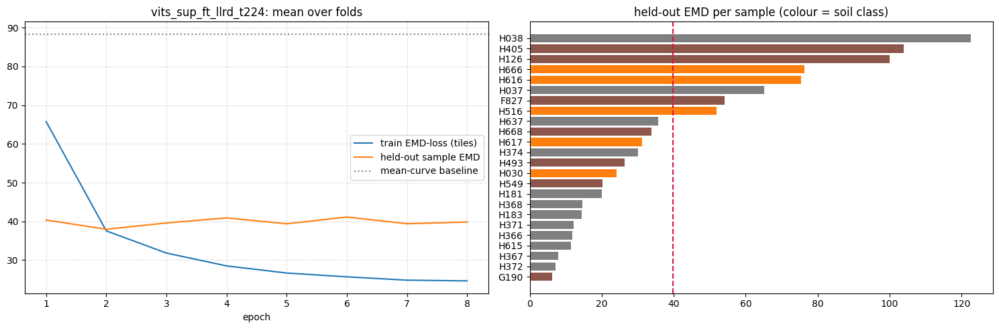

[start] dinov2s_ft_llrd_t224 | elapsed 1.93 h
[norm] vit_small_patch14_dinov2.lvd142m: mean=(0.485, 0.456, 0.406) std=(0.229, 0.224, 0.225)
[tracker] dinov2s_ft_llrd_t224_20261031-142044
Fold 01/24 | F827 (fine) | 96 val / 2097 train tiles
    epoch 08/8 | train 32.37 | val 58.02
Fold 02/24 | G190 (fine) | 96 val / 2097 train tiles
    epoch 08/8 | train 30.19 | val 16.77
Fold 03/24 | H030 (sand) | 120 val / 2073 train tiles
    epoch 08/8 | train 33.66 | val 21.87
Fold 04/24 | H037 (gravel) | 108 val / 2085 train tiles
    epoch 08/8 | train 31.32 | val 87.26
Fold 05/24 | H038 (gravel) | 156 val / 2037 train tiles
    epoch 08/8 | train 26.91 | val 142.06
Fold 06/24 | H126 (fine) | 60 val / 2133 train tiles
    epoch 08/8 | train 27.28 | val 102.69
Fold 07/24 | H181 (gravel) | 96 val / 2097 train tiles
    epoch 08/8 | train 32.19 | val 19.76
Fold 08/24 | H183 (gravel) | 120 val / 2073 train tiles
    epoch 08/8 | train 31.59 | val 15.76
Fold 09/24 | H366 (gravel) | 48 val / 2145 trai

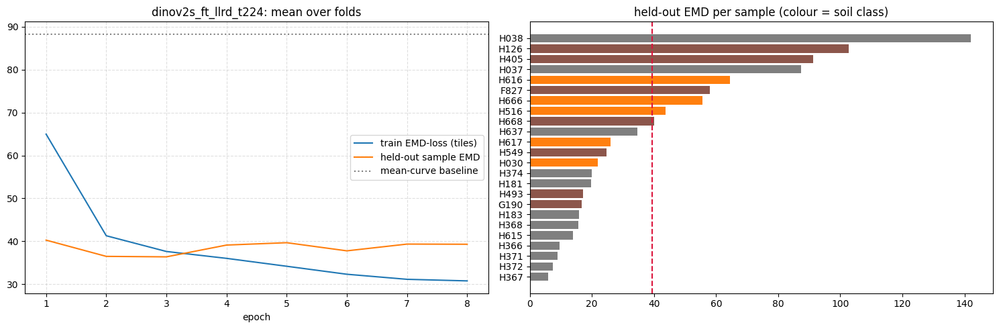

results_snapshot.zip: 0.2 MB


In [27]:
# ===== C8: full LOSO fine-tuning of two ViT-S encoders (supervised vs DINOv2), same recipe =====
MODEL_KWARGS[DINO_S] = dict(img_size=224, drop_path_rate=0.1)
LLRD[DINO_S] = 0.75
POOL[DINO_S] = "default"

VIT_FT = [
    dict(name="vits_sup_ft_llrd_t224", backbone=VITS),
    dict(name="dinov2s_ft_llrd_t224",  backbone=DINO_S),
]


def _vit_ft(exp):
    # ViT recipe: weight decay 0.05 (DeiT / AugReg); the ConvNeXt fine-tuning above used 1e-4
    run = run_loso(tile_px=224, freeze_backbone=False, epochs=8, lr=1e-3, backbone_lr=1e-4, weight_decay=0.05,
                   keep_weights=VIS_SIDS, **exp)
    report_loso(run)
    make_submission(run.test_pred, f"submission_{exp['name']}.csv", run.tracker)
    RUNS[exp["name"]] = run


for exp in VIT_FT:
    safe(exp["name"], lambda exp=exp: _vit_ft(exp), 0.7)

export_snapshot(include_features=False)

### C9: baseline submissions (uniform and mean training curve)


In [28]:
test_ids = sub_df["sample_id"]
uniform = pd.DataFrame(np.tile(UNIFORM_CURVE, (len(test_ids), 1)), index=test_ids, columns=CFG.GRAIN_COLS)
mean_curve = pd.DataFrame(np.tile(LABELS.loc[SIDS].mean().to_numpy(), (len(test_ids), 1)),
                          index=test_ids, columns=CFG.GRAIN_COLS)
make_submission(uniform, "submission_baseline_uniform.csv")
make_submission(mean_curve, "submission_baseline_meancurve.csv")
print("written: submission_baseline_uniform.csv, submission_baseline_meancurve.csv")

written: submission_baseline_uniform.csv, submission_baseline_meancurve.csv


### C10 — per-sample comparison, paired differences, hardest samples

In [29]:
# ===== C10: per-sample EMD across runs, paired comparison vs a reference, hardest samples =====
reg = registry_table().reset_index()
reg = reg[reg["cfg.tile_mm"].notna() & (reg["n_folds"] == N_FOLDS) & ~reg["name"].str.startswith(AUX_PREFIX)]
E = pd.DataFrame({r["name"]: read_sample_table(Path(r["run_dir"]) / "per_sample.csv")["emd"]
                  for _, r in reg.iterrows()})                    # samples x runs
print(f"{E.shape[1]} runs x {E.shape[0]} samples")

hard = pd.DataFrame({"soil": SOIL.loc[E.index], "mean_emd": E.mean(1), "min": E.min(1), "max": E.max(1)}
                    ).sort_values("mean_emd", ascending=False)
display(hard.head(8).round(1))
print("share of total EMD from the 5 hardest samples: "
      f"{hard['mean_emd'].head(5).sum() / hard['mean_emd'].sum():.0%}")

ref = "effb0_frozen_t224"
assert ref in E.columns, E.columns.tolist()
rng = np.random.default_rng(0)
rows = []
for n in E.columns:
    d = (E[n] - E[ref]).to_numpy()
    boots = rng.choice(d, (5000, len(d))).mean(1)
    lo, hi = np.percentile(boots, [2.5, 97.5])
    rows.append(dict(run=n, cv=E[n].mean(), diff_vs_ref=d.mean(), ci_lo=lo, ci_hi=hi,
                     wins=int((d < 0).sum()), significant=bool(lo > 0 or hi < 0)))
cmp = pd.DataFrame(rows).sort_values("cv").reset_index(drop=True)
display(cmp.round(2))

32 runs x 24 samples


,soil,mean_emd,min,max
sample_id,,,,
H038,gravel,118.3,101.0,142.1
H126,fine,82.9,44.4,116.7
H405,fine,82.5,43.3,103.9
H616,sand,74.1,64.5,80.3
F827,fine,68.3,51.4,85.5
H037,gravel,68.0,56.3,87.3
H666,sand,63.8,47.8,96.9
H516,sand,54.6,43.6,75.1


share of total EMD from the 5 hardest samples: 44%


,run,cv,diff_vs_ref,ci_lo,ci_hi,wins,significant
0,r18_frozen_t224,36.57,-2.69,-5.90,0.16,13,False
1,maeb_ridge_t224,37.81,-1.44,-4.51,1.49,13,False
2,r18_knn_t224,38.16,-1.10,-6.58,3.69,10,False
3,r18_ridge_t224,39.00,-0.25,-3.16,2.21,11,False
4,effb0_knn_t224,39.08,-0.17,-4.92,3.97,9,False
5,effb0_frozen_t224,39.26,0.00,0.00,0.00,0,False
6,convnext_t_ridge_t224,39.26,0.01,-2.58,2.50,10,False
7,dinov2s_ft_llrd_t224,39.29,0.04,-4.11,4.74,15,False
8,convnext_t_frozen_t224_sgd,39.43,0.17,-2.51,2.85,13,False
9,maeb_frozen_avgcat,39.45,0.19,-2.85,3.31,10,False


### C11: domain shift train vs test (pixel stats + feature-space distance)

In [30]:
# C11: domain shift train vs test (pixel stats + feature-space distance)
import numpy as np, pandas as pd
from PIL import Image

idx = TILE_INDEX[224].copy()
idx["is_test"] = idx["split"] == "test"

# --- A. pixel statistics: sharpness (Laplacian var), HF energy, colour, contrast ---
def tile_stats(path):
    a = np.asarray(Image.open(path).convert("RGB"), dtype=np.float32)
    g = a.mean(-1)
    lap = (-4 * g[1:-1, 1:-1] + g[:-2, 1:-1] + g[2:, 1:-1] + g[1:-1, :-2] + g[1:-1, 2:])
    dx, dy = np.diff(g, axis=1), np.diff(g, axis=0)
    return dict(lap_var=lap.var(), grad=np.abs(dx).mean() + np.abs(dy).mean(),
                R=a[..., 0].mean(), G=a[..., 1].mean(), B=a[..., 2].mean(), contrast=g.std())

rng = np.random.RandomState(0)
sub = pd.concat([g.sample(min(120, len(g)), random_state=0) for _, g in idx.groupby(["split", "device"])])
st = pd.DataFrame([tile_stats(p) for p in sub["path"]], index=sub.index)
st = pd.concat([sub[["split", "device", "factor"]], st], axis=1)
print(st.groupby(["split", "device"]).agg(n=("lap_var", "size"), factor=("factor", "first"),
      lap_var=("lap_var", "median"), grad=("grad", "median"), contrast=("contrast", "median"),
      R=("R", "mean"), G=("G", "mean"), B=("B", "mean")).round(2))

# --- B. feature-space distance (DINOv2-S, mean over 4 views, L2-normalised) ---
with pooled("vit_small_patch14_dinov2.lvd142m", "avgcat"):
    feats = extract_features("vit_small_patch14_dinov2.lvd142m", 224).astype(np.float32).mean(1)
feats /= np.linalg.norm(feats, axis=1, keepdims=True)
tr_mask = ((idx["split"] == "train") & idx["sample_id"].isin(SIDS)).to_numpy()
te_mask = idx["is_test"].to_numpy()
sid = idx["sample_id"].to_numpy()

def nn_dist(q, ref):   # cosine distance to nearest reference tile
    return 1 - (q @ ref.T).max(1)

rows = []
for s in SIDS:                                   # LOSO: held-out train sample vs the other 23
    q = feats[tr_mask & (sid == s)]
    rows.append(("train", s, nn_dist(q, feats[tr_mask & (sid != s)]).mean()))
for s in sorted(set(sid[te_mask])):              # test sample vs all 24 train samples
    rows.append(("test", s, nn_dist(feats[te_mask & (sid == s)], feats[tr_mask]).mean()))
D = pd.DataFrame(rows, columns=["split", "sample_id", "nn_dist"])
print(D.groupby("split")["nn_dist"].describe().round(4))
print(D[D.split == "test"].sort_values("nn_dist").round(4).to_string(index=False))
print("train-LOSO nn_dist: median %.4f  max %.4f" % (D[D.split == "train"].nn_dist.median(), D[D.split == "train"].nn_dist.max()))

# --- C. which test samples are most 'out of distribution' vs. the LOSO range ---
thr = D[D.split == "train"].nn_dist.quantile(0.9)
print("test samples beyond the train-LOSO 90th percentile:", (D[D.split == "test"].nn_dist > thr).sum(), "of", (D.split == "test").sum())

                                 n  factor      lap_var       grad   contrast  \
split device                                                                    
test  iPhone 14                120    0.29  3481.790039  35.279999  47.480000   
      iPhone 16                120    0.20  4170.120117  38.060001  28.070000   
train Motorola Edge            120    0.87  7219.080078  48.950001  49.279999   
      Motorola Edge 60 Fusion   45    0.32  4449.910156  38.349998  44.619999   
      Samsung A52              120    0.88  2174.489990  29.580000  39.439999   

                                        R           G           B  
split device                                                       
test  iPhone 14                149.220001  148.240005  142.130005  
      iPhone 16                154.220001  151.960007  146.259995  
train Motorola Edge            137.740005  129.929993  122.750000  
      Motorola Edge 60 Fusion  147.300003  149.479996  109.169998  
      Samsung A52       

### H5 — колір/контраст: вирівнювання per-photo зменшує domain shift
Гіпотеза: різниця test vs train в основному колірна (white balance, контраст), а не в різкості. Gray-world або Reinhard (mean/std кожного каналу фото → глобальні статистики train) зменшує NN-відстань test→train, а CV не гіршає більше ніж на шум (~2 пункти). Спростування: відстань не змінюється, або CV помітно падає (колір ґрунту несе сигнал).

### C12: H5 — per-photo colour normalisation (gray-world / Reinhard) vs domain shift


In [31]:
# C12: H5 — per-photo colour normalisation (gray-world / Reinhard) vs domain shift
import numpy as np, pandas as pd
from pathlib import Path
from PIL import Image

BASE_IDX = TILE_INDEX[224].copy()
NORM_ROOT = CFG.OUTPUT_DIR / "tiles_norm"

def _load(p):
    return np.asarray(Image.open(p).convert("RGB"), dtype=np.float32)

# 1) per-photo channel stats; targets = mean of per-photo stats over TRAIN photos
file_stats = {}
for (sp, f), g in BASE_IDX.groupby(["split", "file"]):
    px = np.concatenate([_load(p).reshape(-1, 3) for p in g["path"]])
    file_stats[(sp, f)] = (px.mean(0), px.std(0))
tr_stats = [v for (sp, _), v in file_stats.items() if sp == "train"]
MU_T = np.mean([m for m, _ in tr_stats], 0); SD_T = np.mean([s for _, s in tr_stats], 0)
print("train target mean", MU_T.round(1), "std", SD_T.round(1))

def normalise(a, mu, sd, mode):
    if mode == "gw":                      # remove colour cast, keep photo luminance
        out = a * (mu.mean() / mu)
    else:                                  # reinhard: match per-channel mean/std to train
        out = (a - mu) / (sd + 1e-6) * SD_T + MU_T
    return np.clip(out, 0, 255).astype(np.uint8)

def build_variant(mode):
    root = NORM_ROOT / mode
    new = BASE_IDX.copy()
    paths = []
    for (sp, f), g in BASE_IDX.groupby(["split", "file"]):
        mu, sd = file_stats[(sp, f)]
        for i, p in g["path"].items():
            q = root / Path(p).relative_to(tile_dir(224))
            if not q.exists():
                q.parent.mkdir(parents=True, exist_ok=True)
                Image.fromarray(normalise(_load(p), mu, sd, mode)).save(q)
            paths.append((i, str(q)))
    new.loc[[i for i, _ in paths], "path"] = [q for _, q in paths]
    return new

def nn_report(tag, backbone):
    feats = extract_features(backbone, 224).astype(np.float32).mean(1)
    feats /= np.linalg.norm(feats, axis=1, keepdims=True)
    idx = TILE_INDEX[224]
    trm = ((idx["split"] == "train") & idx["sample_id"].isin(SIDS)).to_numpy()
    tem = (idx["split"] == "test").to_numpy()
    sid = idx["sample_id"].to_numpy()
    d = lambda q, r: 1 - (q @ r.T).max(1)
    tr = [d(feats[trm & (sid == s)], feats[trm & (sid != s)]).mean() for s in SIDS]
    te = [d(feats[tem & (sid == s)], feats[trm]).mean() for s in sorted(set(sid[tem]))]
    print(f"[{tag}] nn_dist train-LOSO median {np.median(tr):.4f} | test median {np.median(te):.4f} | ratio {np.median(te)/np.median(tr):.2f}")

SHIFT_BACKBONES = {"dinov2s": "vit_small_patch14_dinov2.lvd142m",
                   "vits_sup": "vit_small_patch16_224.augreg_in21k_ft_in1k"}
def _colour_norm_block():
    for mode in ("orig", "gw", "reinhard"):
        with variant_tiles(BASE_IDX if mode == "orig" else build_variant(mode), "" if mode == "orig" else f"norm_{mode}"):
            for short, bb in SHIFT_BACKBONES.items():
                with pooled(bb, "avgcat"):                 # той самий pooling, що у dinov2s/vits_sup ridge
                    if short == "dinov2s":
                        nn_report(f"{mode}/{short}", bb)
                    if mode != "orig":                     # orig ridge вже є
                        run = run_loso_sklearn(f"{short}_ridge_{mode}_t224", bb, tile_px=224, head="ridge")
                        report_loso(run, show=False)
                        RUNS[f"{short}_ridge_{mode}_t224"] = run

safe("colour normalisation (H5)", _colour_norm_block, 0.15)

train target mean [147.6 138.9 125.7] std [45.7 44.4 42.5]
[start] colour normalisation (H5) | elapsed 2.52 h
[norm] vit_small_patch14_dinov2.lvd142m: mean=(0.485, 0.456, 0.406) std=(0.229, 0.224, 0.225)
[orig/dinov2s] nn_dist train-LOSO median 0.0408 | test median 0.1337 | ratio 3.28
[norm] vit_small_patch14_dinov2.lvd142m: mean=(0.485, 0.456, 0.406) std=(0.229, 0.224, 0.225)


features vit_small_patch14_dinov2.lvd142m @ 224px:   0%|          | 0/43 [00:00<?, ?it/s]

[gw/dinov2s] nn_dist train-LOSO median 0.0461 | test median 0.1343 | ratio 2.91
[tracker] dinov2s_ridge_gw_t224_20261031-145646
[norm] vit_small_patch14_dinov2.lvd142m: mean=(0.485, 0.456, 0.406) std=(0.229, 0.224, 0.225)
[dinov2s_ridge_gw_t224] LOSO EMD 41.71 ± 31.02 (median 32.82, mean-curve 88.32) | by class {'fine': 56.33, 'gravel': 29.96, 'sand': 49.48}
[tracker] vits_sup_ridge_gw_t224_20261031-145833
[norm] vit_small_patch16_224.augreg_in21k_ft_in1k: mean=(0.5, 0.5, 0.5) std=(0.5, 0.5, 0.5)


features vit_small_patch16_224.augreg_in21k_ft_in1k @ 224px:   0%|          | 0/43 [00:00<?, ?it/s]

[vits_sup_ridge_gw_t224] LOSO EMD 41.83 ± 30.47 (median 32.87, mean-curve 88.32) | by class {'fine': 55.01, 'gravel': 31.65, 'sand': 47.81}
[norm] vit_small_patch14_dinov2.lvd142m: mean=(0.485, 0.456, 0.406) std=(0.229, 0.224, 0.225)


features vit_small_patch14_dinov2.lvd142m @ 224px:   0%|          | 0/43 [00:00<?, ?it/s]

[reinhard/dinov2s] nn_dist train-LOSO median 0.0427 | test median 0.1402 | ratio 3.28
[tracker] dinov2s_ridge_reinhard_t224_20261031-150138
[norm] vit_small_patch14_dinov2.lvd142m: mean=(0.485, 0.456, 0.406) std=(0.229, 0.224, 0.225)
[dinov2s_ridge_reinhard_t224] LOSO EMD 41.41 ± 31.14 (median 36.52, mean-curve 88.32) | by class {'fine': 54.86, 'gravel': 31.41, 'sand': 46.6}
[tracker] vits_sup_ridge_reinhard_t224_20261031-150309
[norm] vit_small_patch16_224.augreg_in21k_ft_in1k: mean=(0.5, 0.5, 0.5) std=(0.5, 0.5, 0.5)


features vit_small_patch16_224.augreg_in21k_ft_in1k @ 224px:   0%|          | 0/43 [00:00<?, ?it/s]

[vits_sup_ridge_reinhard_t224] LOSO EMD 42.58 ± 30.25 (median 32.64, mean-curve 88.32) | by class {'fine': 54.85, 'gravel': 32.73, 'sand': 49.06}


### H4 — ViT-S з нуля
Гіпотеза: на ~2 тис. тайлів із 23 семплів ViT-S з випадковою ініціалізацією (10 епох) не вивчить нічого понад середню криву. CV буде близьким до mean-curve baseline (88.3) і значно гіршим за будь-який pretrained (37–45). Спростування: CV < 60.

### ===== C13: ViT-S/16 from scratch (random init), same tiles/folds/head as C8 =====


[start] vits_scratch_t224 | elapsed 2.68 h
[norm] vit_small_patch16_224: mean=(0.5, 0.5, 0.5) std=(0.5, 0.5, 0.5)
[tracker] vits_scratch_t224_20261031-150531
Fold 01/24 | F827 (fine) | 96 val / 2097 train tiles
    epoch 10/10 | train 33.03 | val 54.74
Fold 02/24 | G190 (fine) | 96 val / 2097 train tiles
    epoch 10/10 | train 41.08 | val 14.87
Fold 03/24 | H030 (sand) | 120 val / 2073 train tiles
    epoch 10/10 | train 39.23 | val 22.54
Fold 04/24 | H037 (gravel) | 108 val / 2085 train tiles
    epoch 10/10 | train 31.12 | val 93.47
Fold 05/24 | H038 (gravel) | 156 val / 2037 train tiles
    epoch 10/10 | train 27.05 | val 138.53
Fold 06/24 | H126 (fine) | 60 val / 2133 train tiles
    epoch 10/10 | train 45.02 | val 57.74
Fold 07/24 | H181 (gravel) | 96 val / 2097 train tiles
    epoch 10/10 | train 44.21 | val 19.04
Fold 08/24 | H183 (gravel) | 120 val / 2073 train tiles
    epoch 10/10 | train 39.87 | val 16.99
Fold 09/24 | H366 (gravel) | 48 val / 2145 train tiles
    epoch 10/1

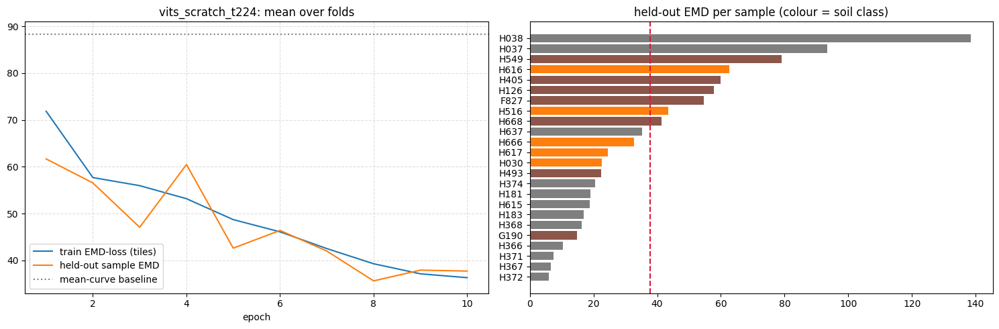

results_snapshot.zip: 0.2 MB


In [32]:
# ===== C13: ViT-S/16 from scratch (timm, random init), same tiles/folds/head as C8 =====
VIT_SCRATCH = "vit_small_patch16_224"            # no pretrained tag -> build_backbone uses pretrained=False
SCRATCH = set(SCRATCH) | {VIT_SCRATCH}
MODEL_KWARGS[VIT_SCRATCH] = dict(drop_path_rate=0.1)
POOL[VIT_SCRATCH] = "default"
# LLRD intentionally not set: from scratch every layer needs the same lr


def _timm_scratch():
    run = run_loso(name="vits_scratch_t224", backbone=VIT_SCRATCH, tile_px=224, freeze_backbone=False, epochs=10,
                   lr=1e-3, backbone_lr=5e-4, weight_decay=0.05, keep_weights=False)
    report_loso(run)
    make_submission(run.test_pred, "submission_vits_scratch_t224.csv", run.tracker)
    RUNS["vits_scratch_t224"] = run


safe("vits_scratch_t224", _timm_scratch, 0.8)
export_snapshot(include_features=False)

[start] OwnViT sanity check | elapsed 3.21 h
OwnViT == timm ViT-S/16 with the same weights: True | params (M): 21.67
[start] own_vit_s_scratch_t224 | elapsed 3.21 h
[norm] own_vit_s16: mean=(0.5, 0.5, 0.5) std=(0.5, 0.5, 0.5)
[tracker] own_vit_s_scratch_t224_20261031-153708
Fold 01/24 | F827 (fine) | 96 val / 2097 train tiles
    epoch 10/10 | train 40.41 | val 62.14
Fold 02/24 | G190 (fine) | 96 val / 2097 train tiles
    epoch 10/10 | train 37.13 | val 19.24
Fold 03/24 | H030 (sand) | 120 val / 2073 train tiles
    epoch 10/10 | train 31.87 | val 26.46
Fold 04/24 | H037 (gravel) | 108 val / 2085 train tiles
    epoch 10/10 | train 34.05 | val 80.55
Fold 05/24 | H038 (gravel) | 156 val / 2037 train tiles
    epoch 10/10 | train 31.88 | val 135.29
Fold 06/24 | H126 (fine) | 60 val / 2133 train tiles
    epoch 10/10 | train 35.14 | val 65.79
Fold 07/24 | H181 (gravel) | 96 val / 2097 train tiles
    epoch 10/10 | train 35.49 | val 19.43
Fold 08/24 | H183 (gravel) | 120 val / 2073 train 

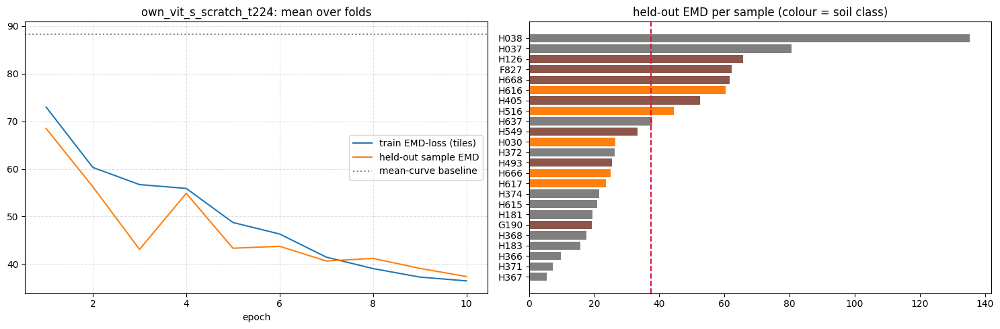

results_snapshot.zip: 0.2 MB


In [33]:
# ===== Part 2: own ViT-S/16 (Lecture-1 style) from scratch =====
def _own_vit_sanity():
    """OwnViT must reproduce timm's ViT-S exactly when it receives timm's weights."""
    t = timm.create_model("vit_small_patch16_224", pretrained=False, num_classes=0).eval()
    o = OwnViT(drop_path=0.0).eval()
    o.load_state_dict(t.state_dict())
    x = torch.randn(2, 3, 224, 224)
    with torch.no_grad():
        ok = torch.allclose(t(x), o(x), atol=1e-4)
    print("OwnViT == timm ViT-S/16 with the same weights:", ok, "| params (M):", round(sum(p.numel() for p in o.parameters()) / 1e6, 2))
    assert ok


safe("OwnViT sanity check", _own_vit_sanity)


def _own_scratch():
    run = run_loso(name="own_vit_s_scratch_t224", backbone="own_vit_s16", tile_px=224, freeze_backbone=False, epochs=10,
                   lr=1e-3, backbone_lr=5e-4, weight_decay=0.05, keep_weights=False)
    report_loso(run)
    make_submission(run.test_pred, "submission_own_vit_s_scratch_t224.csv", run.tracker)
    RUNS["own_vit_s_scratch_t224"] = run


safe("own_vit_s_scratch_t224", _own_scratch, 0.8)
export_snapshot(include_features=False)

In [34]:
# ===== Part 2: other pretrained architectures (DeiT -> Swin / MaxViT): frozen features + ridge / kNN =====
for short, bb in (("deit_s", DEIT_S), ("swin_t", SWIN_T), ("maxvit_t", MAXVIT_T)):
    for head in ("ridge", "knn"):
        safe(f"{short}_{head}", lambda short=short, bb=bb, head=head: _sk(short, bb, "default", head), 0.1)

[start] deit_s_ridge | elapsed 3.74 h
[tracker] deit_s_ridge_t224_20261031-160916
[norm] deit_small_patch16_224.fb_in1k: mean=(0.485, 0.456, 0.406) std=(0.229, 0.224, 0.225)


model.safetensors: reconstructing file:   0%|          |  0.00B / 88.2MB            

model.safetensors: downloading bytes:           |  0.00B            

features deit_small_patch16_224.fb_in1k @ 224px:   0%|          | 0/43 [00:00<?, ?it/s]

[deit_s_ridge_t224] LOSO EMD 38.61 ± 28.26 (median 30.84, mean-curve 88.32) | by class {'fine': 51.99, 'gravel': 27.16, 'sand': 47.35}
[start] deit_s_knn | elapsed 3.76 h
[tracker] deit_s_knn_t224_20261031-161023
[norm] deit_small_patch16_224.fb_in1k: mean=(0.485, 0.456, 0.406) std=(0.229, 0.224, 0.225)
[deit_s_knn_t224] LOSO EMD 40.02 ± 30.27 (median 32.52, mean-curve 88.32) | by class {'fine': 50.4, 'gravel': 30.04, 'sand': 49.46}
[start] swin_t_ridge | elapsed 3.77 h
[tracker] swin_t_ridge_t224_20261031-161044
[norm] swin_tiny_patch4_window7_224.ms_in22k_ft_in1k: mean=(0.485, 0.456, 0.406) std=(0.229, 0.224, 0.225)


model.safetensors: reconstructing file:   0%|          |  0.00B /  114MB            

... (3 outputs left out)

model.safetensors: reconstructing file:   0%|          |  0.00B /  124MB            

model.safetensors: downloading bytes:           |  0.00B            

features maxvit_tiny_tf_224.in1k @ 224px:   0%|          | 0/43 [00:00<?, ?it/s]

[maxvit_t_ridge_t224] LOSO EMD 41.39 ± 29.76 (median 34.14, mean-curve 88.32) | by class {'fine': 56.89, 'gravel': 28.66, 'sand': 50.21}
[start] maxvit_t_knn | elapsed 3.84 h
[tracker] maxvit_t_knn_t224_20261031-161514
[norm] maxvit_tiny_tf_224.in1k: mean=(0.485, 0.456, 0.406) std=(0.229, 0.224, 0.225)
[maxvit_t_knn_t224] LOSO EMD 40.19 ± 30.00 (median 32.68, mean-curve 88.32) | by class {'fine': 55.72, 'gravel': 28.91, 'sand': 45.5}


### H6 — shortcut-контроль: колір/текстура тайла
Гіпотеза: ridge і kNN на ~30 ручних ознаках (RGB-перцентилі, HSV, градієнтна енергія, різкість) дають CV ≤ 45, тобто близько до pretrained backbone-ів. Це означає, що більша частина сигналу — загальна колірна/текстурна статистика, а не вивчена форма зерна. Спростування: CV > 60 (тоді backbone-и справді дають більше).

### ===== C14: shortcut control — handcrafted colour/texture features per tile, same LOSO heads =====


In [35]:
# ===== C14: shortcut control — handcrafted colour/texture features per tile, same LOSO heads =====
import numpy as np, colorsys
from PIL import Image
from tqdm.auto import tqdm

def hand_feats(path):
    img = Image.open(path).convert("RGB")
    a = np.asarray(img, dtype=np.float32)
    hsv = np.asarray(img.convert("HSV"), dtype=np.float32)
    g = a.mean(-1)
    f = []
    for c in range(3):
        f += list(np.percentile(a[..., c], [10, 50, 90])) + [a[..., c].std()]       # 12
    f += [hsv[..., 0].mean(), hsv[..., 1].mean(), hsv[..., 1].std(), hsv[..., 2].mean(), hsv[..., 2].std()]  # 5
    dx, dy = np.diff(g, axis=1), np.diff(g, axis=0)
    f += [np.abs(dx).mean() + np.abs(dy).mean(), g.std()]                          # 2
    for s in (1, 2, 4):                                                            # laplacian variance at 3 scales
        gs = g[::s, ::s]
        lap = -4 * gs[1:-1, 1:-1] + gs[:-2, 1:-1] + gs[2:, 1:-1] + gs[1:-1, :-2] + gs[1:-1, 2:]
        f.append(np.log1p(lap.var()))                                              # 3
    return f                                                                       # 22 features

HAND_NAME = "handcrafted"
path = CFG.FEAT_DIR / f"{HAND_NAME}_t224_d4.npy"
if not path.exists():
    X = np.array([hand_feats(p) for p in tqdm(TILE_INDEX[224]["path"], desc="handcrafted")], dtype=np.float32)
    np.save(path, np.repeat(X[:, None, :], 4, axis=1).astype(np.float16))   # (N, 4 views, D); stats are flip-invariant

for head in ("ridge", "knn"):
    run = run_loso_sklearn(f"handcrafted_{head}_t224", HAND_NAME, tile_px=224, head=head)
    report_loso(run, show=False)
    make_submission(run.test_pred, f"submission_handcrafted_{head}_t224.csv", run.tracker)
    RUNS[f"handcrafted_{head}_t224"] = run

handcrafted:   0%|          | 0/2718 [00:00<?, ?it/s]

[tracker] handcrafted_ridge_t224_20261031-161542
[norm] handcrafted: mean=(0.485, 0.456, 0.406) std=(0.229, 0.224, 0.225)
[handcrafted_ridge_t224] LOSO EMD 38.82 ± 22.81 (median 36.20, mean-curve 88.32) | by class {'fine': 47.0, 'gravel': 30.95, 'sand': 46.26}
[tracker] handcrafted_knn_t224_20261031-161545
[norm] handcrafted: mean=(0.485, 0.456, 0.406) std=(0.229, 0.224, 0.225)
[handcrafted_knn_t224] LOSO EMD 39.61 ± 26.93 (median 29.76, mean-curve 88.32) | by class {'fine': 52.84, 'gravel': 28.67, 'sand': 47.33}


In [36]:
# print CV for C12 (gw / reinhard) and C14 (handcrafted) runs from the registry
reg = registry_table().reset_index()
cols = [c for c in reg.columns if not c.startswith("cfg.") and c not in ("run_dir", "finished_at", "gpu", "peak_mem_gb")]
mask = reg["name"].str.contains("handcrafted|_gw_|_reinhard_|dinov2s_ridge_t224|vits_sup_ridge_t224")
print(reg.loc[mask, cols].to_string(index=False))

                        name                                       run_id  gpu_hours  loso_emd  loso_emd_std  loso_emd_median worst_sample  D10_log_err  D30_log_err  D50_log_err  D60_log_err  emd_fine  emd_gravel  emd_sand  mean_curve_emd  n_folds  params_M  trainable_M
         vits_sup_ridge_t224          vits_sup_ridge_t224_20261031-133955      0.025    39.868        29.263           30.383         H038        0.422        0.311        0.330        0.368     51.20       29.22     49.55          88.322       24       NaN          NaN
          dinov2s_ridge_t224           dinov2s_ridge_t224_20261031-134125      0.024    42.148        30.160           40.478         H038        0.351        0.356        0.364        0.389     57.02       30.23     49.94          88.322       24       NaN          NaN
       dinov2s_ridge_gw_t224        dinov2s_ridge_gw_t224_20261031-145646      0.030    41.713        31.016           32.816         H038        0.372        0.353        0.360        0.

[start] interpretation maps | elapsed 3.85 h
[norm] convnext_tiny.fb_in22k_ft_in1k: mean=(0.485, 0.456, 0.406) std=(0.229, 0.224, 0.225)
[norm] vit_small_patch16_224.augreg_in21k_ft_in1k: mean=(0.5, 0.5, 0.5) std=(0.5, 0.5, 0.5)
[norm] vit_small_patch14_dinov2.lvd142m: mean=(0.485, 0.456, 0.406) std=(0.229, 0.224, 0.225)
[norm] convnext_tiny.fb_in22k_ft_in1k: mean=(0.485, 0.456, 0.406) std=(0.229, 0.224, 0.225)
[norm] vit_small_patch16_224.augreg_in21k_ft_in1k: mean=(0.5, 0.5, 0.5) std=(0.5, 0.5, 0.5)
[norm] vit_small_patch14_dinov2.lvd142m: mean=(0.485, 0.456, 0.406) std=(0.229, 0.224, 0.225)
[norm] convnext_tiny.fb_in22k_ft_in1k: mean=(0.485, 0.456, 0.406) std=(0.229, 0.224, 0.225)
[norm] vit_small_patch16_224.augreg_in21k_ft_in1k: mean=(0.5, 0.5, 0.5) std=(0.5, 0.5, 0.5)
[norm] vit_small_patch14_dinov2.lvd142m: mean=(0.485, 0.456, 0.406) std=(0.229, 0.224, 0.225)
[norm] convnext_tiny.fb_in22k_ft_in1k: mean=(0.485, 0.456, 0.406) std=(0.229, 0.224, 0.225)
[norm] vit_small_patch16_224.

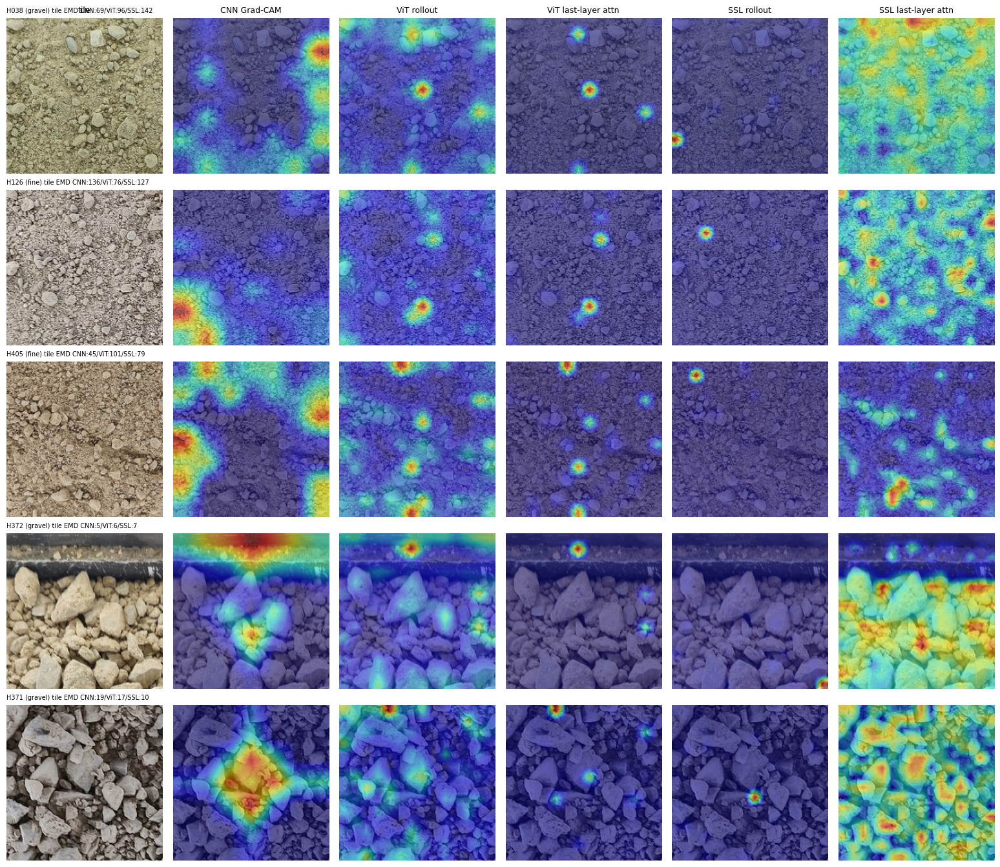

,sample_id,soil,tile_emd_CNN,tile_emd_ViT,tile_emd_SSL
0,H038,gravel,68.720863,95.913138,141.939916
1,H126,fine,136.091827,75.620971,126.746872
2,H405,fine,44.742131,101.429072,78.716808
3,H372,gravel,4.625054,6.053598,7.251697
4,H371,gravel,18.577868,16.539654,9.503914


In [37]:
# ===== Part 4: interpretation - Grad-CAM (CNN), attention rollout (ViT / SSL), same tiles for all three approaches =====
APPROACH = {"CNN": ("convnext_t_ft_t224", CONVNEXT_T),
            "ViT": ("vits_sup_ft_llrd_t224", VITS),
            "SSL": ("dinov2s_ft_llrd_t224", DINO_S)}


def load_ft_net(run, backbone, sid):
    """Fine-tuned network of the LOSO fold in which `sid` was held out (weights are kept for VIS_SIDS)."""
    fold = int(folds.loc[folds["sample_id"] == sid, "fold"].iloc[0])
    sd = torch.load(run.tracker.weights_dir / f"fold{fold:02d}_{sid}.pt", map_location="cpu")
    set_norm(backbone)
    with pooled(backbone, "default"):
        net = ImageNet(backbone, freeze_bn=True)
    net.load_state_dict({k: v.float() for k, v in sd.items()})
    return net.to(CFG.DEVICE).eval()


def gradcam(net, x):
    """Grad-CAM of the last conv feature map w.r.t. the predicted mean % passing (fineness of the predicted curve)."""
    with torch.enable_grad():
        fmap = net.backbone.forward_features(x)
        pooled_feat = net.backbone.forward_head(fmap, pre_logits=True)
        curve = net.head(pooled_feat)
        score = curve[:, 1:-1].mean()
        g = torch.autograd.grad(score, fmap)[0]
    cam = F.relu((g.mean((2, 3), keepdim=True) * fmap).sum(1, keepdim=True))
    cam = F.interpolate(cam, size=x.shape[-2:], mode="bilinear", align_corners=False)[0, 0]
    return (cam / (cam.max() + 1e-8)).detach().cpu().numpy(), curve.detach().float().cpu().numpy()[0]


@torch.no_grad()
def vit_attention_maps(net, x):
    """Raw CLS attention of the last block and attention rollout (head-mean, +I, row-normalised, multiplied over layers)."""
    bb, store, hooks, fused = net.backbone, [], [], []
    for blk in bb.blocks:
        fused.append(getattr(blk.attn, "fused_attn", None))
        if fused[-1] is not None:
            blk.attn.fused_attn = False                       # the explicit softmax path exposes the attention matrix
        hooks.append(blk.attn.attn_drop.register_forward_hook(lambda m, i, o: store.append(i[0].detach().float().cpu())))
    try:
        curve = net(x).float().cpu().numpy()[0]
    finally:
        for h in hooks:
            h.remove()
        for blk, fl in zip(bb.blocks, fused):
            if fl is not None:
                blk.attn.fused_attn = fl
    A = [a.mean(1)[0] for a in store]                         # (T, T) per layer
    T_ = A[0].shape[0]
    R = torch.eye(T_)
    for a in A:
        a = a + torch.eye(T_)
        R = (a / a.sum(-1, keepdim=True)) @ R
    n_pref = bb.num_prefix_tokens

    def to_map(v):
        side = int(round(v.numel() ** 0.5))
        m = v.reshape(side, side)[None, None]
        m = F.interpolate(m, size=(224, 224), mode="bilinear", align_corners=False)[0, 0]
        return ((m - m.min()) / (m.max() - m.min() + 1e-8)).numpy()

    return to_map(R[0, n_pref:]), to_map(A[-1][0, n_pref:]), curve


def interpretation_figure(vis_sids):
    idx224 = TILE_INDEX[224]
    cols = ["tile", "CNN Grad-CAM", "ViT rollout", "ViT last-layer attn", "SSL rollout", "SSL last-layer attn"]
    fig, axes = plt.subplots(len(vis_sids), len(cols), figsize=(2.6 * len(cols), 2.7 * len(vis_sids)), squeeze=False)
    rows = []
    for r, sid in enumerate(vis_sids):
        t = idx224[(idx224["split"] == "train") & (idx224["sample_id"] == sid)].sort_values("std")
        row = t.iloc[len(t) // 2]                                 # tile with the median contrast
        img = np.array(Image.open(row["path"]).convert("RGB"))
        y_true = LABELS.loc[sid].to_numpy()
        maps = {"tile": None}
        errs = {}
        for appr, (run_name, backbone) in APPROACH.items():
            net = load_ft_net(RUNS[run_name], backbone, sid)
            x = ((torch.from_numpy(img).permute(2, 0, 1).float() / 255 - torch.tensor(CFG.MEAN).view(3, 1, 1))
                 / torch.tensor(CFG.STD).view(3, 1, 1))[None].to(CFG.DEVICE)
            if appr == "CNN":
                maps["CNN Grad-CAM"], curve = gradcam(net, x)
            else:
                maps[f"{appr} rollout"], maps[f"{appr} last-layer attn"], curve = vit_attention_maps(net, x)
            errs[appr] = emd_per_sample(y_true, enforce_monotone(curve)[0])[0]
            del net
        for c, name in enumerate(cols):
            ax = axes[r, c]
            ax.imshow(img)
            if maps.get(name) is not None:
                ax.imshow(maps[name], cmap="jet", alpha=0.5)
            ax.axis("off")
            if r == 0:
                ax.set_title(name, fontsize=9)
        axes[r, 0].set_title(f"{sid} ({SOIL[sid]}) tile EMD " + "/".join(f"{k}:{v:.0f}" for k, v in errs.items()), fontsize=7, loc="left")
        rows.append(dict(sample_id=sid, soil=SOIL[sid], **{f"tile_emd_{k}": v for k, v in errs.items()}))
    plt.tight_layout()
    plt.savefig(CFG.OUTPUT_DIR / "interpretation_maps.png", dpi=110)
    plt.show()
    return pd.DataFrame(rows)


safe("interpretation maps", lambda: display(interpretation_figure(VIS_SIDS)))

### ===== C15: layer-wise linear CKA, pretrained vs fine-tuned (fold weights from C8) =====


[norm] vit_small_patch16_224.augreg_in21k_ft_in1k: mean=(0.5, 0.5, 0.5) std=(0.5, 0.5, 0.5)
[norm] vit_small_patch14_dinov2.lvd142m: mean=(0.485, 0.456, 0.406) std=(0.229, 0.224, 0.225)
layer          block1  block4  block6  block9  block12  final
model   split                                                
dinov2s test    0.942   0.958   0.943   0.853    0.815  0.798
        train   0.975   0.947   0.861   0.756    0.683  0.593
vits    test    1.000   1.000   0.999   0.975    0.937  0.913
        train   1.000   0.999   0.991   0.887    0.739  0.578


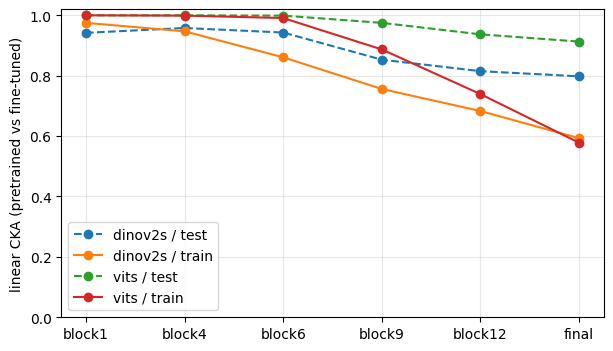

In [38]:
from torch.utils.data import DataLoader

def linear_cka(X, Y):
    X = X - X.mean(0, keepdims=True); Y = Y - Y.mean(0, keepdims=True)
    return float(np.linalg.norm(Y.T @ X, "fro") ** 2 / (np.linalg.norm(X.T @ X, "fro") * np.linalg.norm(Y.T @ Y, "fro")))

@torch.no_grad()
def layer_feats(model, paths, layers):
    loader = DataLoader(TileDataset(paths, None, tile_transform(False)), batch_size=64, num_workers=CFG.NUM_WORKERS)
    store, hooks = {}, []
    for li in layers:
        hooks.append(model.blocks[li].register_forward_hook(lambda m, i, o, li=li: store.setdefault(li, []).append(o.float().mean(1).cpu())))
    final = []
    for x in loader:
        with torch.autocast("cuda", enabled=CFG.DEVICE == "cuda"):
            final.append(model(x.to(CFG.DEVICE)).float().cpu())
    for h in hooks:
        h.remove()
    out = {f"block{li + 1}": torch.cat(store[li]).numpy() for li in layers}
    out["final"] = torch.cat(final).numpy()
    return out

LAYERS = [0, 3, 5, 8, 11]
CKA_FOLDS = VIS_SIDS[:3]
idx224 = TILE_INDEX[224]
tr_all = idx224[(idx224["split"] == "train") & idx224["sample_id"].isin(SIDS)]
te_all = idx224[idx224["split"] == "test"]
rows = []
for name, backbone in (("vits_sup_ft_llrd_t224", "vit_small_patch16_224.augreg_in21k_ft_in1k"),
                       ("dinov2s_ft_llrd_t224", "vit_small_patch14_dinov2.lvd142m")):
    set_norm(backbone)
    run_dir = RUNS[name].tracker.dir
    base = build_backbone(backbone).to(CFG.DEVICE).eval()
    for held in CKA_FOLDS:
        fold = int(folds.loc[folds["sample_id"] == held, "fold"].iloc[0])
        sd = torch.load(run_dir / "weights" / f"fold{fold:02d}_{held}.pt", map_location="cpu")
        ft = build_backbone(backbone)
        ft.load_state_dict({k[len("backbone."):]: v.float() for k, v in sd.items() if k.startswith("backbone.")})
        ft = ft.to(CFG.DEVICE).eval()
        for split, pool in (("train", tr_all[tr_all["sample_id"] != held]), ("test", te_all)):
            paths = pool["path"].sample(min(512, len(pool)), random_state=0).tolist()
            a, b = layer_feats(base, paths, LAYERS), layer_feats(ft, paths, LAYERS)
            for k in a:
                rows.append(dict(model=name.split("_")[0], fold=held, split=split, layer=k, cka=linear_cka(a[k], b[k])))
        del ft
        gc.collect()
        if CFG.DEVICE == "cuda":
            torch.cuda.empty_cache()
    del base

cka = pd.DataFrame(rows)
order = [f"block{l + 1}" for l in LAYERS] + ["final"]
tab = cka.pivot_table(index=["model", "split"], columns="layer", values="cka", aggfunc="mean")[order].round(3)
print(tab.to_string())

fig, ax = plt.subplots(figsize=(7, 4))
for (m, sp), row in tab.iterrows():
    ax.plot(order, row.values, marker="o", ls="-" if sp == "train" else "--", label=f"{m} / {sp}")
ax.set_ylabel("linear CKA (pretrained vs fine-tuned)"); ax.set_ylim(0, 1.02); ax.legend(); ax.grid(alpha=.3)
plt.show()
cka.to_csv(CFG.OUTPUT_DIR / "cka_frozen_vs_ft.csv", index=False)

[start] scale robustness | elapsed 3.87 h
[norm] convnext_tiny.fb_in22k_ft_in1k: mean=(0.485, 0.456, 0.406) std=(0.229, 0.224, 0.225)
[norm] convnext_tiny.fb_in22k_ft_in1k: mean=(0.485, 0.456, 0.406) std=(0.229, 0.224, 0.225)
[norm] convnext_tiny.fb_in22k_ft_in1k: mean=(0.485, 0.456, 0.406) std=(0.229, 0.224, 0.225)
[norm] convnext_tiny.fb_in22k_ft_in1k: mean=(0.485, 0.456, 0.406) std=(0.229, 0.224, 0.225)
[norm] convnext_tiny.fb_in22k_ft_in1k: mean=(0.485, 0.456, 0.406) std=(0.229, 0.224, 0.225)
[norm] convnext_tiny.fb_in22k_ft_in1k: mean=(0.485, 0.456, 0.406) std=(0.229, 0.224, 0.225)
[norm] convnext_tiny.fb_in22k_ft_in1k: mean=(0.485, 0.456, 0.406) std=(0.229, 0.224, 0.225)
[norm] convnext_tiny.fb_in22k_ft_in1k: mean=(0.485, 0.456, 0.406) std=(0.229, 0.224, 0.225)
[norm] convnext_tiny.fb_in22k_ft_in1k: mean=(0.485, 0.456, 0.406) std=(0.229, 0.224, 0.225)
[norm] convnext_tiny.fb_in22k_ft_in1k: mean=(0.485, 0.456, 0.406) std=(0.229, 0.224, 0.225)
[norm] vit_small_patch16_224.augreg_in

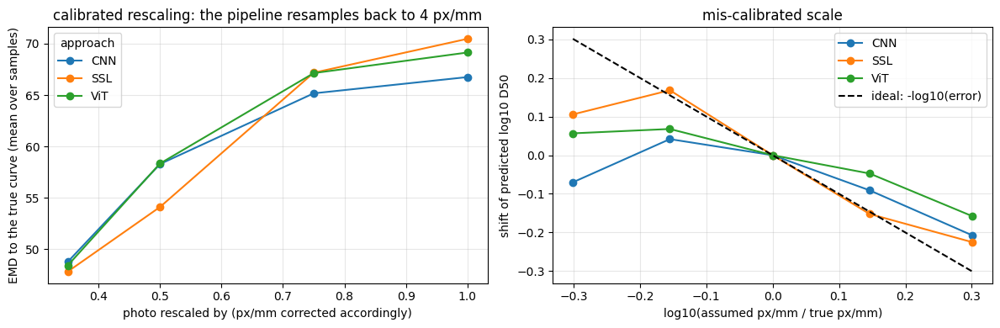

emd  logD50
approach kind          factor                
CNN      calibrated    0.35    48.761  -0.391
                       0.50    58.279  -0.285
                       0.75    65.168  -0.191
                       1.00    66.750  -0.183
         miscalibrated 0.50    62.146  -0.253
                       0.70    69.520  -0.141
                       1.00    66.750  -0.183
                       1.40    59.450  -0.274
                       2.00    49.224  -0.390
SSL      calibrated    0.35    47.803  -0.440
                       0.50    54.097  -0.402
                       0.75    67.175  -0.284
                       1.00    70.477  -0.232
         miscalibrated 0.50    77.680  -0.127
                       0.70    81.142  -0.064
                       1.00    70.477  -0.232
                       1.40    55.560  -0.384
                       2.00    44.474  -0.457
ViT      calibrated    0.35    48.408  -0.391
                       0.50    58.331  -0.305
                       0.75    67.138  -0.217
                       1.00    69.144  -0.186
         miscalibrated 0.50    72.596  -0.130
                       0.70    76.182  -0.118
                       1.00    69.144  -0.186
                       1.40    62.146  -0.234
                       2.00    49.252  -0.344

In [39]:
# ===== Part 6: scale robustness - the same photos at a different scale (calibrated or mis-calibrated px/mm) =====
def _prep_photo(path, ppm_eff, pre_resize=1.0, ppm_mult=1.0):
    """pre_resize: the photo is physically down/up-scaled and ppm is corrected (a calibrated rescaled photo).
    ppm_mult: the photo is untouched but the scale handed to the pipeline is wrong by this factor."""
    with Image.open(path) as im:
        img = ImageOps.exif_transpose(im).convert("RGB")
    if pre_resize != 1.0:
        img = img.resize((max(1, round(img.width * pre_resize)), max(1, round(img.height * pre_resize))), Image.Resampling.LANCZOS)
    f = CFG.PX_PER_MM / (ppm_eff * pre_resize * ppm_mult)
    size = (max(1, round(img.width * f)), max(1, round(img.height * f)))
    return img if size == img.size else img.resize(size, Image.Resampling.LANCZOS)


def _tiles_of(img, t=224):
    ys, xs = tile_positions(img.height, t), tile_positions(img.width, t)
    if not ys or not xs:
        return np.zeros((0, t, t, 3), np.uint8)
    return np.stack([np.asarray(img.crop((x, y, x + t, y + t))) for y in ys for x in xs])


@torch.no_grad()
def predict_tiles(net, tiles_u8):
    if len(tiles_u8) == 0:
        return None
    mean = torch.tensor(CFG.MEAN, device=CFG.DEVICE).view(1, 3, 1, 1)
    std = torch.tensor(CFG.STD, device=CFG.DEVICE).view(1, 3, 1, 1)
    out = []
    for i in range(0, len(tiles_u8), 64):
        x = torch.from_numpy(tiles_u8[i:i + 64]).to(CFG.DEVICE).permute(0, 3, 1, 2).float() / 255
        x = (x - mean) / std
        with torch.autocast("cuda", enabled=CFG.DEVICE == "cuda"):
            out.append(torch.stack([net(v).float() for v in dihedral_views(x)]).mean(0).cpu())
    return torch.cat(out).numpy()


def scale_robustness(vis_sids, pre_resizes=(0.35, 0.5, 0.75, 1.0), ppm_mults=(0.5, 0.7, 1.0, 1.4, 2.0)):
    rows = []
    for appr, (run_name, backbone) in APPROACH.items():
        if run_name not in RUNS:
            continue
        for sid in vis_sids:
            set_norm(backbone)
            net = load_ft_net(RUNS[run_name], backbone, sid)
            ph = photos[(photos["split"] == "train") & (photos["sample_id"] == sid)]
            y_true = LABELS.loc[sid].to_numpy()
            for kind, grid in (("calibrated", pre_resizes), ("miscalibrated", ppm_mults)):
                for g in grid:
                    preds = []
                    for _, r in ph.iterrows():
                        img = _prep_photo(r["path"], r["ppm_eff"], g if kind == "calibrated" else 1.0,
                                          1.0 if kind == "calibrated" else g)
                        pr = predict_tiles(net, _tiles_of(img))
                        if pr is not None:
                            preds.append(pr.mean(0))
                    if preds:
                        curve = enforce_monotone(np.mean(preds, 0))[0]
                        rows.append(dict(approach=appr, sample_id=sid, kind=kind, factor=g,
                                         emd=emd_per_sample(y_true, curve)[0], logD50=np.log10(d_value(curve, 50))))
            del net
    res = pd.DataFrame(rows)
    res.to_csv(CFG.OUTPUT_DIR / "scale_robustness.csv", index=False)
    return res


def plot_scale(res):
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    cal = res[res["kind"] == "calibrated"].groupby(["approach", "factor"])["emd"].mean().unstack(0)
    cal.plot(ax=axes[0], marker="o")
    axes[0].set_xlabel("photo rescaled by (px/mm corrected accordingly)")
    axes[0].set_ylabel("EMD to the true curve (mean over samples)")
    axes[0].set_title("calibrated rescaling: the pipeline resamples back to 4 px/mm")
    mis = res[res["kind"] == "miscalibrated"].copy()
    ref = mis[mis["factor"] == 1.0].set_index(["approach", "sample_id"])["logD50"]
    mis["shift"] = [r.logD50 - ref.get((r.approach, r.sample_id), np.nan) for r in mis.itertuples()]
    sh = mis.groupby(["approach", "factor"])["shift"].mean().unstack(0)
    sh.index = np.log10(sh.index)
    sh.plot(ax=axes[1], marker="o")
    axes[1].plot(sh.index, -sh.index, "k--", label="ideal: -log10(error)")
    axes[1].set_xlabel("log10(assumed px/mm / true px/mm)")
    axes[1].set_ylabel("shift of predicted log10 D50")
    axes[1].set_title("mis-calibrated scale")
    axes[1].legend()
    for ax in axes:
        ax.grid(alpha=.3)
    plt.tight_layout()
    plt.savefig(CFG.OUTPUT_DIR / "scale_robustness.png", dpi=120)
    plt.show()


def _scale_block():
    res = scale_robustness(VIS_SIDS)
    plot_scale(res)
    display(res.groupby(["approach", "kind", "factor"])[["emd", "logD50"]].mean().round(3))


safe("scale robustness", _scale_block, 0.1)

In [40]:
# ===== Part 4: shortcut controls (numeric): does the model need grains, colour, layout or only scale / metadata? =====
# Ridge on frozen ViT-S features, trained and evaluated on perturbed tiles with the same LOSO folds.
BASE224 = TILE_INDEX[224].copy()


def p_gray(a, rng):                                    # removes colour
    return np.repeat(a.mean(-1, keepdims=True), 3, -1).astype(np.uint8)


def p_shuffle_patches(a, rng, p=32):                   # destroys spatial layout, keeps local texture and colour
    n = a.shape[0] // p
    pt = a[:n * p, :n * p].reshape(n, p, n, p, 3).transpose(0, 2, 1, 3, 4).reshape(n * n, p, p, 3)
    pt = pt[rng.permutation(n * n)].reshape(n, n, p, p, 3).transpose(0, 2, 1, 3, 4).reshape(n * p, n * p, 3)
    out = a.copy()
    out[:n * p, :n * p] = pt
    return out


def p_shuffle_pixels(a, rng):                          # keeps only the colour histogram
    flat = a.reshape(-1, 3)
    return flat[rng.permutation(len(flat))].reshape(a.shape)


def p_blur(a, rng):                                    # removes fine grain detail
    from PIL import ImageFilter
    return np.asarray(Image.fromarray(a).filter(ImageFilter.GaussianBlur(radius=2)))


PERTURB = {"gray": p_gray, "shuffle_patches": p_shuffle_patches, "shuffle_pixels": p_shuffle_pixels, "blur": p_blur}


def build_perturbed_index(name, fn):
    root = CFG.OUTPUT_DIR / "tiles_ctrl" / name
    new, paths = BASE224.copy(), []
    for i, p in zip(BASE224.index, BASE224["path"]):
        q = root / Path(p).relative_to(tile_dir(224))
        if not q.exists():
            q.parent.mkdir(parents=True, exist_ok=True)
            Image.fromarray(fn(np.asarray(Image.open(p).convert("RGB")), np.random.default_rng(int(i)))).save(q)
        paths.append(str(q))
    new["path"] = paths
    return new


def _ctrl(name, fn):
    with variant_tiles(build_perturbed_index(name, fn), f"ctrl_{name}"), pooled(VITS, "avgcat"):
        run = run_loso_sklearn(f"ctrl_{name}_vits_ridge", VITS, tile_px=224, head="ridge")
    report_loso(run, show=False)
    RUNS[f"ctrl_{name}_vits_ridge"] = run


for name, fn in PERTURB.items():
    safe(f"control {name}", lambda name=name, fn=fn: _ctrl(name, fn), 0.1)


def make_meta_features():
    """Scale / device / position of the tile only - no pixel content at all."""
    idx = TILE_INDEX[224]
    ph = photos.set_index("file")
    X = np.concatenate([np.stack([idx["factor"], idx["file"].map(ph["ppm_eff"]), idx["x"] / 1000, idx["y"] / 1000], 1),
                        pd.get_dummies(idx["device"]).to_numpy(float)], 1).astype(np.float32)
    np.save(CFG.FEAT_DIR / "metafeat_t224_d4.npy", np.repeat(X[:, None], 4, 1).astype(np.float16))


def _ctrl_meta():
    make_meta_features()
    for head in ("ridge", "knn"):
        run = run_loso_sklearn(f"ctrl_meta_{head}", "metafeat", tile_px=224, head=head)
        report_loso(run, show=False)
        RUNS[f"ctrl_meta_{head}"] = run


safe("control meta-only (scale / device / position)", _ctrl_meta, 0.05)

reg_ = registry_table()
want = ["vits_sup_ridge_t224", "handcrafted_ridge_t224", "ctrl_gray_vits_ridge", "ctrl_shuffle_patches_vits_ridge",
        "ctrl_shuffle_pixels_vits_ridge", "ctrl_blur_vits_ridge", "ctrl_meta_ridge", "ctrl_meta_knn"]
ctrl_tab = reg_.loc[[w for w in want if w in reg_.index], ["loso_emd", "loso_emd_std", "loso_emd_median", "emd_fine", "emd_sand", "emd_gravel"]].round(2)
ctrl_tab.loc["mean-curve baseline", "loso_emd"] = round(MEAN_CURVE_EMD, 2)
display(ctrl_tab)
ctrl_tab.to_csv(CFG.OUTPUT_DIR / "controls_table.csv")
export_snapshot(include_features=False)

[start] control gray | elapsed 3.92 h
[tracker] ctrl_gray_vits_ridge_20261031-162049
[norm] vit_small_patch16_224.augreg_in21k_ft_in1k: mean=(0.5, 0.5, 0.5) std=(0.5, 0.5, 0.5)


features vit_small_patch16_224.augreg_in21k_ft_in1k @ 224px:   0%|          | 0/43 [00:00<?, ?it/s]

[ctrl_gray_vits_ridge] LOSO EMD 42.78 ± 31.61 (median 32.04, mean-curve 88.32) | by class {'fine': 54.56, 'gravel': 31.04, 'sand': 54.45}
[start] control shuffle_patches | elapsed 3.97 h
[tracker] ctrl_shuffle_patches_vits_ridge_20261031-162339
[norm] vit_small_patch16_224.augreg_in21k_ft_in1k: mean=(0.5, 0.5, 0.5) std=(0.5, 0.5, 0.5)


features vit_small_patch16_224.augreg_in21k_ft_in1k @ 224px:   0%|          | 0/43 [00:00<?, ?it/s]

[ctrl_shuffle_patches_vits_ridge] LOSO EMD 39.73 ± 28.52 (median 30.07, mean-curve 88.32) | by class {'fine': 51.34, 'gravel': 28.92, 'sand': 49.4}
[start] control shuffle_pixels | elapsed 4.01 h
[tracker] ctrl_shuffle_pixels_vits_ridge_20261031-162554
[norm] vit_small_patch16_224.augreg_in21k_ft_in1k: mean=(0.5, 0.5, 0.5) std=(0.5, 0.5, 0.5)


features vit_small_patch16_224.augreg_in21k_ft_in1k @ 224px:   0%|          | 0/43 [00:00<?, ?it/s]

[ctrl_shuffle_pixels_vits_ridge] LOSO EMD 43.41 ± 25.92 (median 41.33, mean-curve 88.32) | by class {'fine': 62.05, 'gravel': 31.38, 'sand': 46.18}
[start] control blur | elapsed 4.05 h
[tracker] ctrl_blur_vits_ridge_20261031-162857
[norm] vit_small_patch16_224.augreg_in21k_ft_in1k: mean=(0.5, 0.5, 0.5) std=(0.5, 0.5, 0.5)


features vit_small_patch16_224.augreg_in21k_ft_in1k @ 224px:   0%|          | 0/43 [00:00<?, ?it/s]

[ctrl_blur_vits_ridge] LOSO EMD 42.12 ± 29.52 (median 34.10, mean-curve 88.32) | by class {'fine': 57.98, 'gravel': 29.52, 'sand': 50.17}
[start] control meta-only (scale / device / position) | elapsed 4.11 h
[tracker] ctrl_meta_ridge_20261031-163119
[norm] metafeat: mean=(0.485, 0.456, 0.406) std=(0.229, 0.224, 0.225)
[ctrl_meta_ridge] LOSO EMD 86.69 ± 24.56 (median 89.00, mean-curve 88.32) | by class {'fine': 105.21, 'gravel': 80.33, 'sand': 75.99}
[tracker] ctrl_meta_knn_20261031-163122
[norm] metafeat: mean=(0.485, 0.456, 0.406) std=(0.229, 0.224, 0.225)
[ctrl_meta_knn] LOSO EMD 88.52 ± 25.46 (median 87.34, mean-curve 88.32) | by class {'fine': 110.08, 'gravel': 79.08, 'sand': 81.0}


,loso_emd,loso_emd_std,loso_emd_median,emd_fine,emd_sand,emd_gravel
name,,,,,,
vits_sup_ridge_t224,39.87,29.26,30.38,51.20,49.55,29.22
handcrafted_ridge_t224,38.82,22.81,36.20,47.00,46.26,30.95
ctrl_gray_vits_ridge,42.78,31.61,32.04,54.56,54.45,31.04
ctrl_shuffle_patches_vits_ridge,39.73,28.52,30.07,51.34,49.40,28.92
ctrl_shuffle_pixels_vits_ridge,43.41,25.92,41.33,62.05,46.18,31.38
ctrl_blur_vits_ridge,42.12,29.52,34.10,57.98,50.17,29.52
ctrl_meta_ridge,86.69,24.56,89.00,105.21,75.99,80.33
ctrl_meta_knn,88.52,25.46,87.34,110.08,81.00,79.08
mean-curve baseline,88.32,NaN,NaN,NaN,NaN,NaN


results_snapshot.zip: 4.3 MB


In [41]:
# ===== Part 0: alternative target = quantile function log10 D_p(p)  (W1 on the log-diameter axis == EMD) =====
def _alt(short, bb, pool, head):
    with pooled(bb, pool):
        run = run_loso_sklearn(f"alt_{short}_{head}_quantile_t224", bb, tile_px=224, head=head, target="quantile")
    report_loso(run, show=False)
    RUNS[f"alt_{short}_{head}_quantile_t224"] = run


for short, bb, pool in (("maeb", MAEB, "avgcat"), ("effb0", EFFB0, "default"), ("vits_sup", VITS, "avgcat")):
    for head in ("ridge", "knn"):
        safe(f"alt target {short} {head}", lambda short=short, bb=bb, pool=pool, head=head: _alt(short, bb, pool, head), 0.1)

reg_ = registry_table()
rows = []
for short in ("maeb", "effb0", "vits_sup"):
    for head in ("ridge", "knn"):
        for tgt, nm in (("curve", f"{short}_{head}_t224"), ("quantile", f"alt_{short}_{head}_quantile_t224")):
            if nm in reg_.index:
                rows.append(dict(backbone=short, head=head, target=tgt, cv=reg_.loc[nm, "loso_emd"], std=reg_.loc[nm, "loso_emd_std"],
                                 D50_err=reg_.loc[nm, "D50_log_err"]))
if rows:
    alt_tab = pd.DataFrame(rows).round(2)
    display(alt_tab)
    alt_tab.to_csv(CFG.OUTPUT_DIR / "alt_target.csv", index=False)

[start] alt target maeb ridge | elapsed 4.11 h
[tracker] alt_maeb_ridge_quantile_t224_20261031-163123
[norm] vit_base_patch16_224.mae: mean=(0.485, 0.456, 0.406) std=(0.229, 0.224, 0.225)
[alt_maeb_ridge_quantile_t224] LOSO EMD 38.64 ± 25.69 (median 33.07, mean-curve 88.32) | by class {'fine': 53.48, 'gravel': 30.49, 'sand': 37.39}
[start] alt target maeb knn | elapsed 4.15 h
[tracker] alt_maeb_knn_quantile_t224_20261031-163406
[norm] vit_base_patch16_224.mae: mean=(0.485, 0.456, 0.406) std=(0.229, 0.224, 0.225)
[alt_maeb_knn_quantile_t224] LOSO EMD 39.41 ± 27.50 (median 35.38, mean-curve 88.32) | by class {'fine': 49.17, 'gravel': 33.22, 'sand': 40.63}
[start] alt target effb0 ridge | elapsed 4.16 h
[tracker] alt_effb0_ridge_quantile_t224_20261031-163408
[norm] tf_efficientnet_b0.ns_jft_in1k: mean=(0.485, 0.456, 0.406) std=(0.229, 0.224, 0.225)
[alt_effb0_ridge_quantile_t224] LOSO EMD 39.56 ± 28.89 (median 30.03, mean-curve 88.32) | by class {'fine': 54.28, 'gravel': 30.18, 'sand': 41

,backbone,head,target,cv,std,D50_err
0,maeb,ridge,curve,37.81,27.05,0.32
1,maeb,ridge,quantile,38.64,25.69,0.37
2,maeb,knn,curve,40.70,27.94,0.37
3,maeb,knn,quantile,39.41,27.50,0.39
4,effb0,ridge,curve,40.80,29.34,0.35
5,effb0,ridge,quantile,39.56,28.89,0.36
6,effb0,knn,curve,39.08,29.43,0.32
7,effb0,knn,quantile,37.84,28.81,0.34
8,vits_sup,ridge,curve,39.87,29.26,0.33
9,vits_sup,ridge,quantile,38.29,28.49,0.34


[start] data efficiency effb0 0.25 #0 | elapsed 4.22 h
[tracker] de_effb0_f25_s0_20261031-163800
[norm] tf_efficientnet_b0.ns_jft_in1k: mean=(0.485, 0.456, 0.406) std=(0.229, 0.224, 0.225)
[start] data efficiency effb0 0.25 #1 | elapsed 4.22 h
[tracker] de_effb0_f25_s1_20261031-163806
[norm] tf_efficientnet_b0.ns_jft_in1k: mean=(0.485, 0.456, 0.406) std=(0.229, 0.224, 0.225)
[start] data efficiency effb0 0.25 #2 | elapsed 4.22 h
[tracker] de_effb0_f25_s2_20261031-163812
[norm] tf_efficientnet_b0.ns_jft_in1k: mean=(0.485, 0.456, 0.406) std=(0.229, 0.224, 0.225)
[start] data efficiency effb0 0.5 #0 | elapsed 4.22 h
[tracker] de_effb0_f50_s0_20261031-163817
[norm] tf_efficientnet_b0.ns_jft_in1k: mean=(0.485, 0.456, 0.406) std=(0.229, 0.224, 0.225)
[start] data efficiency effb0 0.5 #1 | elapsed 4.23 h
[tracker] de_effb0_f50_s1_20261031-163825
[norm] tf_efficientnet_b0.ns_jft_in1k: mean=(0.485, 0.456, 0.406) std=(0.229, 0.224, 0.225)
[start] data efficiency effb0 0.5 #2 | elapsed 4.23 h
[tr

frac                0.25   0.50   1.00
approach backbone                     
CNN      effb0     48.19  44.87  40.56
SSL      dinov2s   50.33  46.39  40.87
         maeb      47.50  43.08  39.74
ViT      vits_sup  50.14  45.15  39.54

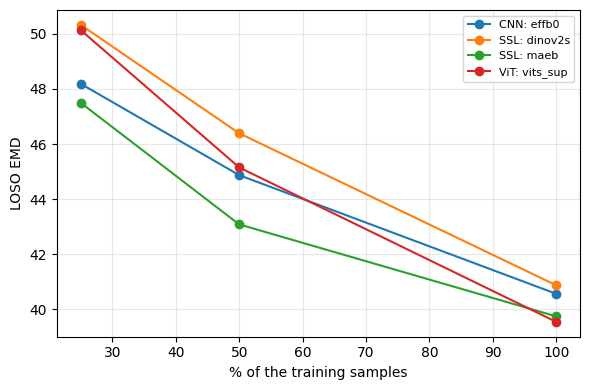

In [42]:
# ===== Part 6: data efficiency - training on a fraction of the training SAMPLES (ridge heads, same LOSO folds) =====
DE_APPROACHES = [("CNN", "effb0", EFFB0, "default"), ("ViT", "vits_sup", VITS, "avgcat"),
                 ("SSL", "dinov2s", DINO_S, "avgcat"), ("SSL", "maeb", MAEB, "avgcat")]


def _de(appr, short, bb, pool, frac, rep):
    with pooled(bb, pool):
        run = run_loso_sklearn(f"de_{short}_f{int(frac * 100)}_s{rep}", bb, tile_px=224, head="ridge", alphas=(1e3,),
                               train_frac=frac, frac_seed=rep, predict_test=False)
    return dict(approach=appr, backbone=short, frac=frac, rep=rep,
                emd=emd_score(LABELS.loc[run.oof.index].to_numpy(), run.oof.to_numpy()))


de_rows = []
for appr, short, bb, pool in DE_APPROACHES:
    for frac in (0.25, 0.5, 1.0):
        for rep in range(1 if frac == 1.0 else 3):
            r = safe(f"data efficiency {short} {frac} #{rep}", lambda a=appr, s=short, b=bb, p=pool, f_=frac, r_=rep: _de(a, s, b, p, f_, r_), 0.05)
            if r:
                de_rows.append(r)
DE = pd.DataFrame(de_rows)
if len(DE):
    DE.to_csv(CFG.OUTPUT_DIR / "data_efficiency.csv", index=False)
    piv = DE.groupby(["approach", "backbone", "frac"])["emd"].mean().unstack("frac").round(2)
    display(piv)
    fig, ax = plt.subplots(figsize=(6, 4))
    for (a, b), row in piv.iterrows():
        ax.plot(row.index * 100, row.values, marker="o", label=f"{a}: {b}")
    ax.set_xlabel("% of the training samples"); ax.set_ylabel("LOSO EMD"); ax.grid(alpha=.3); ax.legend(fontsize=8)
    plt.tight_layout(); plt.savefig(CFG.OUTPUT_DIR / "data_efficiency.png", dpi=120); plt.show()

### H7 — continued DINO на тайлах: scale-safe проти resize
Гіпотеза: DINO-адаптація DINOv2-S на unlabeled train-тайлах зі scale-safe multi-crop (кроп без resize, мм/пікс збережено) дасть ridge/kNN CV ≤ оригіналу (42.15 / 40.08) і зменшить ratio test/train NN-відстані (3.16). Resize-кропи (стандартні, змінюють мм/пікс) не допоможуть або нашкодять. Спростування: scale-safe ≥ оригіналу, або різниці між safe і resize немає.
Обмеження: SSL бачить unlabeled-зображення всіх 24 train-семплів, у тому числі held-out семпл кожного LOSO-фолда. Це трансдуктивно (без міток), але вносить легкий leakage у LOSO. Це записати у звіт.

### ===== C16: continued DINO on unlabeled train tiles (DINOv2-S), scale-safe vs resize multi-crop =====


In [43]:
# ===== C16: continued DINO on unlabeled train tiles (DINOv2-S), scale-safe vs resize multi-crop =====
import copy, math, time
import torch.nn as nn, torch.nn.functional as F
import torchvision.transforms.v2.functional as TF

DINO_S = "vit_small_patch14_dinov2.lvd142m"

class DinoHead(nn.Module):                      # as in the course repo (ssl_methods.py)
    def __init__(self, in_dim, out_dim=2048, hidden=2048, bottleneck=256):
        super().__init__()
        self.mlp = nn.Sequential(nn.Linear(in_dim, hidden), nn.GELU(), nn.Linear(hidden, hidden), nn.GELU(),
                                 nn.Linear(hidden, bottleneck))
        self.prototypes = nn.Parameter(torch.randn(out_dim, bottleneck) * 0.02)
    def forward(self, x):
        return F.normalize(self.mlp(x), dim=-1) @ F.normalize(self.prototypes, dim=-1).T

def dino_loss(student_logits, teacher_logits, center, s_temp=0.1, t_temp=0.04):
    targets = [F.softmax((t - center) / t_temp, dim=-1) for t in teacher_logits]
    log_p = [F.log_softmax(s / s_temp, dim=-1) for s in student_logits]
    terms = [-(q * lp).sum(-1).mean() for i, q in enumerate(targets) for j, lp in enumerate(log_p) if i != j]
    return torch.stack(terms).mean()

def _jitter(x):      # mild brightness/contrast only: colour carries the label
    b = 1 + (torch.rand(1, device=x.device) - .5) * 0.3
    c = 1 + (torch.rand(1, device=x.device) - .5) * 0.3
    m = x.mean()
    return ((x - m) * c + m) * b

def _dihedral(x):
    if torch.rand(1) < .5: x = x.flip(-1)
    if torch.rand(1) < .5: x = x.flip(-2)
    return torch.rot90(x, int(torch.randint(0, 4, (1,))), (-2, -1))

def _crop(img, size, scale_safe, area):
    H = img.shape[-1]
    if scale_safe:                                   # plain crop: 1 mm = 4 px always
        y, x = np.random.randint(0, H - size + 1, 2)
        out = img[:, y:y + size, x:x + size]
    else:                                            # standard RandomResizedCrop: changes mm/px (label-destroying)
        a = np.random.uniform(*area) * H * H
        r = math.exp(np.random.uniform(math.log(3 / 4), math.log(4 / 3)))
        w, h = int(min(H, round(math.sqrt(a * r)))), int(min(H, round(math.sqrt(a / r))))
        y, x = np.random.randint(0, H - h + 1), np.random.randint(0, H - w + 1)
        out = F.interpolate(img[None, :, y:y + h, x:x + w], size=(size, size), mode="bilinear",
                            align_corners=False, antialias=True)[0]
    out = _jitter(_dihedral(out))
    if np.random.rand() < 0.3:
        out = TF.gaussian_blur(out, kernel_size=5, sigma=float(np.random.uniform(0.5, 1.5)))
    return out

def make_views(batch, scale_safe, n_local, dev, g=224, l=98):
    mean = torch.tensor(CFG.MEAN, device=dev).view(3, 1, 1); std = torch.tensor(CFG.STD, device=dev).view(3, 1, 1)
    imgs = batch.to(dev).float() / 255
    norm = lambda lst: (torch.stack(lst) - mean) / std
    G = [norm([_crop(im, g, scale_safe, (.4, 1.)) for im in imgs]) for _ in range(2)]
    L = [norm([_crop(im, l, scale_safe, (.05, .4)) for im in imgs]) for _ in range(n_local)]
    return G, L

def _groups(mod, lr, is_bb):
    nd = lambda n, p: p.ndim <= 1 or any(k in n for k in NO_DECAY_KEYS)
    return [dict(params=[p for n, p in mod.named_parameters() if p.requires_grad and not nd(n, p)], base=lr, lr=lr, is_bb=is_bb, weight_decay=0.05),
            dict(params=[p for n, p in mod.named_parameters() if p.requires_grad and nd(n, p)], base=lr, lr=lr, is_bb=is_bb, weight_decay=0.0)]

def continue_dino(tag, epochs=60, scale_safe=True, bs=32, n_local=4, backbone_lr=2e-5, head_lr=5e-4,
                  ema=0.996, head_warmup_epochs=3, K=2048, t_temp=(0.04, 0.04), anchor_w=0.0):
    """Continue DINO pre-training of DINOv2-S on the unlabelled TRAIN tiles (384 px = 96 mm).
    t_temp: teacher temperature (start, end) - linear warm-up over the first half of the epochs.
    anchor_w > 0: add (1 - cos) between student CLS features and the frozen ORIGINAL encoder (limits forgetting).
    Every epoch is logged to <tag>_history.csv: loss, teacher entropy, #prototypes used (argmax) and the
    effective number of prototypes exp(H(mean teacher probs)) = collapse diagnostics."""
    if CFG.QUICK:
        epochs, bs, n_local = min(epochs, 3), min(bs, 4), min(n_local, 2)
    dev = CFG.DEVICE
    set_norm(DINO_S)
    idx = TILE_INDEX[384]
    paths = idx.loc[(idx["split"] == "train") & idx["sample_id"].isin(SIDS), "path"].tolist()
    if CFG.QUICK:
        paths = paths[:16]
    data = torch.stack([torch.from_numpy(np.array(Image.open(p).convert("RGB"))).permute(2, 0, 1) for p in paths])
    bs = min(bs, len(data))
    print(f"[{tag}] {len(data)} unlabeled 384px train tiles | scale_safe={scale_safe} | epochs={epochs} | anchor_w={anchor_w}")
    mk = lambda dp: timm.create_model(DINO_S, pretrained=True, num_classes=0, img_size=224, dynamic_img_size=True, drop_path_rate=dp)
    student, teacher = mk(0.1).to(dev), mk(0.0).to(dev)
    teacher.load_state_dict(student.state_dict())
    orig = None
    if anchor_w > 0:
        orig = mk(0.0).to(dev).eval()
        for p in orig.parameters():
            p.requires_grad = False
    s_head = DinoHead(student.num_features, K).to(dev); t_head = copy.deepcopy(s_head)
    for p in list(teacher.parameters()) + list(t_head.parameters()):
        p.requires_grad = False
    teacher.eval(); student.train()
    opt = AdamW(_groups(student, backbone_lr, True) + _groups(s_head, head_lr, False))
    scaler = torch.amp.GradScaler(enabled=dev == "cuda")
    spe = max(1, len(data) // bs); total = epochs * spe
    center = torch.zeros(1, K, device=dev)
    t0, step, hist = time.time(), 0, []
    for ep in range(epochs):
        perm = torch.randperm(len(data))
        stats = []
        t_now = t_temp[0] + (t_temp[1] - t_temp[0]) * min(1.0, ep / max(1, epochs // 2))
        for i in range(spe):
            progress = step / total
            f = 0.5 * (1 + math.cos(math.pi * progress)) * min(1.0, (step + 1) / spe)
            for g in opt.param_groups:
                g["lr"] = g["base"] * f * (0.0 if (g["is_bb"] and ep < head_warmup_epochs) else 1.0)
            G, L = make_views(data[perm[i * bs:(i + 1) * bs]], scale_safe, n_local, dev)
            with torch.autocast("cuda", dtype=torch.float16, enabled=dev == "cuda"):
                with torch.no_grad():
                    t_logits = t_head(teacher(torch.cat(G))).float()
                    a_feat = orig(torch.cat(G)).float() if orig is not None else None
                f_g = student(torch.cat(G))
                s_g = s_head(f_g).float().chunk(2)
                s_l = s_head(student(torch.cat(L))).float().chunk(n_local)
            loss_dino = dino_loss(list(s_g) + list(s_l), t_logits.chunk(2), center, t_temp=t_now)
            loss_anchor = (1 - F.cosine_similarity(f_g.float(), a_feat, dim=-1)).mean() if orig is not None else torch.zeros((), device=dev)
            loss = loss_dino + anchor_w * loss_anchor
            opt.zero_grad(set_to_none=True)
            scaler.scale(loss).backward()
            scaler.unscale_(opt)
            nn.utils.clip_grad_norm_(list(student.parameters()) + list(s_head.parameters()), 3.0)
            scaler.step(opt); scaler.update()
            with torch.no_grad():
                tau = 1 - (1 - ema) * (math.cos(math.pi * progress) + 1) / 2
                for pt, ps in zip(list(teacher.parameters()) + list(t_head.parameters()),
                                  list(student.parameters()) + list(s_head.parameters())):
                    pt.mul_(tau).add_(ps.detach(), alpha=1 - tau)
                p_t = F.softmax((t_logits.chunk(2)[0] - center) / t_now, dim=-1)
                mean_p = p_t.mean(0)
                stats.append((loss_dino.item(), -(p_t * p_t.clamp_min(1e-12).log()).sum(-1).mean().item(),
                              p_t.argmax(-1).unique().numel(), math.exp(-(mean_p * mean_p.clamp_min(1e-12).log()).sum().item()),
                              float(loss_anchor)))
                center = 0.9 * center + 0.1 * t_logits.mean(0, keepdim=True)
            step += 1
        l, e, u, eff, an = np.mean(stats, axis=0)
        hist.append(dict(epoch=ep + 1, loss=l, teacher_entropy=e, prototypes_used=u, eff_prototypes=eff, anchor=an, t_temp=t_now))
        if ep % 5 == 0 or ep == epochs - 1:
            print(f"  ep {ep + 1:03d}/{epochs} loss {l:.3f} | teacher entropy {e:.2f} (max {math.log(K):.2f}) | "
                  f"prototypes used {u:.0f}, effective {eff:.1f} | anchor {an:.3f} | {time.time() - t0:.0f}s")
            if e < 0.05 or e > math.log(K) - 0.05:
                print("  !! possible collapse (entropy at an extreme)")
    pd.DataFrame(hist).to_csv(CFG.OUTPUT_DIR / f"{tag}_history.csv", index=False)
    out = CFG.OUTPUT_DIR / f"{tag}_teacher.pt"
    torch.save(teacher.state_dict(), out)
    del student, teacher, s_head, t_head, opt, orig
    if dev == "cuda":
        torch.cuda.empty_cache()
    return dict(tag=tag, scale_safe=scale_safe, epochs=epochs, gpu_min=round((time.time() - t0) / 60, 1), path=str(out))


def plot_da_history(tags):
    fig, axes = plt.subplots(1, 4, figsize=(19, 3.8))
    for tag in tags:
        p = CFG.OUTPUT_DIR / f"{tag}_history.csv"
        if not p.exists():
            continue
        h = pd.read_csv(p)
        for ax, col in zip(axes, ("loss", "teacher_entropy", "eff_prototypes", "anchor")):
            ax.plot(h["epoch"], h[col], label=tag)
    for ax, t in zip(axes, ("DINO loss", "teacher entropy", "effective prototypes", "anchor loss (1 - cos to original)")):
        ax.set_title(t); ax.set_xlabel("epoch"); ax.grid(alpha=.3)
    axes[0].legend(fontsize=7)
    plt.tight_layout()
    plt.savefig(CFG.OUTPUT_DIR / "da_training_curves.png", dpi=120)
    plt.show()

print("C16 ok")

C16 ok


### ===== C17: run continued DINO (scale-safe vs resize) and re-evaluate with the same heads =====

[start] dinov2s_cdino_safe | elapsed 4.27 h
[norm] vit_small_patch14_dinov2.lvd142m: mean=(0.485, 0.456, 0.406) std=(0.229, 0.224, 0.225)
[dinov2s_cdino_safe] 546 unlabeled 384px train tiles | scale_safe=True | epochs=60 | anchor_w=0.0
  ep 001/60 loss 7.382 | teacher entropy 6.99 (max 7.62) | prototypes used 19, effective 1541.0 | anchor 0.000 | 9s
  ep 006/60 loss 7.019 | teacher entropy 6.95 (max 7.62) | prototypes used 10, effective 1651.2 | anchor 0.000 | 54s
  ep 011/60 loss 6.050 | teacher entropy 5.97 (max 7.62) | prototypes used 8, effective 904.3 | anchor 0.000 | 99s
  ep 016/60 loss 4.941 | teacher entropy 4.86 (max 7.62) | prototypes used 8, effective 385.9 | anchor 0.000 | 143s
  ep 021/60 loss 4.005 | teacher entropy 3.90 (max 7.62) | prototypes used 8, effective 175.6 | anchor 0.000 | 188s
  ep 026/60 loss 3.403 | teacher entropy 3.24 (max 7.62) | prototypes used 8, effective 102.8 | anchor 0.000 | 233s
  ep 031/60 loss 3.019 | teacher entropy 2.90 (max 7.62) | prototype

features dinov2s_cdino_safe @ 224px:   0%|          | 0/43 [00:00<?, ?it/s]

[dinov2s_cdino_safe] nn_dist train-LOSO median 0.0416 | test median 0.2177 | ratio 5.24
[tracker] dinov2s_cdino_safe_ridge_t224_20261031-165016
[norm] dinov2s_cdino_safe: mean=(0.485, 0.456, 0.406) std=(0.229, 0.224, 0.225)
[dinov2s_cdino_safe_ridge_t224] LOSO EMD 41.76 ± 33.86 (median 30.04, mean-curve 88.32) | by class {'fine': 58.1, 'gravel': 27.34, 'sand': 53.49}
[tracker] dinov2s_cdino_safe_knn_t224_20261031-165150
[norm] dinov2s_cdino_safe: mean=(0.485, 0.456, 0.406) std=(0.229, 0.224, 0.225)
[dinov2s_cdino_safe_knn_t224] LOSO EMD 40.76 ± 30.75 (median 35.02, mean-curve 88.32) | by class {'fine': 58.36, 'gravel': 28.39, 'sand': 45.79}
[start] dinov2s_cdino_resize | elapsed 4.46 h
[norm] vit_small_patch14_dinov2.lvd142m: mean=(0.485, 0.456, 0.406) std=(0.229, 0.224, 0.225)
[dinov2s_cdino_resize] 546 unlabeled 384px train tiles | scale_safe=False | epochs=60 | anchor_w=0.0
  ep 001/60 loss 7.403 | teacher entropy 7.06 (max 7.62) | prototypes used 21, effective 1570.4 | anchor 0.000

features dinov2s_cdino_resize @ 224px:   0%|          | 0/43 [00:00<?, ?it/s]

[dinov2s_cdino_resize] nn_dist train-LOSO median 0.0419 | test median 0.2190 | ratio 5.23
[tracker] dinov2s_cdino_resize_ridge_t224_20261031-170138
[norm] dinov2s_cdino_resize: mean=(0.485, 0.456, 0.406) std=(0.229, 0.224, 0.225)
[dinov2s_cdino_resize_ridge_t224] LOSO EMD 43.57 ± 33.37 (median 33.69, mean-curve 88.32) | by class {'fine': 60.0, 'gravel': 29.16, 'sand': 55.17}
[tracker] dinov2s_cdino_resize_knn_t224_20261031-170312
[norm] dinov2s_cdino_resize: mean=(0.485, 0.456, 0.406) std=(0.229, 0.224, 0.225)
[dinov2s_cdino_resize_knn_t224] LOSO EMD 42.73 ± 31.34 (median 39.75, mean-curve 88.32) | by class {'fine': 61.06, 'gravel': 28.86, 'sand': 50.33}
[start] dinov2s_cdino_safe_anchor | elapsed 4.64 h
[norm] vit_small_patch14_dinov2.lvd142m: mean=(0.485, 0.456, 0.406) std=(0.229, 0.224, 0.225)
[dinov2s_cdino_safe_anchor] 546 unlabeled 384px train tiles | scale_safe=True | epochs=60 | anchor_w=1.0
  ep 001/60 loss 7.476 | teacher entropy 7.04 (max 7.62) | prototypes used 22, effectiv

features dinov2s_cdino_safe_anchor @ 224px:   0%|          | 0/43 [00:00<?, ?it/s]

[dinov2s_cdino_safe_anchor] nn_dist train-LOSO median 0.0136 | test median 0.0781 | ratio 5.73
[tracker] dinov2s_cdino_safe_anchor_ridge_t224_20261031-171411
[norm] dinov2s_cdino_safe_anchor: mean=(0.485, 0.456, 0.406) std=(0.229, 0.224, 0.225)
[dinov2s_cdino_safe_anchor_ridge_t224] LOSO EMD 41.95 ± 30.99 (median 32.91, mean-curve 88.32) | by class {'fine': 57.06, 'gravel': 29.3, 'sand': 51.16}
[tracker] dinov2s_cdino_safe_anchor_knn_t224_20261031-171605
[norm] dinov2s_cdino_safe_anchor: mean=(0.485, 0.456, 0.406) std=(0.229, 0.224, 0.225)
[dinov2s_cdino_safe_anchor_knn_t224] LOSO EMD 40.83 ± 30.53 (median 37.06, mean-curve 88.32) | by class {'fine': 53.35, 'gravel': 30.96, 'sand': 47.0}
                                name  loso_emd  loso_emd_std  loso_emd_median  emd_fine  emd_gravel  emd_sand
                  dinov2s_ridge_t224    42.148        30.160           40.478     57.02       30.23     49.94
                    dinov2s_knn_t224    40.084        30.761           32.034     5

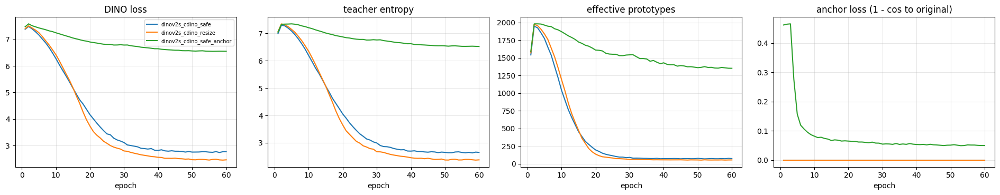

results_snapshot.zip: 4.5 MB


In [44]:
# ===== C17: run continued DINO (scale-safe / resize / scale-safe + anchor) and re-evaluate with the same heads =====
SSL_RUNS = [dict(tag="dinov2s_cdino_safe", scale_safe=True),
            dict(tag="dinov2s_cdino_resize", scale_safe=False),
            # stabilised variant: lower lrs, teacher temperature warm-up 0.04 -> 0.07, anchor to the original encoder
            dict(tag="dinov2s_cdino_safe_anchor", scale_safe=True, backbone_lr=1e-5, head_lr=1e-4,
                 t_temp=(0.04, 0.07), anchor_w=1.0)]
ssl_cost = []


def make_cdino_builder(path):
    def builder():
        m = timm.create_model(DINO_S, pretrained=False, num_classes=0, img_size=224, drop_path_rate=0.1)
        m.load_state_dict(torch.load(path, map_location="cpu"))
        return m
    return builder


def _ssl_eval(r):
    info = continue_dino(epochs=60, **r)
    ssl_cost.append(info)
    tag, path = info["tag"], info["path"]
    CUSTOM_BUILDERS[tag] = make_cdino_builder(path)
    NORM[tag] = ((0.485, 0.456, 0.406), (0.229, 0.224, 0.225))
    POOL[tag] = "avgcat"                       # same pooling as dinov2s_ridge/knn in C5
    nn_report(tag, tag)                        # test/train NN distance ratio (original DINOv2-S: see C12)
    for head in ("ridge", "knn"):
        run = run_loso_sklearn(f"{tag}_{head}_t224", tag, tile_px=224, head=head)
        report_loso(run, show=False)
        make_submission(run.test_pred, f"submission_{tag}_{head}_t224.csv", run.tracker)
        RUNS[f"{tag}_{head}_t224"] = run


for r in SSL_RUNS:
    safe(r["tag"], lambda r=r: _ssl_eval(r), 0.4)

cmp_names = ["dinov2s_ridge_t224", "dinov2s_knn_t224"] + [f"{r['tag']}_{h}_t224" for r in SSL_RUNS for h in ("ridge", "knn")]
try:
    reg = pd.read_csv(CFG.EXP_DIR / "registry.csv")
    print(reg[reg["name"].isin(cmp_names)][["name", "loso_emd", "loso_emd_std", "loso_emd_median", "emd_fine", "emd_gravel", "emd_sand"]].to_string(index=False))
    print(pd.DataFrame(ssl_cost)[["tag", "scale_safe", "epochs", "gpu_min"]].to_string(index=False))
    plot_da_history([r["tag"] for r in SSL_RUNS])
except Exception:
    traceback.print_exc()
export_snapshot(include_features=False)

In [45]:
# ===== Part 1: CNN ablations on ResNet-18 (ablation folds): BatchNorm, GroupNorm, grouped batches, SGD, warmup, aug, resolution =====
CNN_ABL = [
    ("sub_r18_adamw_frozenbn", R18, dict()),                                    # baseline: AdamW, frozen BN statistics
    ("sub_r18_adamw_trainbn", R18, dict(freeze_bn=False)),                      # BN statistics updated on 64-tile batches
    ("sub_r18_grouped_frozenbn", R18, dict(group_batches=2)),                   # batches from only 2 physical samples
    ("sub_r18_grouped_trainbn", R18, dict(freeze_bn=False, group_batches=2)),   # ... with BN statistics updated
    ("sub_r18_groupnorm", "resnet18_gn", dict()),                               # BN -> GroupNorm(32)
    ("sub_r18_sgd", R18, dict(optimizer="sgd", lr=1e-2, backbone_lr=1e-3)),
    ("sub_r18_nowarmup", R18, dict(warmup_epochs=0)),
    ("sub_r18_noaug", R18, dict(aug=False)),
    ("sub_r18_t384", R18, dict(tile_px=384)),                                   # input resolution / field of view
]
for name, bb, kw in CNN_ABL:
    safe(name, lambda name=name, bb=bb, kw=kw: run_sub(name, bb, **{"backbone_lr": 1e-4, **kw}), 0.15)
safe("CNN ablation table", lambda: subset_table([n for n, _, _ in CNN_ABL], "sub_r18_adamw_frozenbn", "ablation_cnn.csv"))
export_snapshot(include_features=False)

[start] sub_r18_adamw_frozenbn | elapsed 4.86 h
[norm] resnet18.a1_in1k: mean=(0.485, 0.456, 0.406) std=(0.229, 0.224, 0.225)
[tracker] sub_r18_adamw_frozenbn_20261031-171608
Fold 01/24 | F827 (fine) | 96 val / 2097 train tiles
    epoch 08/8 | train 24.65 | val 55.47
Fold 02/24 | G190 (fine) | 96 val / 2097 train tiles
    epoch 08/8 | train 24.76 | val 15.75
Fold 04/24 | H037 (gravel) | 108 val / 2085 train tiles
    epoch 08/8 | train 23.00 | val 58.70
Fold 08/24 | H183 (gravel) | 120 val / 2073 train tiles
    epoch 08/8 | train 25.19 | val 12.99
Fold 09/24 | H366 (gravel) | 48 val / 2145 train tiles
    epoch 08/8 | train 24.34 | val 12.90
Fold 11/24 | H368 (gravel) | 72 val / 2121 train tiles
    epoch 08/8 | train 24.96 | val 15.27
Fold 17/24 | H516 (sand) | 60 val / 2133 train tiles
    epoch 08/8 | train 24.44 | val 46.92
Fold 23/24 | H666 (sand) | 60 val / 2133 train tiles
    epoch 08/8 | train 23.49 | val 59.93
[sub_r18_adamw_frozenbn] LOSO EMD 34.74 ± 22.29 (median 31.33, 

,run,folds,cv,std,diff_vs_base,wins,gpu_h,peak_gb,params_M,trainable_M
0,sub_r18_adamw_frozenbn,8,34.741,22.288,0.000,0,0.090,1.05,11.31,11.312
1,sub_r18_adamw_trainbn,8,34.639,22.228,-0.102,5,0.090,1.05,11.31,11.312
2,sub_r18_grouped_frozenbn,8,32.190,28.981,-2.551,5,0.091,1.05,11.31,11.312
3,sub_r18_grouped_trainbn,8,33.607,28.057,-1.134,5,0.090,1.05,11.31,11.312
4,sub_r18_groupnorm,8,35.099,25.493,0.358,4,0.104,1.90,11.31,11.312
5,sub_r18_sgd,8,33.031,21.782,-1.709,5,0.089,1.00,11.31,11.312
6,sub_r18_nowarmup,8,35.346,22.896,0.605,2,0.089,1.05,11.31,11.312
7,sub_r18_noaug,8,34.607,23.732,-0.134,4,0.082,1.05,11.31,11.312
8,sub_r18_t384,8,36.488,25.298,1.748,3,0.079,2.62,11.31,11.312


results_snapshot.zip: 4.5 MB


In [46]:
# ===== Part 2: ViT ablations on ViT-S (ablation folds); baseline = the main run vits_sup_ft_llrd_t224 on the same folds =====
def run_vit_variant(name, backbone=VITS, llrd="keep", drop_path=None, **kw):
    with ExitStack() as st:
        if llrd != "keep":
            st.enter_context(tmp_set(LLRD, backbone, llrd))
        if drop_path is not None:
            st.enter_context(tmp_set(MODEL_KWARGS, backbone, {**MODEL_KWARGS.get(backbone, {}), "drop_path_rate": drop_path}))
        st.enter_context(pooled(backbone, "default"))
        return run_sub(name, backbone, **{**dict(lr=1e-3, backbone_lr=1e-4, weight_decay=0.05), **kw})


VIT_ABL = [
    ("sub_vits_nollrd", dict(llrd=None)),                    # one lr for all layers
    ("sub_vits_dp0", dict(drop_path=0.0)),                   # no stochastic depth
    ("sub_vits_wd1e4", dict(weight_decay=1e-4)),             # CNN-style weight decay
    ("sub_vits_nowarmup", dict(warmup_epochs=0)),
    ("sub_vits_noaug", dict(aug=False)),
]
for name, kw in VIT_ABL:
    safe(name, lambda name=name, kw=kw: run_vit_variant(name, **kw), 0.2)

# other architectures / patch size, same recipe
MODEL_KWARGS[P32], MODEL_KWARGS[DEIT_S] = dict(img_size=224, drop_path_rate=0.1), dict(img_size=224, drop_path_rate=0.1)
ARCH_FT = [("sub_vits_patch32", P32, {}), ("sub_deit_s_ft", DEIT_S, {}), ("sub_swin_t_ft", SWIN_T, dict(llrd=None))]
for name, bb, kw in ARCH_FT:
    safe(name, lambda name=name, bb=bb, kw=kw: run_vit_variant(name, backbone=bb, **kw), 0.2)

# input resolution: frozen ViT-S features of 384-px tiles (pos-embed interpolated) vs 224-px
def _vits_384():
    with tmp_set(MODEL_KWARGS, VITS, dict(img_size=384)), pooled(VITS, "avgcat"):
        run = run_loso_sklearn("vits_sup_ridge_t384", VITS, tile_px=384, head="ridge")
    report_loso(run, show=False)
    RUNS["vits_sup_ridge_t384"] = run


safe("vits_sup_ridge_t384", _vits_384, 0.1)
safe("ViT ablation table", lambda: subset_table([n for n, _ in VIT_ABL] + [n for n, _, _ in ARCH_FT], "vits_sup_ft_llrd_t224", "ablation_vit.csv"))
export_snapshot(include_features=False)

[start] sub_vits_nollrd | elapsed 5.66 h
[norm] vit_small_patch16_224.augreg_in21k_ft_in1k: mean=(0.5, 0.5, 0.5) std=(0.5, 0.5, 0.5)
[tracker] sub_vits_nollrd_20261031-180422
Fold 01/24 | F827 (fine) | 96 val / 2097 train tiles
    epoch 08/8 | train 21.47 | val 63.43
Fold 02/24 | G190 (fine) | 96 val / 2097 train tiles
    epoch 08/8 | train 24.16 | val 42.88
Fold 04/24 | H037 (gravel) | 108 val / 2085 train tiles
    epoch 08/8 | train 21.60 | val 59.17
Fold 08/24 | H183 (gravel) | 120 val / 2073 train tiles
    epoch 08/8 | train 24.26 | val 14.86
Fold 09/24 | H366 (gravel) | 48 val / 2145 train tiles
    epoch 08/8 | train 22.47 | val 10.49
Fold 11/24 | H368 (gravel) | 72 val / 2121 train tiles
    epoch 08/8 | train 23.15 | val 13.85
Fold 17/24 | H516 (sand) | 60 val / 2133 train tiles
    epoch 08/8 | train 22.50 | val 57.07
Fold 23/24 | H666 (sand) | 60 val / 2133 train tiles
    epoch 08/8 | train 20.95 | val 66.28
[sub_vits_nollrd] LOSO EMD 41.00 ± 24.16 (median 49.97, mean-cu

model.safetensors: reconstructing file:   0%|          |  0.00B / 91.5MB            

model.safetensors: downloading bytes:           |  0.00B            

    epoch 08/8 | train 23.94 | val 60.05
Fold 02/24 | G190 (fine) | 96 val / 2097 train tiles
    epoch 08/8 | train 25.05 | val 15.66
Fold 04/24 | H037 (gravel) | 108 val / 2085 train tiles
    epoch 08/8 | train 24.60 | val 65.17
Fold 08/24 | H183 (gravel) | 120 val / 2073 train tiles
    epoch 08/8 | train 25.79 | val 14.67
Fold 09/24 | H366 (gravel) | 48 val / 2145 train tiles
    epoch 08/8 | train 26.33 | val 11.92
Fold 11/24 | H368 (gravel) | 72 val / 2121 train tiles
    epoch 08/8 | train 25.05 | val 14.80
Fold 17/24 | H516 (sand) | 60 val / 2133 train tiles
    epoch 08/8 | train 24.45 | val 51.11
Fold 23/24 | H666 (sand) | 60 val / 2133 train tiles
    epoch 08/8 | train 24.04 | val 61.27
[sub_vits_patch32] LOSO EMD 36.83 ± 24.46 (median 33.38, mean-curve 88.32) | by class {'fine': 37.85, 'gravel': 26.64, 'sand': 56.19}
[start] sub_deit_s_ft | elapsed 6.49 h
[norm] deit_small_patch16_224.fb_in1k: mean=(0.485, 0.456, 0.406) std=(0.229, 0.224, 0.225)
[tracker] sub_deit_s_ft_20

features vit_small_patch16_224.augreg_in21k_ft_in1k @ 384px:   0%|          | 0/12 [00:00<?, ?it/s]

[vits_sup_ridge_t384] LOSO EMD 41.19 ± 29.78 (median 29.91, mean-curve 88.32) | by class {'fine': 54.47, 'gravel': 29.66, 'sand': 50.28}
[start] ViT ablation table | elapsed 6.91 h


,run,folds,cv,std,diff_vs_base,wins,gpu_h,peak_gb,params_M,trainable_M
0,vits_sup_ft_llrd_t224,8,36.777,27.872,0.000,0,0.433,2.63,21.77,21.768
1,sub_vits_nollrd,8,41.003,24.158,4.226,4,0.147,2.63,21.77,21.768
2,sub_vits_dp0,8,41.005,27.435,4.227,2,0.145,2.63,21.77,21.768
3,sub_vits_wd1e4,8,38.352,29.337,1.575,3,0.148,2.63,21.77,21.768
4,sub_vits_nowarmup,8,35.692,27.216,-1.086,3,0.148,2.63,21.77,21.768
5,sub_vits_noaug,8,39.897,28.780,3.120,2,0.146,2.63,21.77,21.768
6,sub_vits_patch32,8,36.832,24.462,0.055,2,0.091,1.05,22.60,22.596
7,sub_deit_s_ft,8,38.750,28.670,1.973,3,0.148,2.63,21.77,21.768
8,sub_swin_t_ft,8,36.802,25.258,0.025,2,0.261,5.07,27.72,27.721


results_snapshot.zip: 4.5 MB


In [47]:
# ===== Part 3: tuning strategies per SSL encoder on the ablation folds: frozen -> LP -> LP-FT -> FT -> LoRA =====
# frozen / ridge / kNN / FT already exist for the full 24 folds; LP-FT and LoRA run on the ablation folds and are compared
# with the others restricted to the same folds.
MODEL_KWARGS[D3] = dict(img_size=224, drop_path_rate=0.1)
MODEL_KWARGS[MAEB] = dict(img_size=224, drop_path_rate=0.1)


def run_strategy(name, backbone, strategy, **kw):
    with pooled(backbone, "default"):
        defaults = dict(lr=1e-3, backbone_lr=5e-4 if strategy == "lora" else 1e-4, weight_decay=0.05, strategy=strategy)
        return run_sub(name, backbone, **{**defaults, **kw})


STRAT = [("sub_dinov2s_lpft", DINO_S, "lpft"), ("sub_dinov2s_lora", DINO_S, "lora"),
         ("sub_dinov3s_ft", D3, "ft"), ("sub_dinov3s_lora", D3, "lora"),
         ("sub_vits_lpft", VITS, "lpft"), ("sub_vits_lora", VITS, "lora")]
for name, bb, strat in STRAT:
    safe(name, lambda name=name, bb=bb, strat=strat: run_strategy(name, bb, strat), 0.2)


def _lora_count():
    n = ImageNet(DINO_S)
    total = sum(p.numel() for p in n.backbone.parameters())
    k = apply_lora(n.backbone, 8)
    print(f"LoRA r=8 on qkv + proj of every block: {k:,} trainable backbone params ({100 * k / total:.2f}% of the backbone)")


safe("LoRA parameter count", _lora_count)
safe("strategy table", lambda: subset_table(
    ["dinov2s_frozen_cls", "dinov2s_ridge_t224", "dinov2s_knn_t224", "sub_dinov2s_lpft", "dinov2s_ft_llrd_t224", "sub_dinov2s_lora",
     "dinov3s_frozen_avgcat", "dinov3s_ridge_t224", "sub_dinov3s_ft", "sub_dinov3s_lora",
     "vits_sup_frozen_cls", "vits_sup_ridge_t224", "sub_vits_lpft", "vits_sup_ft_llrd_t224", "sub_vits_lora"],
    "dinov2s_ft_llrd_t224", "strategies_ssl_vit.csv"))
export_snapshot(include_features=False)

[start] sub_dinov2s_lpft | elapsed 6.91 h
[norm] vit_small_patch14_dinov2.lvd142m: mean=(0.485, 0.456, 0.406) std=(0.229, 0.224, 0.225)
[tracker] sub_dinov2s_lpft_20261031-191941
[norm] vit_small_patch14_dinov2.lvd142m: mean=(0.485, 0.456, 0.406) std=(0.229, 0.224, 0.225)
Fold 01/24 | F827 (fine) | 96 val / 2097 train tiles


/usr/local/lib/python3.13/dist-packages/lightning/pytorch/loops/fit_loop.py:538: Found 7 module(s) in eval mode at the start of training. This may lead to unexpected behavior during training. If this is intentional, you can ignore this warning.


    epoch 08/8 | train 22.50 | val 62.82
Fold 02/24 | G190 (fine) | 96 val / 2097 train tiles


/usr/local/lib/python3.13/dist-packages/lightning/pytorch/loops/fit_loop.py:538: Found 7 module(s) in eval mode at the start of training. This may lead to unexpected behavior during training. If this is intentional, you can ignore this warning.


    epoch 08/8 | train 24.43 | val 18.67
Fold 04/24 | H037 (gravel) | 108 val / 2085 train tiles


/usr/local/lib/python3.13/dist-packages/lightning/pytorch/loops/fit_loop.py:538: Found 7 module(s) in eval mode at the start of training. This may lead to unexpected behavior during training. If this is intentional, you can ignore this warning.


... (25 outputs left out)

/usr/local/lib/python3.13/dist-packages/lightning/pytorch/loops/fit_loop.py:538: Found 7 module(s) in eval mode at the start of training. This may lead to unexpected behavior during training. If this is intentional, you can ignore this warning.


    epoch 08/8 | train 19.56 | val 78.33
[sub_vits_lpft] LOSO EMD 40.30 ± 27.63 (median 37.67, mean-curve 88.32) | by class {'fine': 41.65, 'gravel': 26.38, 'sand': 66.8}
[start] sub_vits_lora | elapsed 7.83 h
[norm] vit_small_patch16_224.augreg_in21k_ft_in1k: mean=(0.5, 0.5, 0.5) std=(0.5, 0.5, 0.5)
[tracker] sub_vits_lora_20261031-201452
Fold 01/24 | F827 (fine) | 96 val / 2097 train tiles
    epoch 08/8 | train 24.41 | val 51.48
Fold 02/24 | G190 (fine) | 96 val / 2097 train tiles
    epoch 08/8 | train 25.50 | val 12.70
Fold 04/24 | H037 (gravel) | 108 val / 2085 train tiles
    epoch 08/8 | train 23.68 | val 68.45
Fold 08/24 | H183 (gravel) | 120 val / 2073 train tiles
    epoch 08/8 | train 25.39 | val 13.81
Fold 09/24 | H366 (gravel) | 48 val / 2145 train tiles
    epoch 08/8 | train 24.75 | val 12.34
Fold 11/24 | H368 (gravel) | 72 val / 2121 train tiles
    epoch 08/8 | train 24.81 | val 13.54
Fold 17/24 | H516 (sand) | 60 val / 2133 train tiles
    epoch 08/8 | train 24.38 | 

,run,folds,cv,std,diff_vs_base,wins,gpu_h,peak_gb,params_M,trainable_M
0,dinov2s_ft_llrd_t224,8,37.772,27.845,0.000,0,0.579,3.58,21.73,21.731
1,dinov2s_frozen_cls,8,41.671,27.797,3.900,2,0.046,0.58,0.10,0.102
2,dinov2s_ridge_t224,8,38.427,25.406,0.655,2,0.024,0.01,NaN,NaN
3,dinov2s_knn_t224,8,41.322,28.848,3.551,3,0.000,0.05,NaN,NaN
4,sub_dinov2s_lpft,8,41.705,29.024,3.934,2,0.198,3.58,21.73,21.731
5,sub_dinov2s_lora,8,37.564,28.025,-0.208,4,0.182,2.29,21.95,0.323
6,dinov3s_frozen_avgcat,8,43.863,28.470,6.092,2,0.048,0.44,0.20,0.201
7,dinov3s_ridge_t224,8,39.322,27.345,1.550,3,0.024,0.01,NaN,NaN
8,sub_dinov3s_ft,8,41.208,33.296,3.437,3,0.201,3.14,21.69,21.689
9,sub_dinov3s_lora,8,39.747,31.832,1.976,4,0.189,2.07,21.91,0.323


results_snapshot.zip: 4.5 MB


In [48]:
# ===== Part 3: domain adaptation - tune the adapted encoders (FT / LoRA on the ablation folds), CKA before/after DA =====
def _da_tune(tag, strategy):
    LLRD[tag] = 0.75
    return run_strategy(f"sub_{tag}_{strategy}", tag, strategy)


for tag in ("dinov2s_cdino_safe", "dinov2s_cdino_safe_anchor"):
    if tag in CUSTOM_BUILDERS:
        for strat in ("ft", "lora"):
            safe(f"sub_{tag}_{strat}", lambda tag=tag, strat=strat: _da_tune(tag, strat), 0.2)


def _cka_da():
    set_norm(DINO_S)
    with pooled(DINO_S, "default"):
        base = build_backbone(DINO_S).to(CFG.DEVICE).eval()
    rows = []
    for tag in [t for t in ("dinov2s_cdino_safe", "dinov2s_cdino_resize", "dinov2s_cdino_safe_anchor") if t in CUSTOM_BUILDERS]:
        m = CUSTOM_BUILDERS[tag]().to(CFG.DEVICE).eval()
        for split, pool in (("train", tr_all), ("test", te_all)):
            paths = pool["path"].sample(min(512, len(pool)), random_state=0).tolist()
            a, b = layer_feats(base, paths, LAYERS), layer_feats(m, paths, LAYERS)
            rows.extend(dict(model=tag, split=split, layer=k, cka=linear_cka(a[k], b[k])) for k in a)
        del m
    tab = pd.DataFrame(rows)
    tab.to_csv(CFG.OUTPUT_DIR / "cka_domain_adaptation.csv", index=False)
    display(tab.pivot_table(index=["model", "split"], columns="layer", values="cka")[order].round(3))


safe("CKA DINOv2-S before/after domain adaptation", _cka_da)
safe("DA table", lambda: subset_table(
    ["dinov2s_frozen_cls", "dinov2s_ridge_t224", "dinov2s_knn_t224", "dinov2s_ft_llrd_t224", "sub_dinov2s_lora",
     "dinov2s_cdino_safe_ridge_t224", "dinov2s_cdino_safe_knn_t224", "sub_dinov2s_cdino_safe_ft", "sub_dinov2s_cdino_safe_lora",
     "dinov2s_cdino_safe_anchor_ridge_t224", "dinov2s_cdino_safe_anchor_knn_t224", "sub_dinov2s_cdino_safe_anchor_ft",
     "sub_dinov2s_cdino_safe_anchor_lora", "dinov2s_cdino_resize_ridge_t224", "dinov2s_cdino_resize_knn_t224"],
    "dinov2s_ft_llrd_t224", "domain_adaptation_table.csv"))
export_snapshot(include_features=False)

[start] sub_dinov2s_cdino_safe_ft | elapsed 7.98 h
[norm] dinov2s_cdino_safe: mean=(0.485, 0.456, 0.406) std=(0.229, 0.224, 0.225)
[tracker] sub_dinov2s_cdino_safe_ft_20261031-202320
Fold 01/24 | F827 (fine) | 96 val / 2097 train tiles
    epoch 08/8 | train 26.17 | val 52.50
Fold 02/24 | G190 (fine) | 96 val / 2097 train tiles
    epoch 08/8 | train 27.40 | val 53.85
Fold 04/24 | H037 (gravel) | 108 val / 2085 train tiles
    epoch 08/8 | train 24.10 | val 53.68
Fold 08/24 | H183 (gravel) | 120 val / 2073 train tiles
    epoch 08/8 | train 27.59 | val 14.99
Fold 09/24 | H366 (gravel) | 48 val / 2145 train tiles
    epoch 08/8 | train 27.69 | val 10.99
Fold 11/24 | H368 (gravel) | 72 val / 2121 train tiles
    epoch 08/8 | train 28.22 | val 13.37
Fold 17/24 | H516 (sand) | 60 val / 2133 train tiles
    epoch 08/8 | train 27.22 | val 47.36
Fold 23/24 | H666 (sand) | 60 val / 2133 train tiles
    epoch 08/8 | train 25.72 | val 56.66
[sub_dinov2s_cdino_safe_ft] LOSO EMD 37.93 ± 20.73 (med

layer                            block1  block4  block6  block9  block12  \
model                     split                                            
dinov2s_cdino_resize      test    0.928   0.948   0.944   0.912    0.888   
                          train   0.971   0.956   0.938   0.857    0.779   
dinov2s_cdino_safe        test    0.918   0.967   0.955   0.932    0.911   
                          train   0.957   0.959   0.946   0.864    0.762   
dinov2s_cdino_safe_anchor test    0.978   0.985   0.983   0.972    0.968   
                          train   0.990   0.990   0.988   0.973    0.957   

layer                            final  
model                     split         
dinov2s_cdino_resize      test   0.882  
                          train  0.727  
dinov2s_cdino_safe        test   0.895  
                          train  0.701  
dinov2s_cdino_safe_anchor test   0.964  
                          train  0.927

[start] DA table | elapsed 8.74 h


,run,folds,cv,std,diff_vs_base,wins,gpu_h,peak_gb,params_M,trainable_M
0,dinov2s_ft_llrd_t224,8,37.772,27.845,0.000,0,0.579,3.58,21.73,21.731
1,dinov2s_frozen_cls,8,41.671,27.797,3.900,2,0.046,0.58,0.10,0.102
2,dinov2s_ridge_t224,8,38.427,25.406,0.655,2,0.024,0.01,NaN,NaN
3,dinov2s_knn_t224,8,41.322,28.848,3.551,3,0.000,0.05,NaN,NaN
4,sub_dinov2s_lora,8,37.564,28.025,-0.208,4,0.182,2.29,21.95,0.323
5,dinov2s_cdino_safe_ridge_t224,8,43.633,30.714,5.861,3,0.026,0.02,NaN,NaN
6,dinov2s_cdino_safe_knn_t224,8,42.461,27.765,4.690,3,0.006,0.06,NaN,NaN
7,sub_dinov2s_cdino_safe_ft,8,37.926,20.733,0.154,4,0.197,3.58,21.73,21.731
8,sub_dinov2s_cdino_safe_lora,8,37.420,27.357,-0.352,4,0.182,2.29,21.95,0.323
9,dinov2s_cdino_safe_anchor_ridge_t224,8,39.851,26.221,2.080,2,0.032,0.02,NaN,NaN


results_snapshot.zip: 4.5 MB


In [49]:
# ===== Part 0: tile-size justification - px/mm of the tiles (coarser = larger field of view per 224-px tile) =====
def _ppm_ablation(ppm):
    old = CFG.PX_PER_MM
    CFG.PX_PER_MM = ppm
    try:
        new = make_tiles(photos, (224,))[224]
        with variant_tiles(new, f"ppm{ppm}"):
            for short, bb, pool in (("effb0", EFFB0, "default"), ("vits_sup", VITS, "avgcat")):
                for head in ("ridge", "knn"):
                    with pooled(bb, pool):
                        run = run_loso_sklearn(f"ppm{ppm}_{short}_{head}_t224", bb, tile_px=224, head=head, predict_test=False)
                    report_loso(run, show=False)
    finally:
        CFG.PX_PER_MM = old


for ppm in (2, 3):
    safe(f"tiles at {ppm} px/mm", lambda ppm=ppm: _ppm_ablation(ppm), 0.15)
reg_ = registry_table()
names = [f"{p}{s}_{h}_t224" for s in ("effb0", "vits_sup") for h in ("ridge", "knn") for p in ("ppm2_", "ppm3_", "")]
tab = reg_.loc[[n for n in names if n in reg_.index], ["cfg.tile_mm", "loso_emd", "loso_emd_std", "emd_fine", "emd_sand", "emd_gravel"]].round(2)
display(tab.sort_index())
tab.to_csv(CFG.OUTPUT_DIR / "tile_size_ablation.csv")

[start] tiles at 2 px/mm | elapsed 8.74 h


tiling [224]:   0%|          | 0/162 [00:00<?, ?it/s]


[tiles] 224 px = 112 mm: 613 tiles


photos  tiles  tiles_per_photo  coverage  \
split device                                                              
test  iPhone 14                    14     28              2.0      0.40   
      iPhone 16                    21     42              2.0      0.39   
train Motorola Edge                69    207              3.0      0.69   
      Motorola Edge 60 Fusion       3      6              2.0      0.41   
      Samsung A52                  55    330              6.0      0.81   

                               upsampled  
split device                              
test  iPhone 14                        0  
      iPhone 16                        0  
train Motorola Edge                    0  
      Motorola Edge 60 Fusion          0  
      Samsung A52                      0

[tracker] ppm2_effb0_ridge_t224_20261031-210925
[norm] tf_efficientnet_b0.ns_jft_in1k: mean=(0.485, 0.456, 0.406) std=(0.229, 0.224, 0.225)


features tf_efficientnet_b0.ns_jft_in1k @ 224px:   0%|          | 0/10 [00:00<?, ?it/s]

... (8 outputs left out)

[ppm3_effb0_ridge_t224] LOSO EMD 40.79 ± 30.71 (median 26.61, mean-curve 88.32) | by class {'fine': 52.84, 'gravel': 30.81, 'sand': 47.87}
[tracker] ppm3_effb0_knn_t224_20261031-211350
[norm] tf_efficientnet_b0.ns_jft_in1k: mean=(0.485, 0.456, 0.406) std=(0.229, 0.224, 0.225)
[ppm3_effb0_knn_t224] LOSO EMD 39.72 ± 30.11 (median 29.16, mean-curve 88.32) | by class {'fine': 54.16, 'gravel': 29.35, 'sand': 44.39}
[tracker] ppm3_vits_sup_ridge_t224_20261031-211351
[norm] vit_small_patch16_224.augreg_in21k_ft_in1k: mean=(0.5, 0.5, 0.5) std=(0.5, 0.5, 0.5)


features vit_small_patch16_224.augreg_in21k_ft_in1k @ 224px:   0%|          | 0/23 [00:00<?, ?it/s]

[ppm3_vits_sup_ridge_t224] LOSO EMD 41.04 ± 29.44 (median 32.03, mean-curve 88.32) | by class {'fine': 54.88, 'gravel': 29.44, 'sand': 49.52}
[tracker] ppm3_vits_sup_knn_t224_20261031-211516
[norm] vit_small_patch16_224.augreg_in21k_ft_in1k: mean=(0.5, 0.5, 0.5) std=(0.5, 0.5, 0.5)
[ppm3_vits_sup_knn_t224] LOSO EMD 39.80 ± 30.17 (median 30.88, mean-curve 88.32) | by class {'fine': 52.52, 'gravel': 29.67, 'sand': 46.28}


,cfg.tile_mm,loso_emd,loso_emd_std,emd_fine,emd_sand,emd_gravel
name,,,,,,
effb0_knn_t224,56.00,39.08,29.43,52.18,45.08,28.95
effb0_ridge_t224,56.00,40.80,29.34,53.65,49.55,29.66
ppm2_effb0_knn_t224,112.00,39.47,30.65,55.56,42.83,28.69
ppm2_effb0_ridge_t224,112.00,41.24,30.19,55.85,49.07,29.44
ppm2_vits_sup_knn_t224,112.00,39.29,29.76,50.45,47.36,29.42
ppm2_vits_sup_ridge_t224,112.00,40.72,28.04,51.63,51.21,29.99
ppm3_effb0_knn_t224,74.67,39.72,30.11,54.16,44.39,29.35
ppm3_effb0_ridge_t224,74.67,40.79,30.71,52.84,47.87,30.81
ppm3_vits_sup_knn_t224,74.67,39.80,30.17,52.52,46.28,29.67


In [50]:
# ===== Part 3: MAE - frozen vs fine-tuned ranking (ablation folds; the most expensive extra run, last in the queue) =====
safe("sub_maeb_ft", lambda: run_strategy("sub_maeb_ft", MAEB, "ft"), 0.7)
safe("MAE table", lambda: subset_table(["maeb_frozen_avgcat", "maeb_ridge_t224", "maeb_knn_t224", "sub_maeb_ft",
                                         "dinov2s_frozen_cls", "dinov2s_ft_llrd_t224"], "dinov2s_ft_llrd_t224", "mae_frozen_vs_ft.csv"))

[start] sub_maeb_ft | elapsed 8.85 h
[norm] vit_base_patch16_224.mae: mean=(0.485, 0.456, 0.406) std=(0.229, 0.224, 0.225)
[tracker] sub_maeb_ft_20261031-211538
Fold 01/24 | F827 (fine) | 96 val / 2097 train tiles
    epoch 08/8 | train 28.99 | val 53.56
Fold 02/24 | G190 (fine) | 96 val / 2097 train tiles
    epoch 08/8 | train 29.23 | val 11.58
Fold 04/24 | H037 (gravel) | 108 val / 2085 train tiles
    epoch 08/8 | train 27.07 | val 67.45
Fold 08/24 | H183 (gravel) | 120 val / 2073 train tiles
    epoch 08/8 | train 29.10 | val 13.94
Fold 09/24 | H366 (gravel) | 48 val / 2145 train tiles
    epoch 08/8 | train 29.67 | val 11.81
Fold 11/24 | H368 (gravel) | 72 val / 2121 train tiles
    epoch 08/8 | train 29.54 | val 15.39
Fold 17/24 | H516 (sand) | 60 val / 2133 train tiles
    epoch 08/8 | train 28.40 | val 42.97
Fold 23/24 | H666 (sand) | 60 val / 2133 train tiles
    epoch 08/8 | train 27.47 | val 70.08
[sub_maeb_ft] LOSO EMD 35.85 ± 25.64 (median 29.18, mean-curve 88.32) | by cl

,run,folds,cv,std,diff_vs_base,wins,gpu_h,peak_gb,params_M,trainable_M
0,dinov2s_ft_llrd_t224,8,37.772,27.845,0.000,0,0.579,3.58,21.73,21.731
1,maeb_frozen_avgcat,8,39.366,22.652,1.594,3,0.054,1.00,0.40,0.399
2,maeb_ridge_t224,8,35.200,21.436,-2.571,4,0.044,0.01,NaN,NaN
3,maeb_knn_t224,8,41.338,24.354,3.567,3,0.000,0.06,NaN,NaN
4,sub_maeb_ft,8,35.850,25.635,-1.922,6,0.358,5.93,86.00,86.000
5,dinov2s_frozen_cls,8,41.671,27.797,3.900,2,0.046,0.58,0.10,0.102


,run,folds,cv,std,diff_vs_base,wins,gpu_h,peak_gb,params_M,trainable_M
0,dinov2s_ft_llrd_t224,8,37.772,27.845,0.000,0,0.579,3.58,21.73,21.731
1,maeb_frozen_avgcat,8,39.366,22.652,1.594,3,0.054,1.00,0.40,0.399
2,maeb_ridge_t224,8,35.200,21.436,-2.571,4,0.044,0.01,NaN,NaN
3,maeb_knn_t224,8,41.338,24.354,3.567,3,0.000,0.06,NaN,NaN
4,sub_maeb_ft,8,35.850,25.635,-1.922,6,0.358,5.93,86.00,86.000
5,dinov2s_frozen_cls,8,41.671,27.797,3.900,2,0.046,0.58,0.10,0.102


In [51]:
# ===== Part 6: comparison table (quality / cost / robustness) and per-device / per-soil-class failures =====
def throughput(builder, bs=64, tile=224, iters=15):
    dev = CFG.DEVICE
    m = builder().to(dev).eval()
    n_params = sum(p.numel() for p in m.parameters()) / 1e6
    x = torch.randn(bs, 3, tile, tile, device=dev)
    with torch.no_grad(), torch.autocast("cuda", enabled=dev == "cuda"):
        for _ in range(2):
            m(x)
        if dev == "cuda":
            torch.cuda.synchronize()
        t0 = time.time()
        for _ in range(iters):
            m(x)
        if dev == "cuda":
            torch.cuda.synchronize()
    del m
    return bs * iters / (time.time() - t0), n_params


def _comparison():
    reg_ = registry_table()
    rows = []
    for appr, nm in (("CNN", "convnext_t_ft_t224"), ("ViT", "vits_sup_ft_llrd_t224"), ("SSL", "dinov2s_ft_llrd_t224")):
        r = reg_.loc[nm]
        ips, npar = throughput(lambda: build_backbone(r["cfg.backbone"]))
        rows.append(dict(approach=appr, run=nm, cv=f"{r['loso_emd']:.2f} ± {r['loso_emd_std']:.2f}", fine=r["emd_fine"], sand=r["emd_sand"],
                         gravel=r["emd_gravel"], gpu_h=r["gpu_hours"], peak_mem_gb=r["peak_mem_gb"], params_M=round(npar, 1),
                         infer_img_per_s=round(ips)))
    tab = pd.DataFrame(rows).set_index("approach")
    try:
        sc = pd.read_csv(CFG.OUTPUT_DIR / "scale_robustness.csv")
        mis = sc[sc["kind"] == "miscalibrated"]
        ref = mis[mis["factor"] == 1.0].set_index(["approach", "sample_id"])["logD50"]
        x2 = mis[mis["factor"] == 2.0]
        tab["scale_x2_dlogD50"] = pd.Series({a: np.mean([r.logD50 - ref[(a, r.sample_id)] for r in x2[x2["approach"] == a].itertuples()])
                                             for a in x2["approach"].unique()})
    except Exception:
        traceback.print_exc()
    try:
        de = pd.read_csv(CFG.OUTPUT_DIR / "data_efficiency.csv")
        d = de.groupby(["approach", "frac"])["emd"].mean().unstack("frac")
        tab["EMD@25%_samples"], tab["EMD@100%_samples"] = d[0.25], d[1.0]
    except Exception:
        traceback.print_exc()
    display(tab.round(3))
    tab.to_csv(CFG.OUTPUT_DIR / "comparison_table.csv")


safe("comparison table", _comparison)


def _per_device():
    reg_ = registry_table()
    out = []
    for appr, nm in (("CNN", "convnext_t_ridge_t224"), ("ViT", "vits_sup_ridge_t224"), ("SSL", "maeb_ridge_t224")):
        ph = pd.read_csv(Path(reg_.loc[nm, "run_dir"]) / "oof_photo.csv", dtype={"sample_id": str})
        ph["emd"] = emd_per_sample(LABELS.loc[ph["sample_id"]].to_numpy(), ph[CFG.GRAIN_COLS].to_numpy())
        ph["soil"] = SOIL.loc[ph["sample_id"]].to_numpy()
        ph["approach"] = appr
        out.append(ph[["approach", "device", "soil", "emd"]])
    allp = pd.concat(out)
    by_dev = allp.pivot_table(index="device", columns="approach", values="emd", aggfunc="mean").round(1)
    by_soil = allp.pivot_table(index="soil", columns="approach", values="emd", aggfunc="mean").round(1)
    by_both = allp.pivot_table(index=["soil", "device"], columns="approach", values="emd", aggfunc="mean").round(1)
    display(by_dev), display(by_soil), display(by_both)
    by_both.to_csv(CFG.OUTPUT_DIR / "failures_by_soil_and_device.csv")


safe("per-device / per-soil errors", _per_device)

[start] comparison table | elapsed 9.21 h


,run,cv,fine,sand,gravel,gpu_h,peak_mem_gb,params_M,infer_img_per_s,scale_x2_dlogD50,EMD@25%_samples,EMD@100%_samples
approach,,,,,,,,,,,,
CNN,convnext_t_ft_t224,41.71 ± 33.35,53.58,52.23,30.40,0.629,4.57,27.8,681,-0.208,48.194,40.564
ViT,vits_sup_ft_llrd_t224,39.84 ± 33.90,49.24,51.73,29.39,0.433,2.63,21.7,1191,-0.158,50.142,39.542
SSL,dinov2s_ft_llrd_t224,39.30 ± 35.52,50.12,42.33,31.72,0.579,3.58,21.6,851,-0.225,48.917,40.306


[start] per-device / per-soil errors | elapsed 9.21 h


approach,CNN,SSL,ViT
device,,,
Motorola Edge,39.2,37.7,39.4
Motorola Edge 60 Fusion,16.9,32.5,25.3
Samsung A52,45.7,43.7,45.3


approach,CNN,SSL,ViT
soil,,,
fine,53.8,50.5,53.2
gravel,32.3,32.1,32.7
sand,46.7,45.4,47.1


approach                         CNN   SSL   ViT
soil   device                                   
fine   Motorola Edge            53.4  49.5  54.0
       Samsung A52              54.3  51.5  52.4
gravel Motorola Edge            28.6  28.4  28.2
       Motorola Edge 60 Fusion  16.9  32.5  25.3
       Samsung A52              38.6  36.8  39.4
sand   Motorola Edge            45.0  43.4  46.0
       Samsung A52              49.3  48.5  48.9

### ===== C18: final tables — best run per family (by CV), ensembles, error correlation, submission files =====


In [52]:
# ===== C18: final tables — best run per family (by CV), ensembles, error correlation, submission files =====
import itertools

FAMILY = {"CNN": ("effb0", "convnext_t", "convnextv2b", "r18"),
          "ViT": ("vits_sup", "deit", "swin", "maxvit"),   # pretrained supervised transformers; scratch ViTs are controls, not a family                       # pretrained supervised ViT; scratch ViT is a control, not a family
          "SSL": ("dinov2", "dinov3", "maeb")}

LB_SCORES = {"effb0_frozen_t224": (86.72682, None), "maeb_ridge_t224": (76.55106, None),
             "dinov2s_ft_llrd_t224": (83.05089, None)}          # public LB; private after the competition closes

reg = registry_table().reset_index()
reg = reg[reg["cfg.tile_mm"].notna() & (reg["n_folds"] == N_FOLDS) & ~reg["name"].str.startswith(AUX_PREFIX)]
reg = reg.sort_values("loso_emd").reset_index(drop=True)

def fam(n):
    if n.startswith("handcrafted"):
        return "handcrafted"
    return next((f for f, pre in FAMILY.items() if n.startswith(pre)), None)

reg["family"] = reg["name"].map(fam)
reg["LB public"] = [LB_SCORES.get(n, (None, None))[0] for n in reg["name"]]
cols = ["name", "family", "loso_emd", "loso_emd_std", "loso_emd_median", "emd_fine", "emd_gravel", "emd_sand", "LB public", "gpu_hours"]
reg[cols].to_csv(CFG.OUTPUT_DIR / "results_table.csv", index=False)
print("TOP 12 by CV")
print(reg[cols].head(12).round(2).to_string(index=False))

best = reg.dropna(subset=["family"]).groupby("family").head(1)
print("\nBest per family (by CV):")
print(best[cols].round(2).to_string(index=False))

O = {r["name"]: read_sample_table(Path(r["run_dir"]) / "oof.csv") for _, r in best.iterrows()}
T = {r["name"]: read_sample_table(Path(r["run_dir"]) / "test_preds.csv") for _, r in best.iterrows()}
names = list(O)
idx = O[names[0]].index
y = LABELS.loc[idx].to_numpy()

def ens(d, ns):
    ref = d[ns[0]].index
    return sum(d[n].loc[ref] for n in ns) / len(ns)

rows = []
for k in range(1, len(names) + 1):
    for ns in itertools.combinations(names, k):
        e = emd_per_sample(y, ens(O, ns).loc[idx].to_numpy())
        rows.append(dict(models=" + ".join(ns), k=k, cv=e.mean(), std=e.std(), median=np.median(e)))
E = pd.DataFrame(rows).sort_values("cv").reset_index(drop=True)
print("\nEnsembles of per-family bests (equal weights):")
print(E.round(2).to_string(index=False))

err = {n: (O[n].loc[idx].to_numpy() - y)[:, 1:].ravel() for n in names}
print("\nOOF error correlation:")
print(pd.DataFrame(err).corr().round(2))

fam_names = [n for n in names if fam(n) in FAMILY]                      # CNN + ViT + SSL (pretrained only)
make_submission(ens(T, fam_names), "submission_ens_cnn_vit_ssl.csv")
make_submission(ens(T, names), "submission_ens_cnn_vit_ssl_hand.csv")   # + handcrafted
multi = E[E["k"] >= 2].iloc[0]["models"].split(" + ")
make_submission(ens(T, multi), "submission_ens_best_cv.csv")
print("\nCV of CNN+ViT+SSL:", round(E[E["models"] == " + ".join(fam_names)]["cv"].iloc[0], 2) if " + ".join(fam_names) in set(E["models"]) else "n/a (different order)")
print("files: submission_ens_cnn_vit_ssl.csv =", fam_names)
print("       submission_ens_cnn_vit_ssl_hand.csv =", names)
print("       submission_ens_best_cv.csv =", multi)
export_snapshot(include_features=False)

TOP 12 by CV
                            name      family  loso_emd  loso_emd_std  loso_emd_median  emd_fine  emd_gravel  emd_sand  LB public  gpu_hours
                 r18_frozen_t224         CNN     36.57         27.83            29.70     42.12       29.16     46.58        NaN       0.04
          own_vit_s_scratch_t224        None     37.40         29.28            25.91     45.72       33.14     35.97        NaN       0.54
               vits_scratch_t224        None     37.73         32.01            23.51     47.17       32.45     37.18        NaN       0.53
                 maeb_ridge_t224         SSL     37.81         27.05            29.83     49.66       27.02     47.13      76.55       0.04
     alt_effb0_knn_quantile_t224        None     37.84         28.81            26.96     53.00       30.01     35.39        NaN       0.00
                    r18_knn_t224         CNN     38.16         29.11            28.12     47.08       29.46     46.51        NaN       0.00
alt_vit

In [53]:
# ===== Part 7: ensembles - gain over the best single model, diversity-driven selection =====
regm = registry_table().reset_index()
regm = regm[(regm["n_folds"] == N_FOLDS) & ~regm["name"].str.startswith(AUX_PREFIX) & regm["cfg.tile_mm"].notna()]
Oall = {r["name"]: read_sample_table(Path(r["run_dir"]) / "oof.csv").loc[SIDS] for _, r in regm.iterrows()}
Tall = {r["name"]: read_sample_table(Path(r["run_dir"]) / "test_preds.csv") for _, r in regm.iterrows()}
yy = LABELS.loc[SIDS].to_numpy()
cv_of = lambda ns: emd_per_sample(yy, enforce_monotone(sum(Oall[n] for n in ns).to_numpy() / len(ns)))
single = {n: emd_per_sample(yy, Oall[n].to_numpy()).mean() for n in Oall}
errs = pd.DataFrame({n: (Oall[n].to_numpy() - yy)[:, 1:].ravel() for n in Oall})
corr = errs.corr()
corr.round(2).to_csv(CFG.OUTPUT_DIR / "oof_error_correlation_all_runs.csv")
order_cv = sorted(single, key=single.get)
best1 = order_cv[0]
print(f"best single: {best1} {single[best1]:.2f} | mean pairwise OOF error correlation of all runs: "
      f"{corr.to_numpy()[np.triu_indices(len(corr), 1)].mean():.2f}")

rows = [dict(strategy="best single", models=best1, k=1, cv=single[best1], std=cv_of([best1]).std())]
for k in (2, 3, 4):                                     # ensembles of the top-k models by CV
    ns = order_cv[:k]
    rows.append(dict(strategy=f"top-{k} by CV", models=" + ".join(ns), k=k, cv=cv_of(ns).mean(), std=cv_of(ns).std(),
                     mean_corr=corr.loc[ns, ns].to_numpy()[np.triu_indices(k, 1)].mean()))
chosen, pool_ = [best1], [n for n in order_cv[1:] if single[n] <= single[best1] + 4.0]       # not much worse than the best
while pool_ and len(chosen) < 4:                        # greedy: add the least correlated (most diverse) good model
    nxt = min(pool_, key=lambda n: corr.loc[n, chosen].mean())
    chosen.append(nxt)
    pool_.remove(nxt)
    rows.append(dict(strategy=f"diverse greedy ({len(chosen)})", models=" + ".join(chosen), k=len(chosen), cv=cv_of(chosen).mean(),
                     std=cv_of(chosen).std(), mean_corr=corr.loc[chosen, chosen].to_numpy()[np.triu_indices(len(chosen), 1)].mean()))
ens_tab = pd.DataFrame(rows).round(3)
display(ens_tab)
ens_tab.to_csv(CFG.OUTPUT_DIR / "ensemble_analysis.csv", index=False)

best_ens = ens_tab[ens_tab["k"] >= 2].sort_values("cv").iloc[0]
a, b = cv_of([best1]), cv_of(best_ens["models"].split(" + "))
boot = np.random.default_rng(0).choice(a - b, (5000, len(a))).mean(1)
print(f"ensemble [{best_ens['models']}] gains {np.mean(a - b):.2f} EMD over the best single model "
      f"(bootstrap 95% CI {np.percentile(boot, 2.5):.2f} .. {np.percentile(boot, 97.5):.2f}; wins on {(a > b).sum()}/{len(a)} samples)")

# final submission: chosen by CV (never by the public LB)
cands = {r["strategy"]: r["models"].split(" + ") for _, r in ens_tab.iterrows()}
final_name = min(cands, key=lambda s: cv_of(cands[s]).mean())
final_models = cands[final_name]
make_submission(sum(Tall[n] for n in final_models) / len(final_models), "submission.csv")
print(f"FINAL submission.csv = {final_name}: {final_models} | CV {cv_of(final_models).mean():.2f}")

best single: r18_frozen_t224 36.57 | mean pairwise OOF error correlation of all runs: 0.94


,strategy,models,k,cv,std,mean_corr
0,best single,r18_frozen_t224,1,36.571,27.245,NaN
1,top-2 by CV,r18_frozen_t224 + own_vit_s_scratch_t224,2,35.815,27.785,0.909
2,top-3 by CV,r18_frozen_t224 + own_vit_s_scratch_t224 + vit...,3,35.894,28.828,0.924
3,top-4 by CV,r18_frozen_t224 + own_vit_s_scratch_t224 + vit...,4,35.662,28.198,0.909
4,diverse greedy (2),r18_frozen_t224 + handcrafted_ridge_t224,2,35.649,25.180,0.863
5,diverse greedy (3),r18_frozen_t224 + handcrafted_ridge_t224 + alt...,3,35.882,25.264,0.854
6,diverse greedy (4),r18_frozen_t224 + handcrafted_ridge_t224 + alt...,4,35.702,25.412,0.859


ensemble [r18_frozen_t224 + handcrafted_ridge_t224] gains 0.92 EMD over the best single model (bootstrap 95% CI -1.26 .. 3.20; wins on 11/24 samples)
FINAL submission.csv = diverse greedy (2): ['r18_frozen_t224', 'handcrafted_ridge_t224'] | CV 35.65


### ===== C19: model disagreement on OOF (train samples) vs on test samples =====


In [54]:
def get(name):
    r = reg[reg["name"] == name].iloc[0]
    return (read_sample_table(Path(r["run_dir"]) / "oof.csv"), read_sample_table(Path(r["run_dir"]) / "test_preds.csv"))

REF = "dinov2s_ft_llrd_t224"
others = ["handcrafted_ridge_t224", "effb0_knn_t224", "vits_sup_ft_llrd_t224", "maeb_ridge_t224", "vits_scratch_t224"]
others = [n for n in others if n in set(reg["name"])]
oR, tR = get(REF)
rows = []
for n in others:
    o, t = get(n)
    d_oof = emd_per_sample(oR.loc[o.index].to_numpy(), o.to_numpy()).mean()
    d_test = emd_per_sample(tR.loc[t.index].to_numpy(), t.to_numpy()).mean()
    rows.append(dict(model=n, vs=REF, disagree_OOF=d_oof, disagree_test=d_test, ratio=d_test / d_oof))
print(pd.DataFrame(rows).round(2).to_string(index=False))

                 model                   vs  disagree_OOF  disagree_test  ratio
handcrafted_ridge_t224 dinov2s_ft_llrd_t224         24.81          50.64   2.04
        effb0_knn_t224 dinov2s_ft_llrd_t224         16.24          13.67   0.84
 vits_sup_ft_llrd_t224 dinov2s_ft_llrd_t224         10.01          20.94   2.09
       maeb_ridge_t224 dinov2s_ft_llrd_t224         17.91          32.26   1.80
     vits_scratch_t224 dinov2s_ft_llrd_t224         12.49          44.07   3.53


In [55]:
# ===== inference: photo(s) + scale (px/mm of the stored file) -> valid grain-size curve =====
INFER_BACKBONE, INFER_POOL = MAEB, "avgcat"


def build_inference_model():
    """Frozen MAE-B encoder + ridge head fitted on ALL labelled tiles (no held-out fold)."""
    with pooled(INFER_BACKBONE, INFER_POOL):
        feats = extract_features(INFER_BACKBONE, 224).astype(np.float32)          # cached, aligned with TILE_INDEX[224]
    idx = TILE_INDEX[224]
    tr = idx[(idx["split"] == "train") & idx["sample_id"].isin(SIDS)]
    X = feats[tr.index.to_numpy()]
    n, v, d = X.shape
    Y = np.repeat(LABELS.loc[tr["sample_id"], CFG.GRAIN_COLS].to_numpy(np.float64), v, axis=0)
    try:
        alpha = float(pd.read_csv(RUNS["maeb_ridge_t224"].tracker.dir / "chosen_alpha.csv")["alpha"].median())
    except Exception:
        alpha = 1e3
    sc = StandardScaler().fit(X.reshape(n * v, d))
    ridge = Ridge(alpha=alpha).fit(sc.transform(X.reshape(n * v, d)), Y)
    set_norm(INFER_BACKBONE)
    enc = build_backbone(INFER_BACKBONE).to(CFG.DEVICE).eval()
    return enc, sc, ridge


@torch.no_grad()
def predict_curve(photo_paths, ppm, model=None):
    """photo_paths: path or list of paths of photos of ONE sample; ppm: px/mm of the stored file(s) (scalar or list).
    The photo is resampled to 4 px/mm, cut into 224-px tiles, encoded (4 dihedral views), mapped by the ridge head,
    averaged and turned into a valid curve (clipped, non-decreasing, ends at 100)."""
    enc, sc, ridge = model or INFER_MODEL
    paths = [photo_paths] if isinstance(photo_paths, (str, Path)) else list(photo_paths)
    ppms = [ppm] * len(paths) if np.isscalar(ppm) else list(ppm)
    mean = torch.tensor(CFG.MEAN, device=CFG.DEVICE).view(1, 3, 1, 1)
    std = torch.tensor(CFG.STD, device=CFG.DEVICE).view(1, 3, 1, 1)
    per_photo = []
    for p, s in zip(paths, ppms):
        img, _ = load_at_ppm(p, s, CFG.PX_PER_MM)
        tiles = _tiles_of(img)
        if len(tiles) == 0:
            continue
        outs = []
        for i in range(0, len(tiles), 64):
            x = (torch.from_numpy(tiles[i:i + 64]).to(CFG.DEVICE).permute(0, 3, 1, 2).float() / 255 - mean) / std
            with torch.autocast("cuda", enabled=CFG.DEVICE == "cuda"):
                f_ = torch.stack([embed(enc, v, INFER_POOL).float() for v in dihedral_views(x)], 1).cpu().numpy()   # (n, 4, D)
            n, v, d = f_.shape
            outs.append(ridge.predict(sc.transform(f_.reshape(n * v, d))).reshape(n, v, -1).mean(1))
        per_photo.append(np.concatenate(outs).mean(0))
    return enforce_monotone(np.mean(per_photo, 0))[0]


INFER_MODEL = build_inference_model()
demo = photos[(photos["split"] == "test")].iloc[0]
print("test photo", demo["file"], "->", np.round(predict_curve(demo["path"], demo["ppm_eff"]), 1))

[norm] vit_base_patch16_224.mae: mean=(0.485, 0.456, 0.406) std=(0.229, 0.224, 0.225)
[norm] vit_base_patch16_224.mae: mean=(0.485, 0.456, 0.406) std=(0.229, 0.224, 0.225)
test photo iPhone14_HPC_Audorfring (1).JPG -> [  0.2   1.4   5.3  16.8  43.2  60.   65.9  75.8  88.1  97.1 100. ]


### ===== C20: final export (all features + adapted-encoder weights) =====

# Results table, OOF error correlation, ensemble

Fill `LB_SCORES` with the public / private LB of each submitted file. The final `submission.csv` is the
average of the `TOP_K` runs chosen **by CV**.

In [56]:
# ===== final export (all features + adapted-encoder weights) and cleanup =====
import shutil, zipfile
export_snapshot(include_features=True)
ts = datetime.now().strftime("%m%d-%H%M")
w = CFG.OUTPUT_DIR / f"ssl_weights_{ts}.zip"
with zipfile.ZipFile(w, "w", zipfile.ZIP_STORED) as z:
    for fp in sorted(CFG.OUTPUT_DIR.glob("*_teacher.pt")):
        z.write(fp, fp.name)
print(f"{w.name}: {w.stat().st_size / 1e6:.1f} MB")
if CFG.CLEAN_TEMP:
    for d in ("tiles_norm", "tiles_ctrl", "tiles/ppm2_t224", "tiles/ppm3_t224", "features/ppm2", "features/ppm3"):
        shutil.rmtree(CFG.OUTPUT_DIR / d, ignore_errors=True)
print(f"total notebook time: {elapsed_h():.2f} h")

results_snapshot.zip: 4.5 MB
features_all.zip: 307.8 MB
ssl_weights_1031-2137.zip: 259.8 MB
total notebook time: 9.21 h
